# APRAU 2026/2027 — Group 26
## Exploratory analysis, regression, classification, resampling and regularization

**Students:** 1131504 · 1250515 · 1220638  
**Repository:** [LadyCiaradh/APRAU_1131504_1250515_1220638](https://github.com/LadyCiaradh/APRAU_1131504_1250515_1220638)  
**Dataset:** `dataset_grupo_26.csv`  
**Course:** Aprendizagem Automática — Mestrado em Engenharia Informática, ISEP

### Executive overview
This notebook implements the five technical sections of the official APRAU assignment: exploratory data analysis; simple and multiple linear regression; classification with Logistic Regression and Linear Discriminant Analysis; resampling with holdout, 5-fold, 10-fold, leave-one-out and bootstrap; and regularization-based classification feature selection with L1/L2 penalties.

Two supervised prediction tasks are studied independently: (i) a continuous laboratory measurement (`target_regression`), and (ii) a three-category diagnosis (`target_class`). **These targets are never used as predictors of one another**, because using a label at prediction time may be unrealistic and could leak outcome information. Each section first describes the methodological decisions, then shows executable results, and finally interprets those results.

**Interpretation scope:** associations in this dataset are not causal effects and cannot establish clinical utility. The diagnostic abbreviations and physical units of the regression outcome are not formally expanded in the supplied assignment, so we retain the original label names and target units.

## 0. Reproducibility and computational environment

**Approach.** We use `pandas` and `numpy` for data handling, `matplotlib`/`seaborn` for visual exploration, and `scikit-learn` for models and evaluation. A fixed random seed permits reproducible splits. All imputation, one-hot encoding, scaling and supervised feature selection required during model fitting are included inside pipelines, avoiding validation/test leakage. The notebook runs from either the repository root or the `notebooks/` subdirectory.

**Run instructions:** Install the packages in `requirements.txt`, select the Python kernel in JupyterLab, and use **Run → Run All Cells**. Full LOOCV deliberately fits each classifier once for every training record; this is computationally expensive. Regularisation is selected using training CV and the independent holdout remains untouched until final evaluation.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, ttest_rel
from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     StratifiedShuffleSplit, LeaveOneOut,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, KBinsDiscretizer

SEED = 26
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn_version)
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)  # faster and reproducible for these small estimators
# scikit-learn 1.8 uses deprecated penalty parameters but the semantics remain valid.
warnings.filterwarnings('ignore', message="'penalty' was deprecated.*")
warnings.filterwarnings('ignore', message='Inconsistent values: penalty.*')


Python: 3.13.18 | scikit-learn: 1.9.1


## 1. Understanding the data — descriptive statistics (task 2)

**Research objective.** Before modelling, determine whether the provided subset has the expected 2,000 records and three diagnostic categories, inspect measurement ranges and class frequencies, and identify missing values, duplicates or unsuitable predictors. We distinguish numeric measurements from categorical variables rather than applying one statistical summary to all columns.

In [2]:
DATA_PATHS = [Path('data/dataset_grupo_26.csv'),
              Path('../data/dataset_grupo_26.csv'),
              Path('dataset_grupo_26.csv')]
data_path = next((p for p in DATA_PATHS if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Place dataset_grupo_26.csv inside data/ (repository root).')
df = pd.read_csv(data_path)
assert {'target_class', 'target_regression'}.issubset(df.columns)
print('File:', data_path, '| Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()), '| Exact duplicate records:', int(df.duplicated().sum()))
print('\nColumn types:')
display(df.dtypes.value_counts().rename_axis('dtype').to_frame('columns'))
display(df.head(5))
print('Numeric statistics:')
display(df.select_dtypes(include='number').describe().T.round(3))
print('Categorical descriptive statistics:')
display(df.select_dtypes(exclude='number').describe().T)


File: data/dataset_grupo_26.csv | Shape: (2000, 35)
Missing values: 0 | Exact duplicate records: 0

Column types:


,columns
dtype,
float64,21
str,13
int64,1


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Female,Overweight,Never,72,0.804598,29.274836,6.902539,230.000000,4.085643,293.000000,Low,No,High,Yes,Yes,132.000000,High,3.258760,13.251349,136.462389,89.404867,14.876327,8.578208,74.721239,64.012168,129.853982,Primary,Retired,136.462389,9.42,1.108329,120.000000,127.0,DI_HY
1,Senior,Female,Obese,Never,79,0.885057,40.580000,7.500000,231.016529,7.024838,246.264463,Low,No,High,No,No,151.454545,High,7.866459,12.518998,134.061418,89.693467,15.060916,8.582412,74.232272,64.396985,129.687884,Primary,Employed,134.061418,9.42,1.279992,110.000000,200.0,DI
2,Senior,Female,Normal,Former,89,1.000000,20.400000,6.970370,231.000000,7.700000,75.000000,High,No,Low,No,Yes,149.974007,Medium,7.538272,12.416838,112.000000,110.000000,18.800000,6.800000,55.000000,45.000000,149.000000,Secondary,Employed,112.000000,9.42,1.018947,131.000000,147.0,DI_HY
3,Middle,Female,Normal,Current,37,0.402298,19.600000,6.900000,199.000000,8.000000,93.000000,Low,No,High,No,No,150.419847,Medium,7.439735,12.269427,138.000000,92.000000,20.800000,4.300000,50.000000,79.000000,111.000000,Secondary,Unemployed,138.000000,9.42,1.375706,129.371366,158.0,DI_HY
4,Middle,Male,Underweight,Current,24,0.252873,18.300000,6.000000,233.000000,7.000000,209.000000,Low,Yes,Low,No,No,158.700000,Medium,6.737735,13.096685,103.000000,63.000000,14.900000,6.500000,62.000000,85.000000,102.000000,Secondary,Unemployed,103.000000,9.42,1.309218,174.000000,163.0,DI


Numeric statistics:


,count,mean,std,min,25%,50%,75%,max
age,2000.0,53.681,20.139,14.000,37.000,54.000,71.000,89.000
age_normalized,2000.0,0.594,0.231,0.138,0.402,0.598,0.793,1.000
bmi,2000.0,27.891,7.429,15.000,21.600,27.600,34.100,66.360
HbA1c_level,2000.0,6.885,0.499,3.500,6.824,6.924,7.010,9.000
cholesterol,2000.0,224.649,40.913,150.000,191.000,224.620,259.000,299.000
sleep_hours,2000.0,6.967,1.634,4.000,5.600,6.985,8.300,10.000
triglycerides,2000.0,159.292,64.570,50.000,105.000,155.000,210.000,400.000
blood_pressure,2000.0,150.187,5.096,120.000,149.029,149.974,151.152,178.000
crp_level,2000.0,7.342,1.265,0.064,7.173,7.458,7.667,14.997
homocysteine_level,2000.0,12.435,1.182,5.320,12.259,12.417,12.681,19.899


Categorical descriptive statistics:


,count,unique,top,freq
age_level,2000,4,Mature,670
gender,2000,2,Male,1006
bmi_level,2000,4,Obese,811
smoking,2000,3,Never,718
physical_activity,2000,3,High,733
family_history,2000,2,No,1006
stress_level,2000,3,High,682
low_hdl_cholesterol,2000,2,No,1635
high_ldl_cholesterol,2000,2,Yes,1023
sugar_consumption,2000,3,Low,725


,patients,percentage
target_class,,
DI_HY,1287,64.35
DI,644,32.20
HT_HY,69,3.45


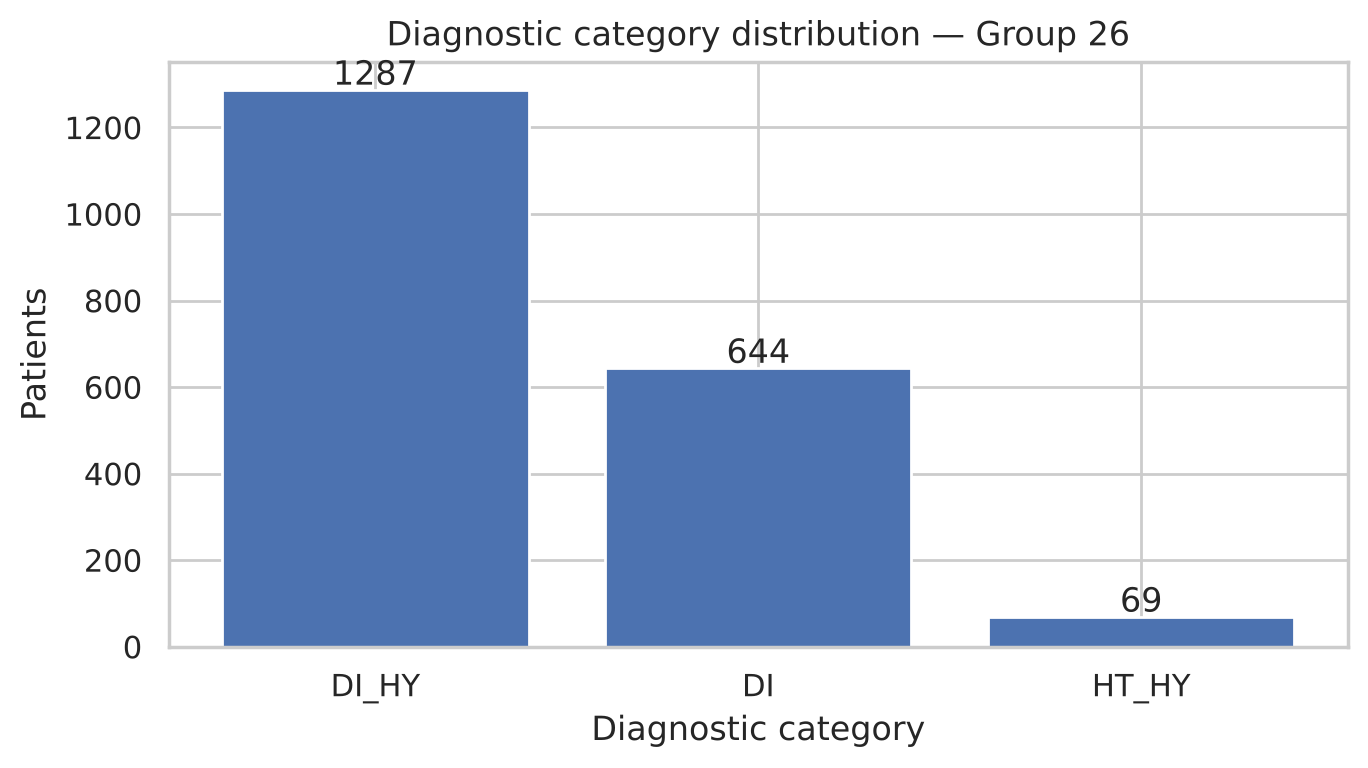

**Observed result.** The data contain **2,000 records**, **35 columns**, **0 missing entries**, and **0 exact duplicate rows**. The largest class (`DI_HY`) represents **64.35%** of patients, whereas the smallest (`HT_HY`) represents only **3.45%**. A classifier predicting only the majority class would reach roughly 64.35% accuracy while failing to recognize the other diagnoses. This motivates macro-F1, balanced accuracy, and per-class recall in addition to accuracy.

In [3]:
class_counts = df['target_class'].value_counts()
class_share = (class_counts / len(df) * 100).round(2)
class_table = pd.DataFrame({'patients': class_counts, 'percentage': class_share})
display(class_table)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_counts.index.astype(str), class_counts.values)
ax.set(title='Diagnostic category distribution — Group 26', xlabel='Diagnostic category', ylabel='Patients')
for i, count in enumerate(class_counts.values):
    ax.text(i, count + 12, str(count), ha='center')
plt.tight_layout(); plt.show()
majority_share = class_share.iloc[0]
display(Markdown(f'''**Observed result.** The data contain **{len(df):,} records**, **{df.shape[1]} columns**, **{df.isna().sum().sum():,} missing entries**, and **{df.duplicated().sum()} exact duplicate rows**. The largest class (`{class_counts.index[0]}`) represents **{majority_share:.2f}%** of patients, whereas the smallest (`{class_counts.index[-1]}`) represents only **{class_share.iloc[-1]:.2f}%**. A classifier predicting only the majority class would reach roughly {majority_share:.2f}% accuracy while failing to recognize the other diagnoses. This motivates macro-F1, balanced accuracy, and per-class recall in addition to accuracy.'''))

## 2. Exploratory Data Analysis (EDA) (task 2)

**Approach.** The assignment requests three complementary forms of EDA:

1. **Univariate:** histograms for numeric clinical measures, categorical frequencies, and examination of the regression outcome.
2. **Bivariate against the continuous target:** Pearson correlations and scatterplots for numeric features; these measure *linear association*, not causation.
3. **Bivariate against the diagnostic target:** class-conditional distributions and categorical contingency tables; these reveal possible group differences, including minority-class behaviour.

This exploratory analysis uses the provided dataset to describe its overall characteristics. To avoid optimistic model selection, feature rankings used later are recalculated **using training data only**.
We also compare within-class dispersions and the continuous regression outcome across categorical groups. These descriptive analyses do not constitute training-only feature selection.


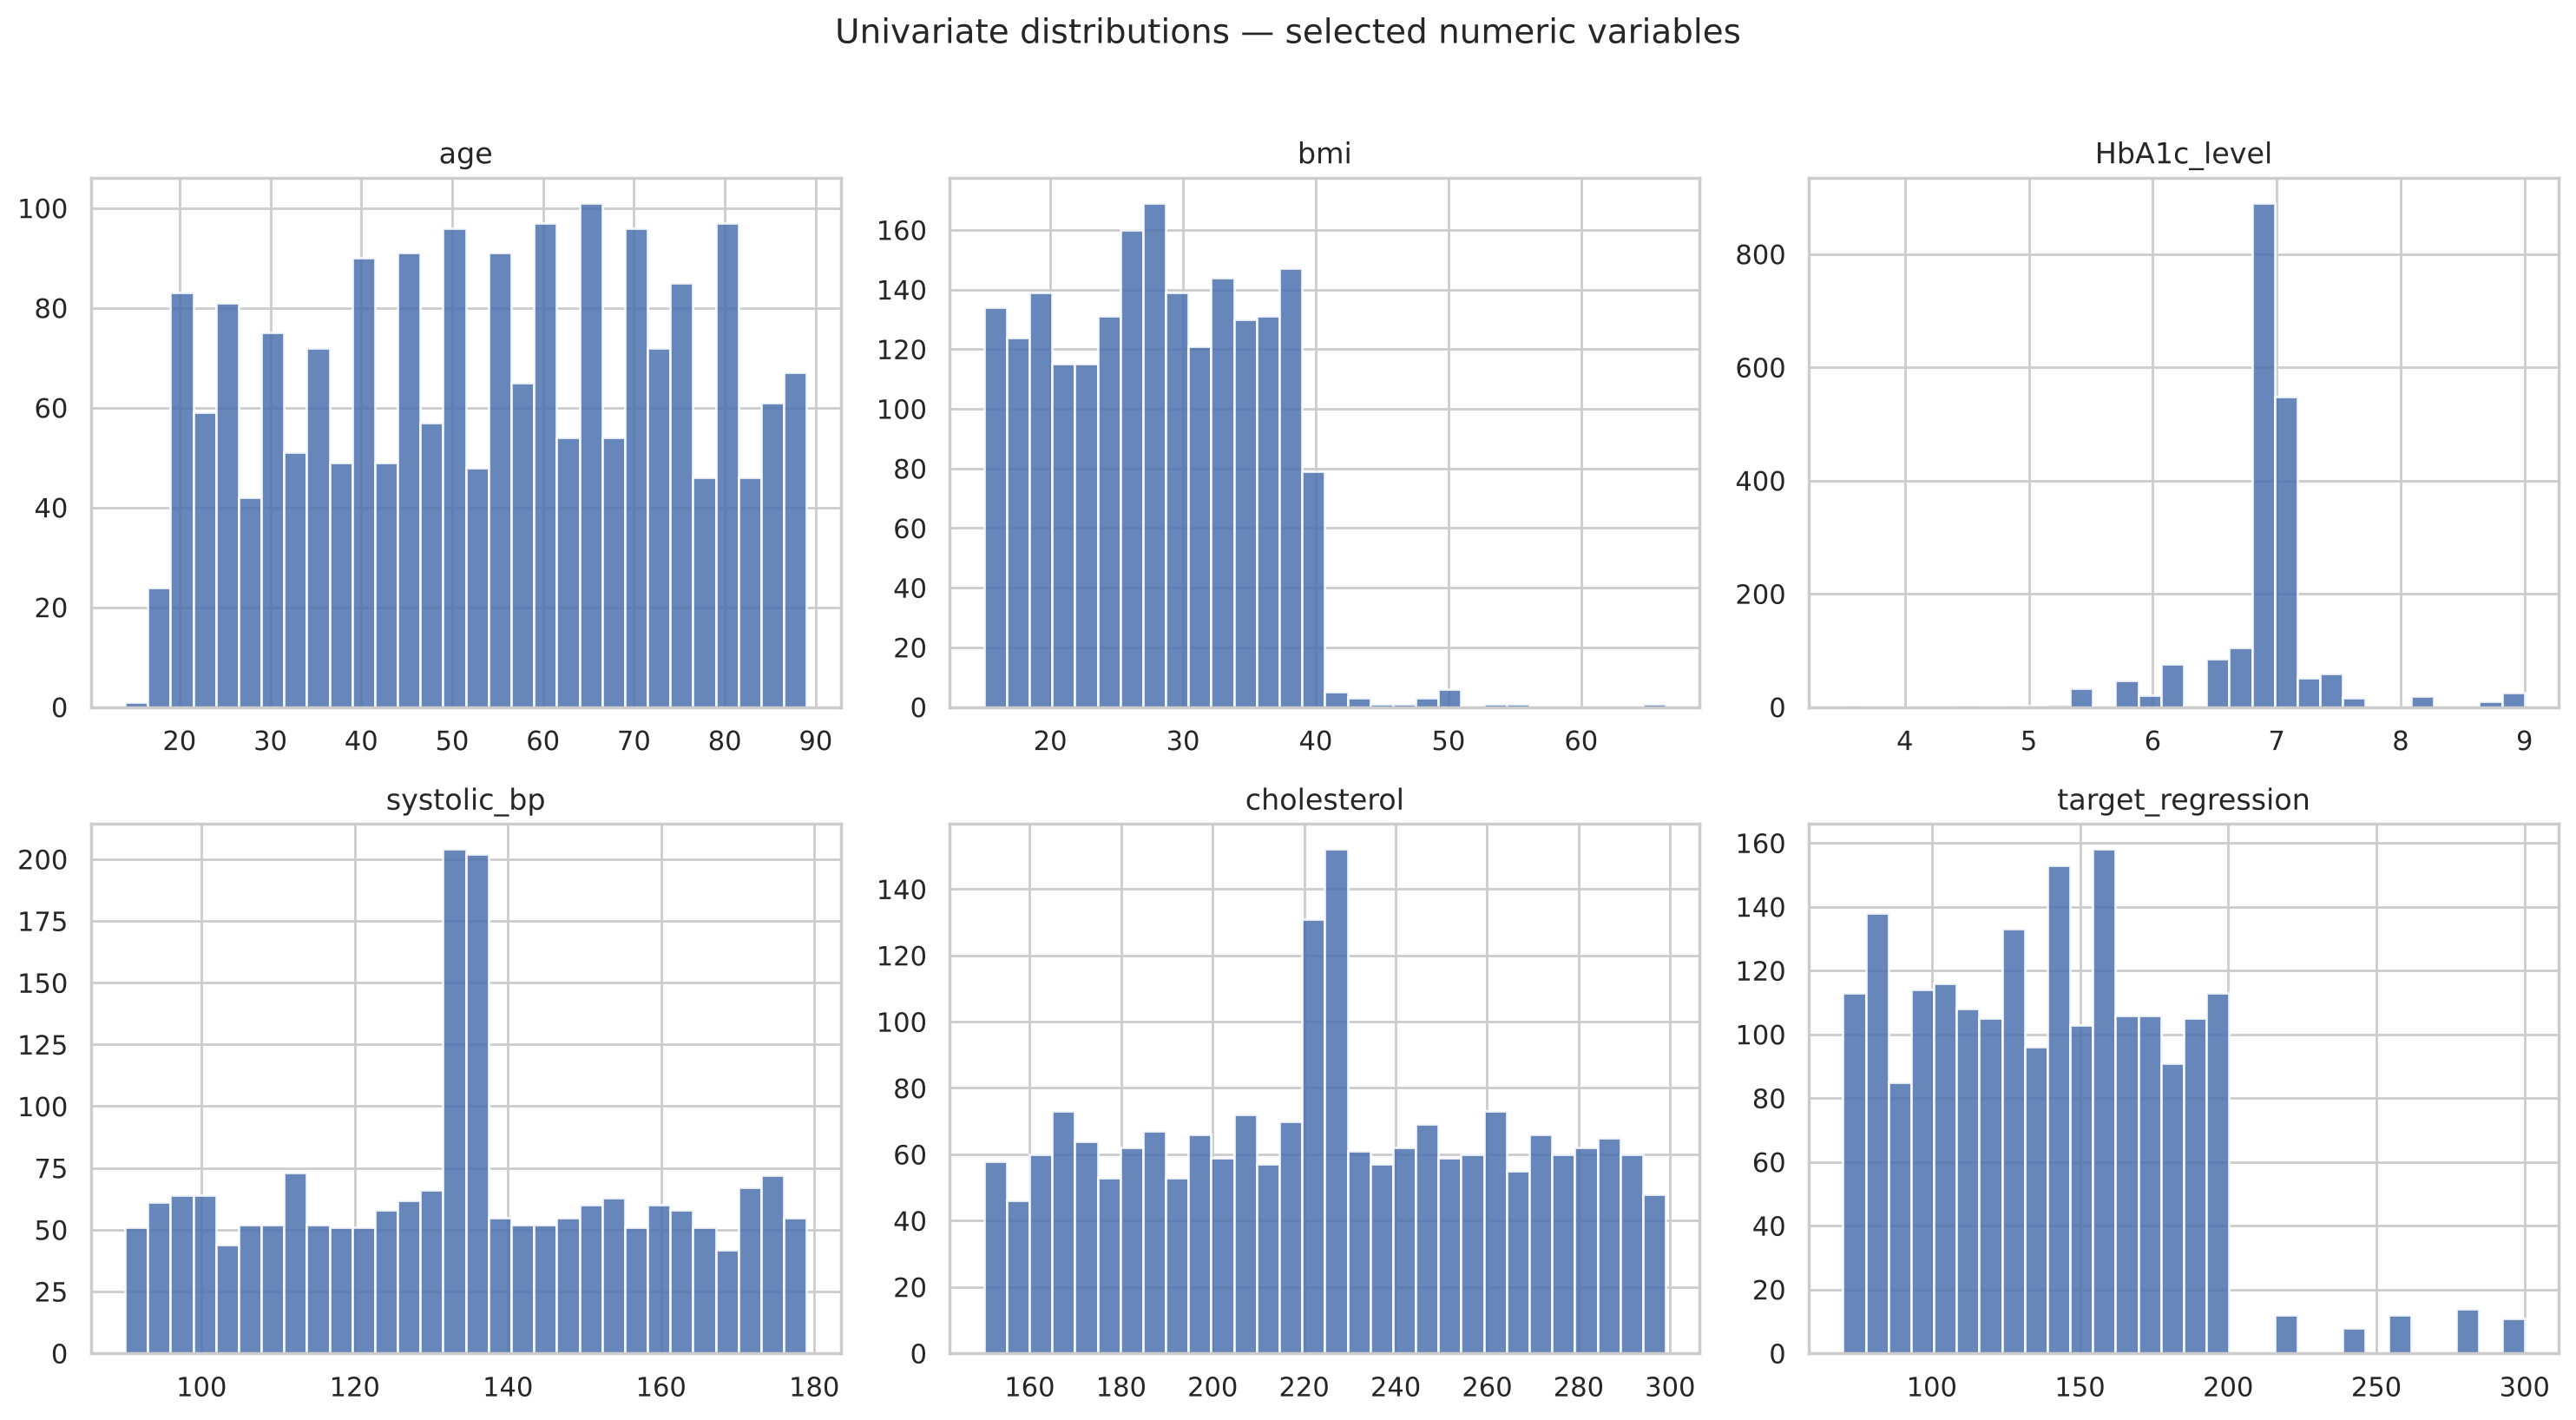

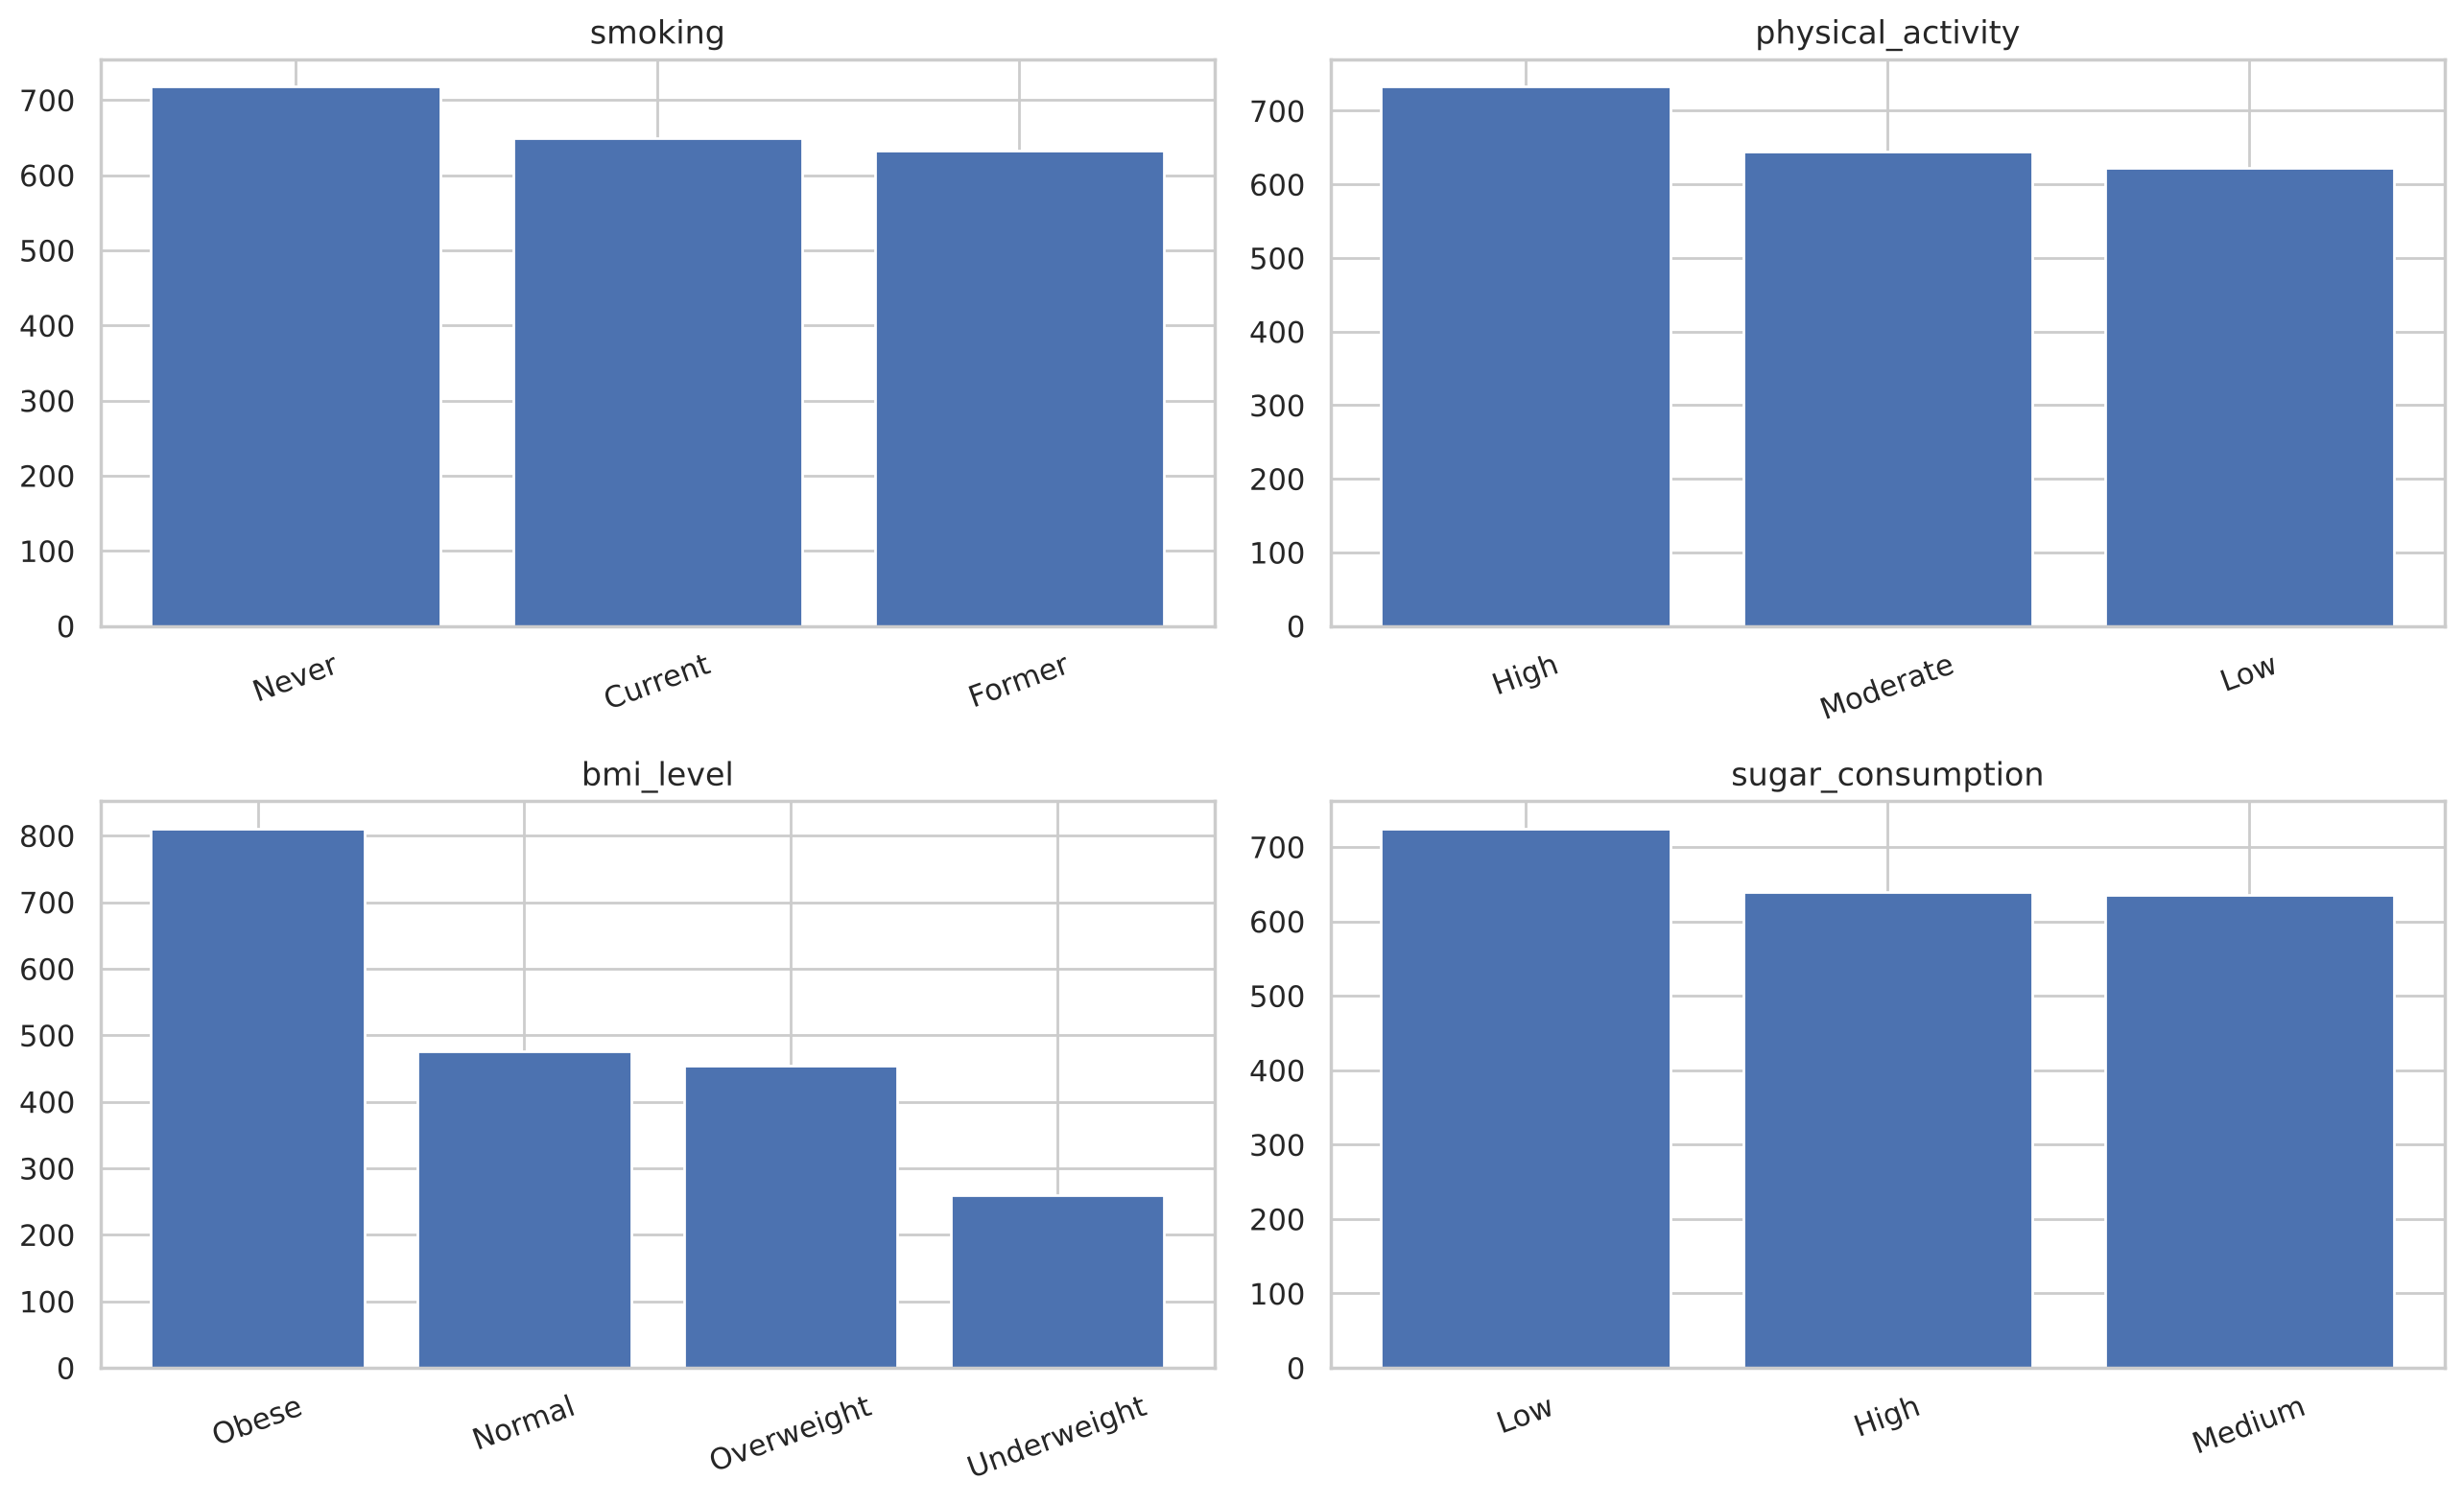

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, var in zip(axs.ravel(), ['age','bmi','HbA1c_level','systolic_bp','cholesterol','target_regression']):
    ax.hist(df[var], bins=30, edgecolor='white', alpha=0.85)
    ax.set_title(var)
plt.suptitle('Univariate distributions — selected numeric variables', y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

cats = ['smoking', 'physical_activity', 'bmi_level', 'sugar_consumption']
fig, axs = plt.subplots(2, 2, figsize=(13, 8))
for ax, var in zip(axs.ravel(), cats):
    counts = df[var].value_counts(); ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(var)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

Top absolute Pearson correlations with regression target:


,Pearson r
bmi,0.0694
HbA1c_level,0.0620
triglycerides,0.0479
heart_rate,-0.0306
homocysteine_level,0.0256
plasma_value,0.0243
hdl,0.0236
crp_level,0.0231
ldl_alternative,0.0216
ldl,-0.0175


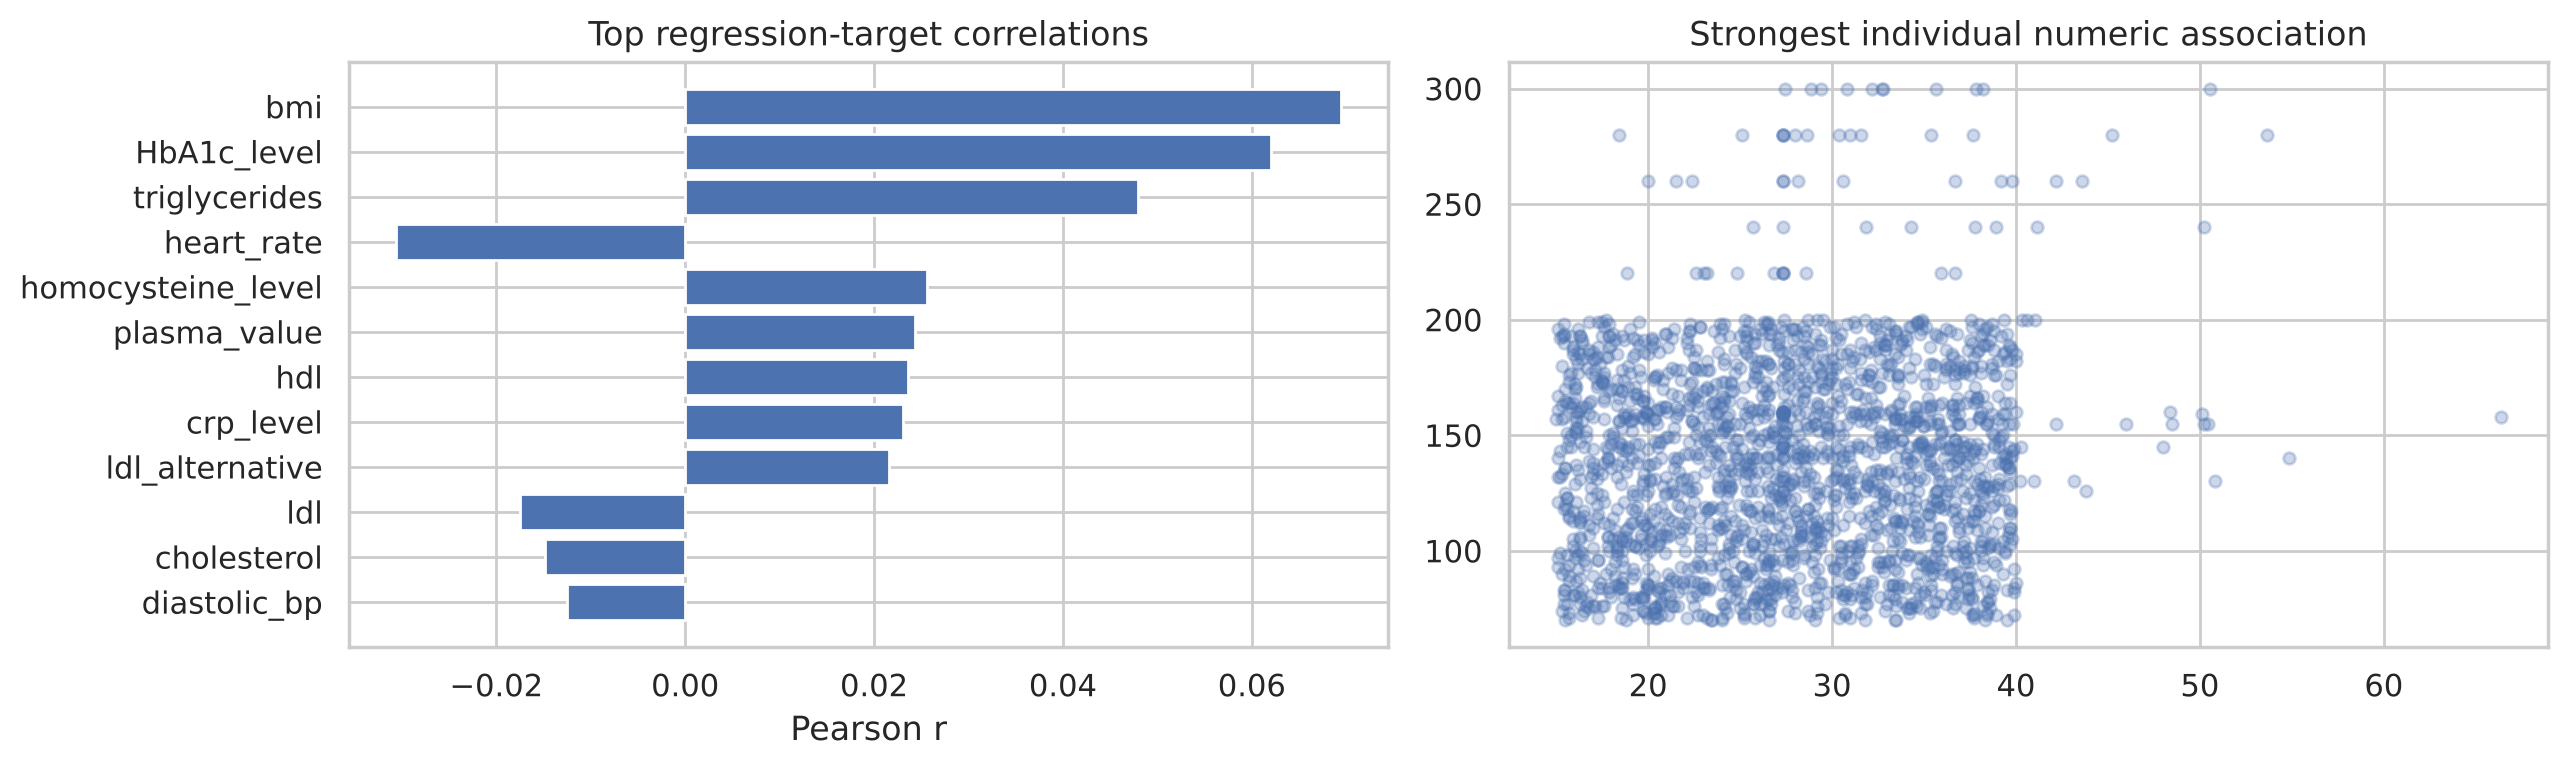

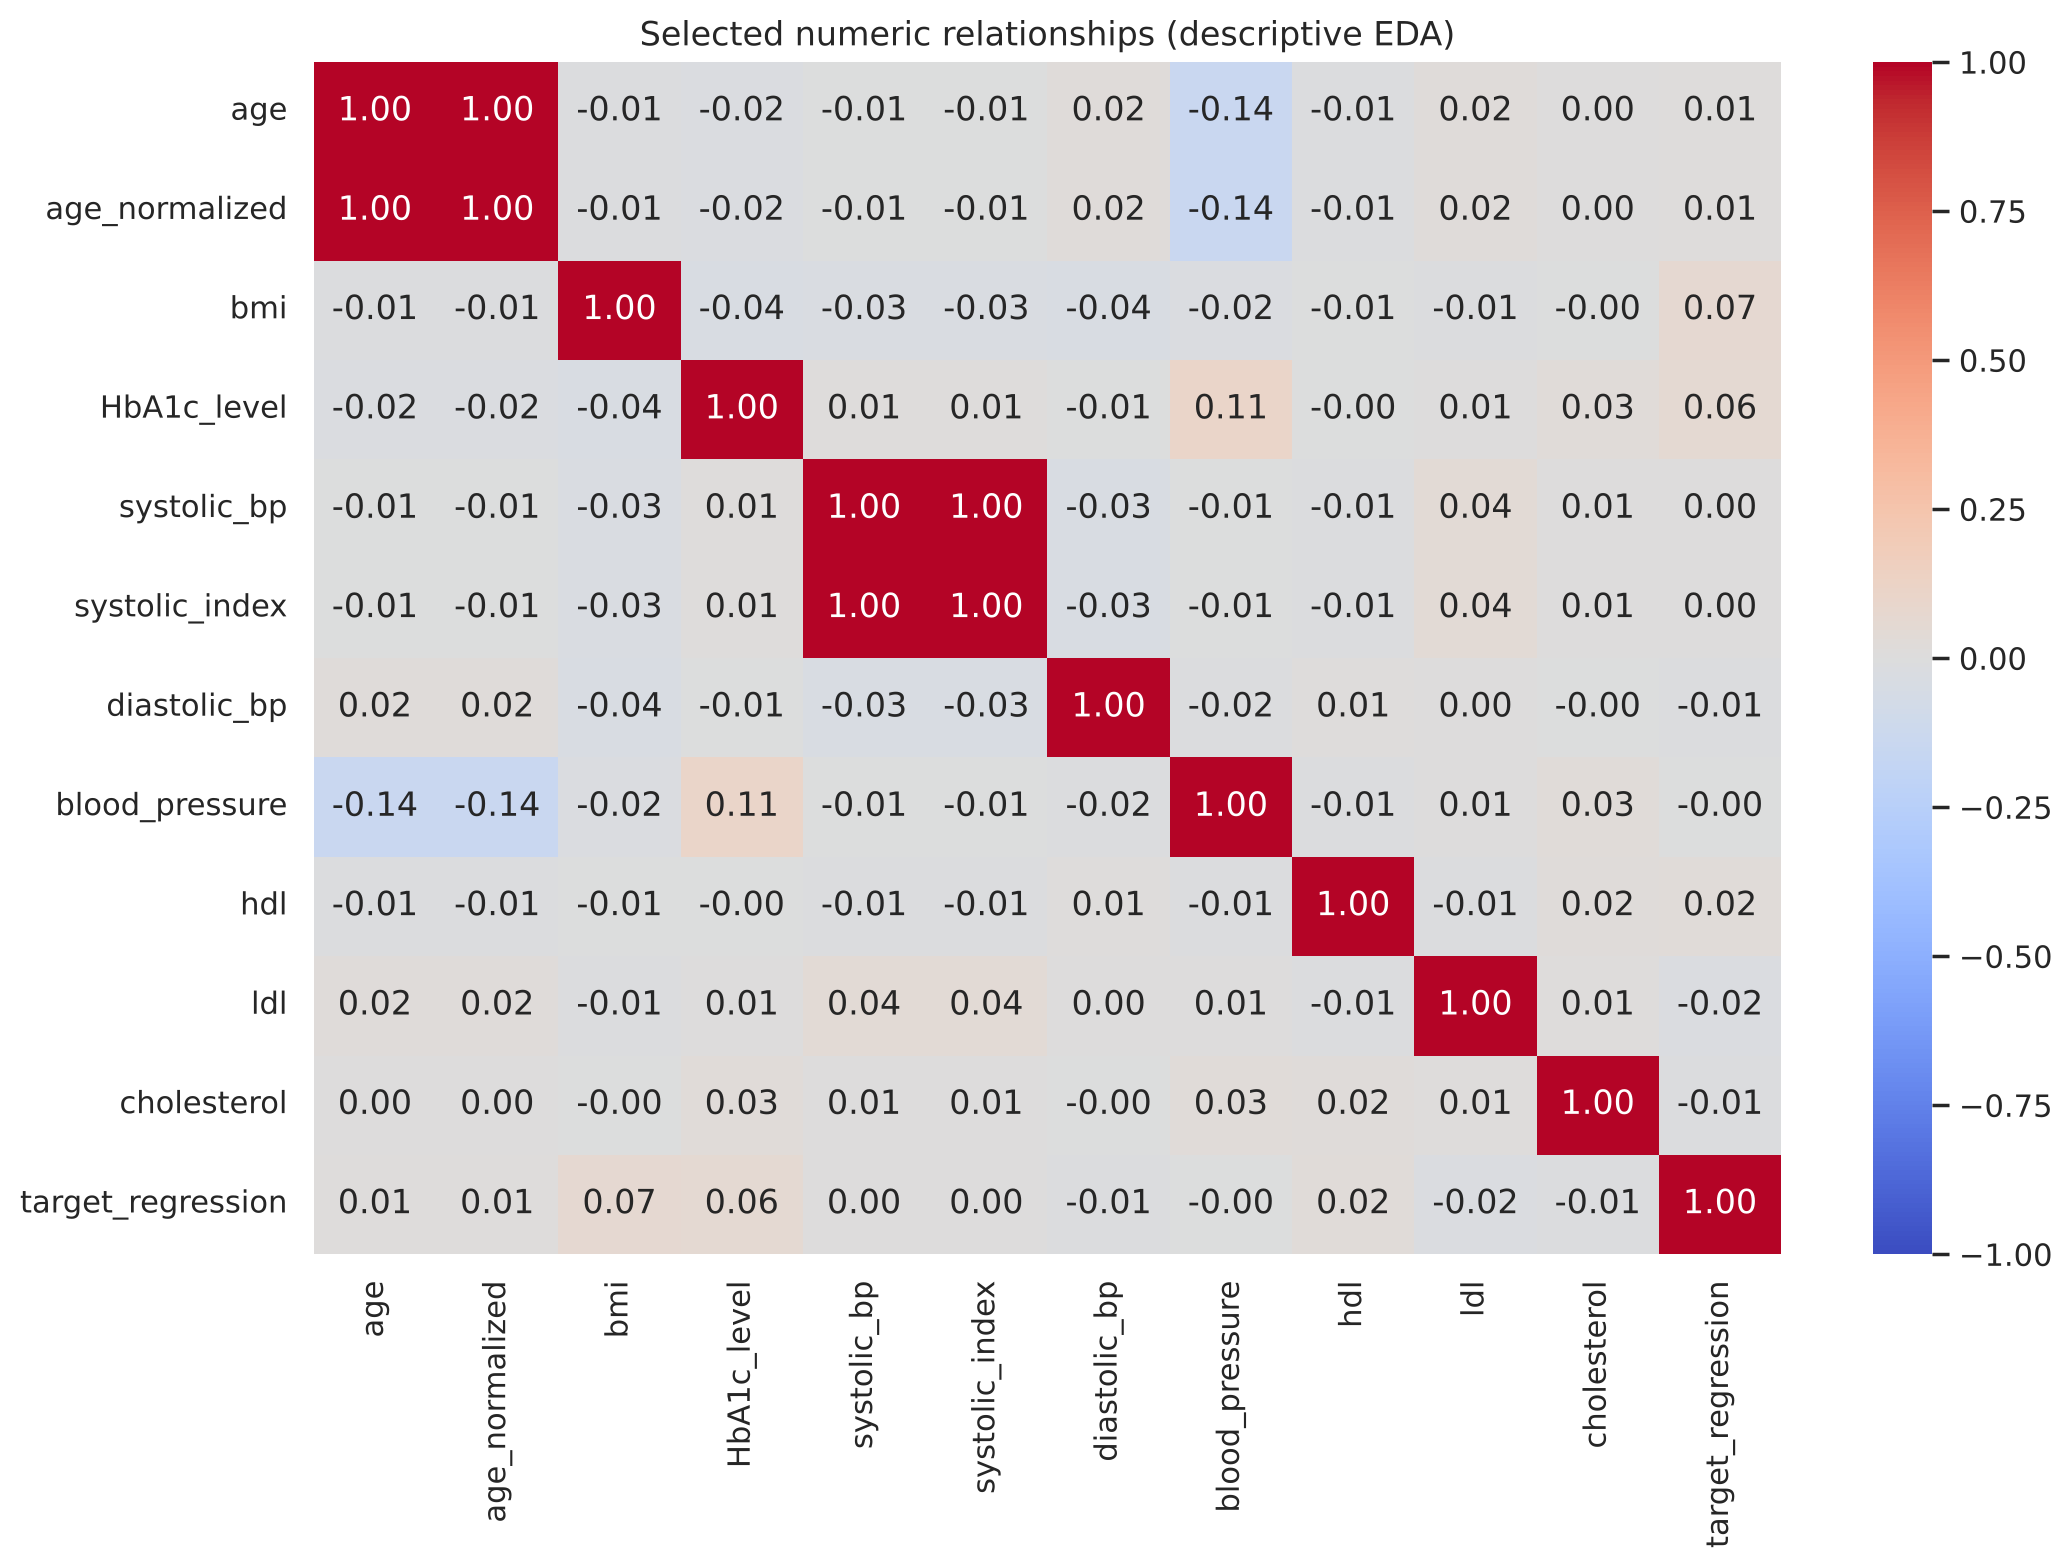

**Observed result.** The strongest measured *individual numeric* correlation with the continuous target is **`bmi` (r = +0.069)**. Its absolute value is 0.069; this provides little evidence of a strong *linear* single-feature predictor. Non-linear relationships may still exist, but the assignment specifically asks us to test linear regression. The histogram also helps establish whether outliers or marked skewness may influence squared-error-based models.

In [5]:
numeric = df.select_dtypes(include='number')
reg_corr = numeric.corr(numeric_only=True)['target_regression'].drop('target_regression').dropna()
rank_corr = reg_corr.reindex(reg_corr.abs().sort_values(ascending=False).index)
print('Top absolute Pearson correlations with regression target:')
display(rank_corr.head(12).rename('Pearson r').to_frame().round(4))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].barh(rank_corr.head(12).index[::-1], rank_corr.head(12).values[::-1])
axs[0].set(xlabel='Pearson r', title='Top regression-target correlations')
axs[1].scatter(df[rank_corr.index[0]], df['target_regression'], alpha=.28, s=18)
axs[1].set(title='Strongest individual numeric association')
plt.tight_layout(); plt.show()

corr_mat = df[['age','age_normalized','bmi','HbA1c_level','systolic_bp',
               'systolic_index','diastolic_bp','blood_pressure','hdl','ldl',
               'cholesterol','target_regression']].corr()
plt.figure(figsize=(11, 8)); sns.heatmap(corr_mat, cmap='coolwarm', vmin=-1, vmax=1,
                                         center=0, annot=True, fmt='.2f')
plt.title('Selected numeric relationships (descriptive EDA)'); plt.tight_layout(); plt.show()
strongest_corr = rank_corr.iloc[0]
display(Markdown(f'''**Observed result.** The strongest measured *individual numeric* correlation with the continuous target is **`{rank_corr.index[0]}` (r = {strongest_corr:+.3f})**. Its absolute value is {abs(strongest_corr):.3f}; this provides little evidence of a strong *linear* single-feature predictor. Non-linear relationships may still exist, but the assignment specifically asks us to test linear regression. The histogram also helps establish whether outliers or marked skewness may influence squared-error-based models.'''))

### 2.1 Categorical predictors versus the continuous regression target

**Approach.** Pearson correlations describe linear relationships between numeric variables. We complement that view with eta-squared (η²) for the relationships between each categorical predictor and the continuous laboratory target. Eta-squared is the share of total outcome variance attributable to differences between group means in this dataset; it does not by itself provide causal explanations or independent test-set predictive performance.

,Eta squared
bmi_level,0.00648
education_level,0.00505
physical_activity,0.00444
age_level,0.00297
family_history,0.00205
smoking,0.00172
sugar_consumption,0.00061
stress_level,0.00044
employment_status,0.00043
gender,0.00012


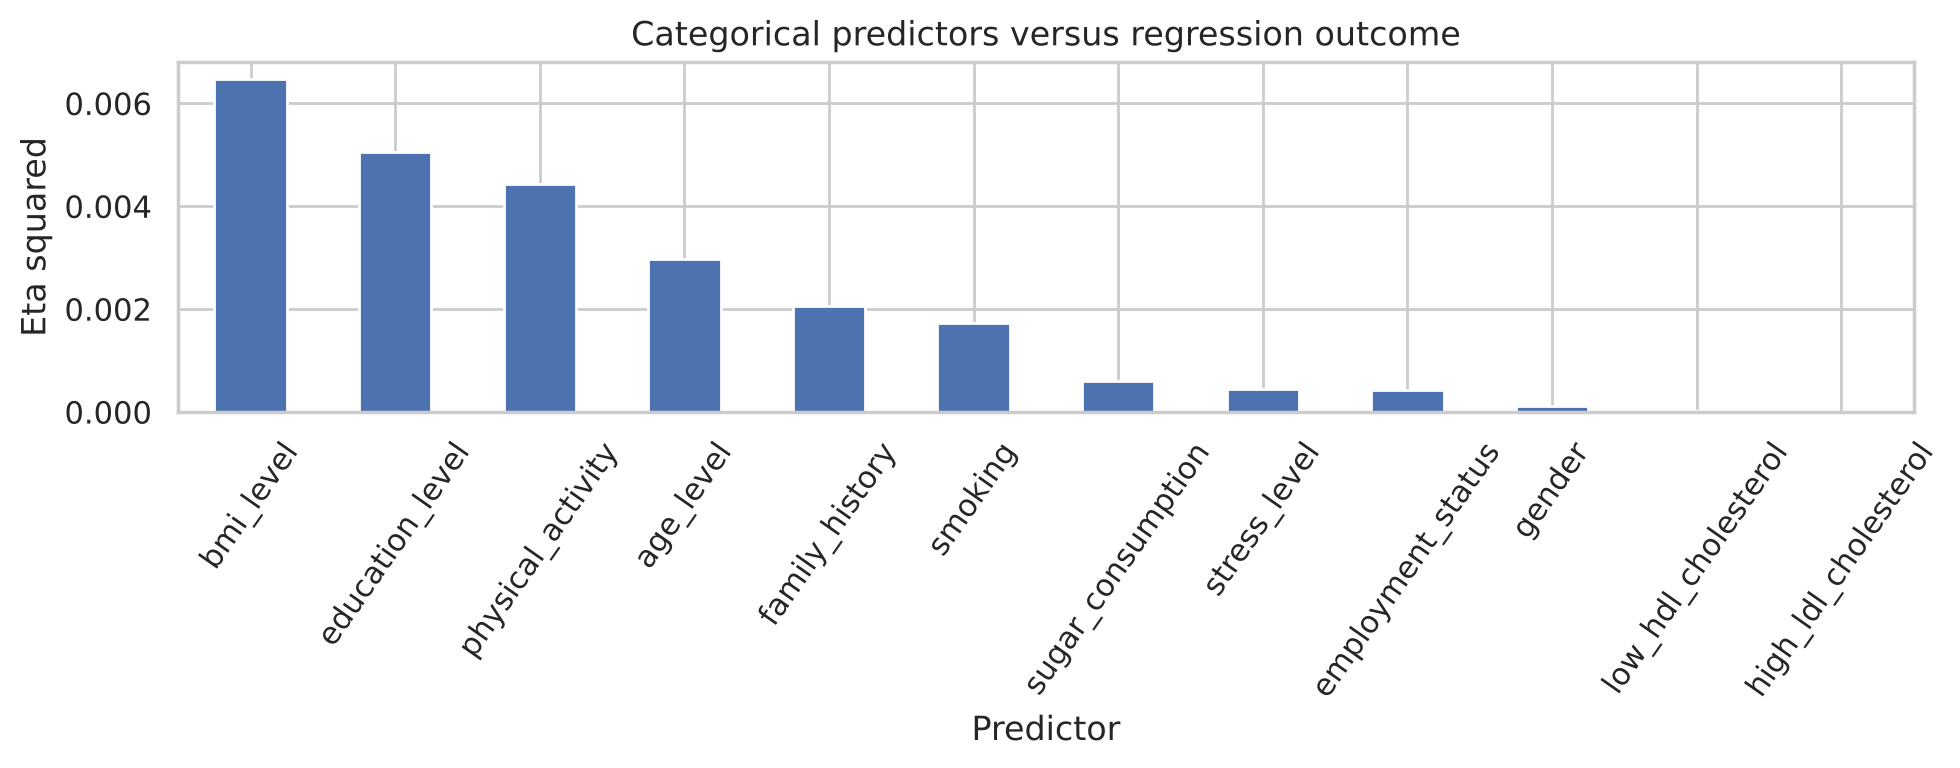

**Interpretation.** The strongest observed categorical association was **bmi_level** (eta-squared **0.0065**). All displayed measures are descriptive associations within this data subset. Low eta-squared means that category-specific means account for very little of the total variation of the regression target; it does not rule out nonlinear or combined effects.

In [6]:
# Complement Pearson correlations with descriptive group comparisons for categorical predictors.
def eta_squared(category, target):
    valid = pd.DataFrame({'cat': category, 'target': target}).dropna()
    if valid.empty:
        return np.nan
    overall = valid['target'].mean()
    total_ss = ((valid['target'] - overall)**2).sum()
    between_ss = sum(len(g) * (g['target'].mean() - overall)**2
                     for _, g in valid.groupby('cat', observed=True))
    return between_ss / total_ss if total_ss > 0 else np.nan

categorical_features = df.select_dtypes(exclude='number').columns.drop('target_class')
eta_results = pd.Series({col: eta_squared(df[col], df['target_regression'])
                         for col in categorical_features}, name='Eta squared').sort_values(ascending=False)
display(eta_results.to_frame().round(5))
fig, ax = plt.subplots(figsize=(10, 4))
eta_results.plot(kind='bar', ax=ax)
ax.set(title='Categorical predictors versus regression outcome', ylabel='Eta squared', xlabel='Predictor')
ax.tick_params(axis='x', rotation=55)
plt.tight_layout(); plt.show()
display(Markdown(f'''**Interpretation.** The strongest observed categorical association was **{eta_results.index[0]}** (eta-squared **{eta_results.iloc[0]:.4f}**). All displayed measures are descriptive associations within this data subset. Low eta-squared means that category-specific means account for very little of the total variation of the regression target; it does not rule out nonlinear or combined effects.'''))

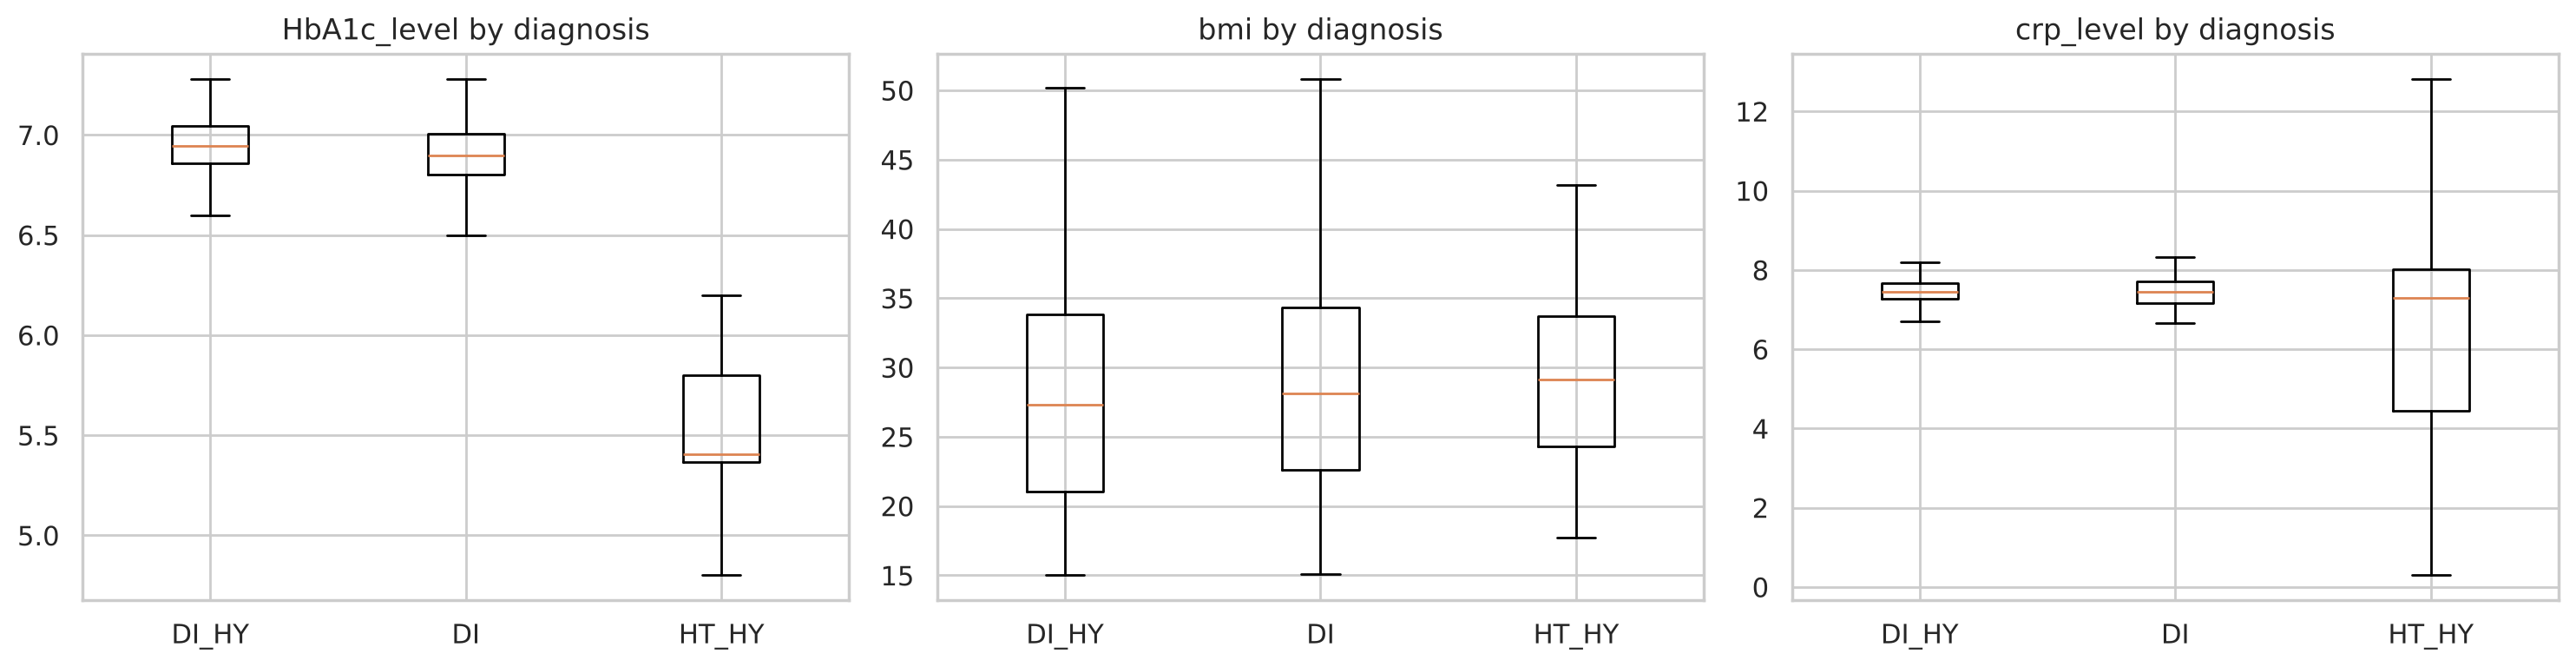

,categorical feature,chi2,p_value,min expected count
7,low_hdl_cholesterol,62.04186,0.00000,12.5925
3,smoking,22.17431,0.00019,21.8385
9,sugar_consumption,14.93564,0.00484,21.9420
10,education_level,13.20212,0.01033,22.7355
2,bmi_level,11.05033,0.08683,8.9355
0,age_level,9.43298,0.15065,5.7615
4,physical_activity,5.41248,0.24753,21.4935
6,stress_level,4.91180,0.29647,22.4250
5,family_history,1.78871,0.40887,34.2930
8,high_ldl_cholesterol,1.68975,0.42961,33.7065


age           bmi       HbA1c_level       systolic_bp         \
               mean    std   mean   std        mean   std        mean    std   
target_class                                                                   
DI            53.64  19.65  28.36  7.56        6.91  0.53      133.70  23.35   
DI_HY         53.54  20.50  27.56  7.30        6.95  0.36      135.12  25.15   
HT_HY         56.67  17.85  29.61  8.24        5.52  0.59      134.39   0.64   

             crp_level        
                  mean   std  
target_class                  
DI                7.39  1.25  
DI_HY             7.35  1.00  
HT_HY             6.76  3.60

**Interpretation.** The boxplots reveal how patient measurements overlap across the three diagnosis categories; separation must be confirmed by predictive validation. Chi-square p-values are exploratory association tests, **not** evidence that a feature causes disease or that it will improve out-of-sample predictions. Small expected contingency counts, multiple comparisons and the small `HT_HY` class limit significance-based conclusions.

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ['HbA1c_level', 'bmi', 'crp_level']):
    ax.boxplot([df.loc[df.target_class==cl,var] for cl in class_counts.index], tick_labels=class_counts.index, showfliers=False)
    ax.set_title(f'{var} by diagnosis')
plt.tight_layout(); plt.show()

# Categorical bivariate analysis: chi-square tests are descriptive here.
rows = []
for column in df.select_dtypes(exclude='number').columns.drop('target_class'):
    contingency = pd.crosstab(df[column], df['target_class'])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    rows.append({'categorical feature': column, 'chi2': chi2, 'p_value': p_value,
                 'min expected count': expected.min()})
chi_table = pd.DataFrame(rows).sort_values('p_value')
display(chi_table.round(5))

# Complementary numeric comparison by diagnostic class (descriptive, not causal).
num_by_class = df.groupby('target_class')[['age','bmi','HbA1c_level','systolic_bp','crp_level']].agg(['mean','std'])
display(num_by_class.round(2))
display(Markdown('''**Interpretation.** The boxplots reveal how patient measurements overlap across the three diagnosis categories; separation must be confirmed by predictive validation. Chi-square p-values are exploratory association tests, **not** evidence that a feature causes disease or that it will improve out-of-sample predictions. Small expected contingency counts, multiple comparisons and the small `HT_HY` class limit significance-based conclusions.'''))

### 2.2 Unusual within-class variability and possible data-source artefacts

**Approach.** The assignment asks us to identify features that may be uninformative, constant or redundant. Beyond global constant features, we inspect within-class standard deviations for clinical measurements. Markedly different dispersions can provide an artificial discrimination signal and challenge LDA's common-covariance assumption. The source of any anomaly cannot be inferred conclusively from these data.

target_class,DI,DI_HY,HT_HY
systolic_bp,23.35,25.15,0.64
diastolic_bp,15.67,16.75,0.45
heart_rate,12.71,14.11,0.36
hdl,18.02,19.44,0.59
ldl,30.46,33.72,1.10
salt_intake,3.18,3.67,0.10
alcohol_intake,7.84,8.44,0.25
blood_pressure,4.90,4.14,14.27
crp_level,1.25,1.00,3.60
homocysteine_level,1.09,0.97,3.42


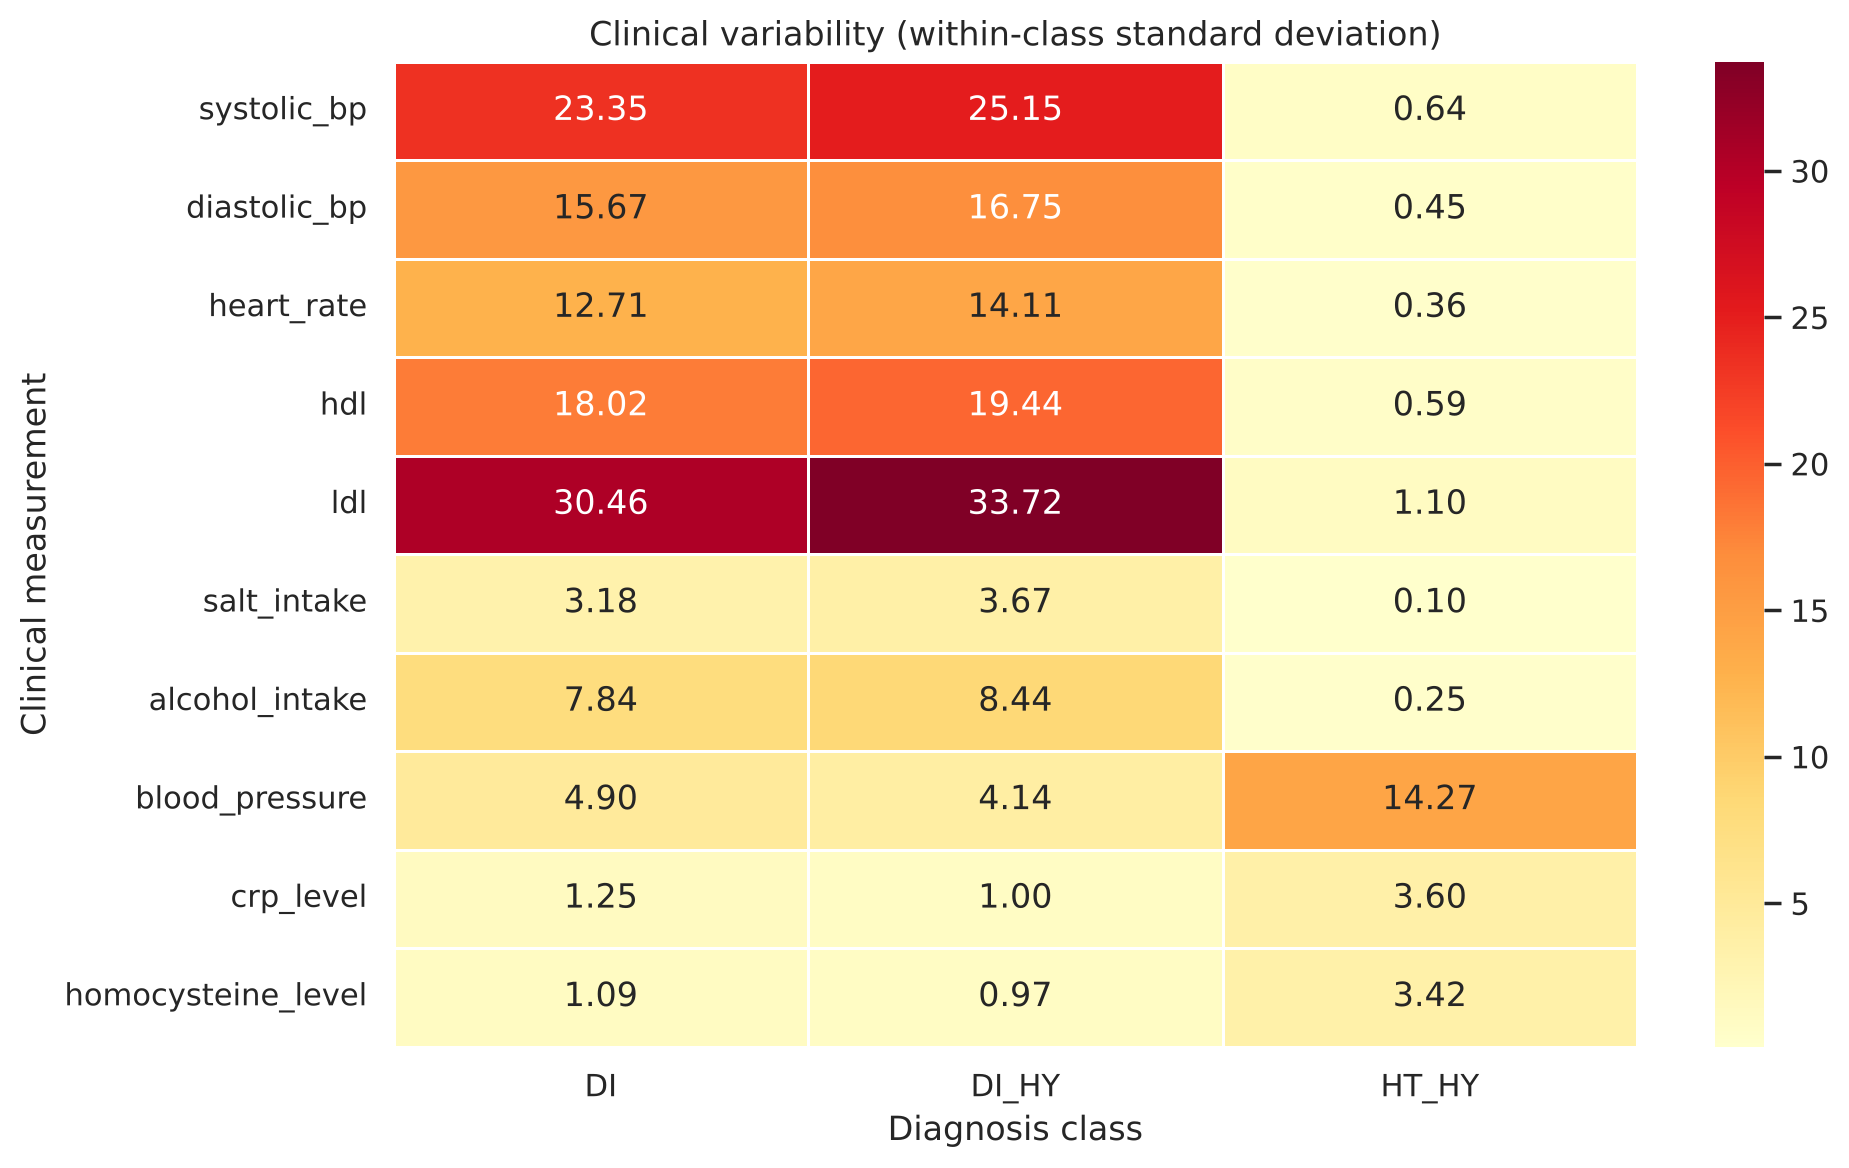

,Mean SD of DI and DI_HY / SD of HT_HY
systolic_bp,37.81
heart_rate,36.82
diastolic_bp,35.93
salt_intake,33.08
alcohol_intake,32.16
hdl,31.90
ldl,29.13
blood_pressure,0.32
crp_level,0.31
homocysteine_level,0.30


**Interpretation.** The within-class standard deviation of `systolic_bp` is **0.64** in `HT_HY`, compared with **23.35** in `DI` and **25.15** in `DI_HY`. Several other clinical features show similarly compressed dispersion in `HT_HY`, while `blood_pressure`, `crp_level` and `homocysteine_level` exhibit the reverse pattern. Section 2.2.1 traces this heterogeneity to its source: the dataset contains two disjoint sub-populations, and the compressed dispersion is a property of the one that contains every `HT_HY` patient. It raises concerns about LDA's shared-covariance assumption and about generalisation beyond the supplied cohort. Unusually low *within-class* variance is distinct from a globally constant feature and is not itself sufficient reason to drop a predictor.

In [8]:
clinical_features = [
    'systolic_bp','diastolic_bp','heart_rate','hdl','ldl',
    'salt_intake','alcohol_intake','blood_pressure','crp_level','homocysteine_level'
]
class_std = df.groupby('target_class', observed=True)[clinical_features].std().T
display(class_std.round(2))
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(class_std, annot=True, fmt='.2f', cmap='YlOrRd', linewidths=.4, ax=ax)
ax.set(title='Clinical variability (within-class standard deviation)', xlabel='Diagnosis class', ylabel='Clinical measurement')
plt.tight_layout(); plt.show()
other_classes = [c for c in class_std if c != 'HT_HY']
sd_ratio = (class_std[other_classes].mean(axis=1) / class_std['HT_HY']).sort_values(ascending=False)
display(sd_ratio.rename('Mean SD of DI and DI_HY / SD of HT_HY').to_frame().round(2))
display(Markdown(f'''**Interpretation.** The within-class standard deviation of `systolic_bp` is **{class_std.loc['systolic_bp','HT_HY']:.2f}** in `HT_HY`, compared with **{class_std.loc['systolic_bp','DI']:.2f}** in `DI` and **{class_std.loc['systolic_bp','DI_HY']:.2f}** in `DI_HY`. Several other clinical features show similarly compressed dispersion in `HT_HY`, while `blood_pressure`, `crp_level` and `homocysteine_level` exhibit the reverse pattern. Section 2.2.1 traces this heterogeneity to its source: the dataset contains two disjoint sub-populations, and the compressed dispersion is a property of the one that contains every `HT_HY` patient. It raises concerns about LDA's shared-covariance assumption and about generalisation beyond the supplied cohort. Unusually low *within-class* variance is distinct from a globally constant feature and is not itself sufficient reason to drop a predictor.'''))

### 2.2.1 Where the compressed dispersion comes from

Section 2.2 reported that several measurements lose almost all their spread inside `HT_HY`. That pattern has a checkable cause. The seven affected measurements collapse because a subset of records carries nearly the same value on all seven at once. We test for that subset directly: for each patient we average the absolute z-scores of those seven variables, standardised against the whole dataset, so a record sitting at the dataset mean on all of them scores close to zero. The diagnosis is not used anywhere in this detection.


Compressed group: 284 records, scores 0.0134 to 0.0676
Empty interval of 0.2015; dispersed group starts at 0.2690
Cut placed at 0.1683


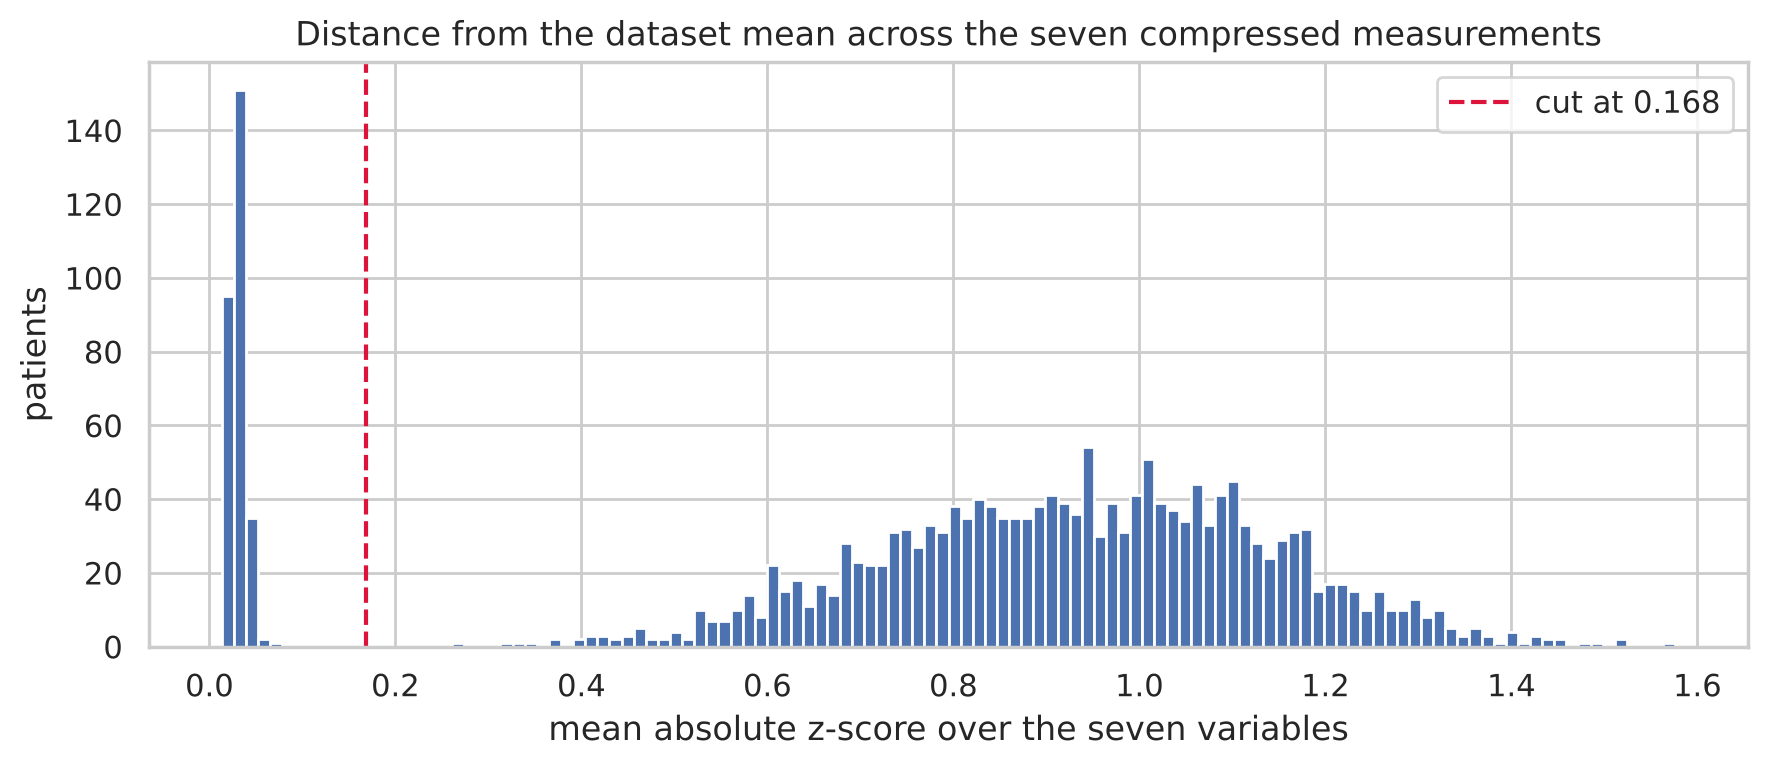

target_class,DI,DI_HY,HT_HY,All
row_0,,,,
compressed,139,76,69,284
dispersed,505,1211,0,1716
All,644,1287,69,2000


,SD compressed,SD dispersed,ratio
systolic_bp,0.765,26.060,34.083
diastolic_bp,0.448,17.397,38.870
heart_rate,0.369,14.492,39.226
hdl,0.578,20.128,34.827
ldl,0.945,34.650,36.669
salt_intake,0.117,3.726,31.942
alcohol_intake,0.216,8.747,40.575
blood_pressure,11.504,2.903,0.252
crp_level,2.836,0.731,0.258
homocysteine_level,2.704,0.648,0.240


,"SD of systolic_bp, dispersed group only"
target_class,
DI,26.36
DI_HY,25.93


**Observed result.** The score splits the cohort into two groups with nothing in
between: 284 compressed records spanning 0.0134 to 0.0676, and
1716 dispersed records starting at 0.2690. The empty interval between them measures
0.2015, which is wider than the whole compressed group, and no record falls inside it. This is
a two-population structure and not the tail of one distribution.

All 69 `HT_HY` patients sit in the compressed group, and none of the 1716 dispersed
records carries that label (69/69). The share of `HT_HY` is
0.243 inside the compressed group against 0.000 outside it, so
belonging to that group is a necessary condition for the rare diagnosis in this cohort, though far from a
sufficient one.

**This accounts for Section 2.2 with no appeal to clinical mechanism.** Among dispersed records only, the
within-class SD of `systolic_bp` is 26.36 for `DI` and 25.93 for `DI_HY`, which are ordinary
values. The collapsed dispersion we reported for `HT_HY` belongs to the sub-population that contains it
and says nothing about the diagnosis itself. The reversed pattern in `blood_pressure`, `crp_level` and
`homocysteine_level` is the same split seen from the other side.

**What we carry forward.** This is a property of how the cohort was assembled, so we treat predictive
performance on `HT_HY` as uninformative about clinical signal and qualify it in Section 9. A single pooled
covariance matrix also cannot describe two groups whose dispersions move in opposite directions, which is
the assumption LDA makes and which Section 6.3 tests. We keep all seven measurements as predictors: they
are available at prediction time, and dropping them would hide the structure instead of addressing it.

In [9]:
# Records that sit at the dataset mean on all seven compressed measurements at once.
COMPRESSED = ['systolic_bp', 'diastolic_bp', 'heart_rate', 'hdl', 'ldl',
              'salt_intake', 'alcohol_intake']

z_scores = (df[COMPRESSED] - df[COMPRESSED].mean()) / df[COMPRESSED].std()
regime_score = z_scores.abs().mean(axis=1)

# Cut at the widest empty interval in the sorted scores instead of a hand-picked value.
ordered = np.sort(regime_score.to_numpy())
gaps = np.diff(ordered)
cut_index = int(np.argmax(gaps))
low_end = ordered[cut_index]
high_start = ordered[cut_index + 1]
widest_gap = gaps[cut_index]
REGIME_CUT = (low_end + high_start) / 2
FROZEN_REGIME = regime_score < REGIME_CUT

n_compressed = int(FROZEN_REGIME.sum())
n_dispersed = int((~FROZEN_REGIME).sum())
print(f'Compressed group: {n_compressed} records, scores {ordered[0]:.4f} to {low_end:.4f}')
print(f'Empty interval of {widest_gap:.4f}; dispersed group starts at {high_start:.4f}')
print(f'Cut placed at {REGIME_CUT:.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(regime_score, bins=120)
ax.axvline(REGIME_CUT, color='crimson', ls='--', lw=1.5, label=f'cut at {REGIME_CUT:.3f}')
ax.set(title='Distance from the dataset mean across the seven compressed measurements',
       xlabel='mean absolute z-score over the seven variables', ylabel='patients')
ax.legend()
plt.tight_layout()
plt.show()

regime_label = FROZEN_REGIME.map({True: 'compressed', False: 'dispersed'})
display(pd.crosstab(regime_label, df['target_class'], margins=True))

REVERSED = ['blood_pressure', 'crp_level', 'homocysteine_level', 'HbA1c_level']
dispersion = pd.DataFrame({
    'SD compressed': df[COMPRESSED + REVERSED][FROZEN_REGIME].std(),
    'SD dispersed': df[COMPRESSED + REVERSED][~FROZEN_REGIME].std()})
dispersion['ratio'] = dispersion['SD dispersed'] / dispersion['SD compressed']
display(dispersion.round(3))

# Within-class spread once the compressed records are excluded.
sd_by_class = df[~FROZEN_REGIME].groupby('target_class', observed=True)['systolic_bp'].std()
display(sd_by_class.round(2).to_frame('SD of systolic_bp, dispersed group only'))

rare = class_counts.index[-1]
is_rare = df['target_class'] == rare
rare_total = int(is_rare.sum())
rare_compressed = int((is_rare & FROZEN_REGIME).sum())
share_rare_compressed = (df.loc[FROZEN_REGIME, 'target_class'] == rare).mean()
share_rare_dispersed = (df.loc[~FROZEN_REGIME, 'target_class'] == rare).mean()
sd_di = sd_by_class['DI']
sd_di_hy = sd_by_class['DI_HY']

display(Markdown(f"""**Observed result.** The score splits the cohort into two groups with nothing in
between: {n_compressed} compressed records spanning {ordered[0]:.4f} to {low_end:.4f}, and
{n_dispersed} dispersed records starting at {high_start:.4f}. The empty interval between them measures
{widest_gap:.4f}, which is wider than the whole compressed group, and no record falls inside it. This is
a two-population structure and not the tail of one distribution.

All {rare_total} `{rare}` patients sit in the compressed group, and none of the {n_dispersed} dispersed
records carries that label ({rare_compressed}/{rare_total}). The share of `{rare}` is
{share_rare_compressed:.3f} inside the compressed group against {share_rare_dispersed:.3f} outside it, so
belonging to that group is a necessary condition for the rare diagnosis in this cohort, though far from a
sufficient one.

**This accounts for Section 2.2 with no appeal to clinical mechanism.** Among dispersed records only, the
within-class SD of `systolic_bp` is {sd_di:.2f} for `DI` and {sd_di_hy:.2f} for `DI_HY`, which are ordinary
values. The collapsed dispersion we reported for `{rare}` belongs to the sub-population that contains it
and says nothing about the diagnosis itself. The reversed pattern in `blood_pressure`, `crp_level` and
`homocysteine_level` is the same split seen from the other side.

**What we carry forward.** This is a property of how the cohort was assembled, so we treat predictive
performance on `{rare}` as uninformative about clinical signal and qualify it in Section 9. A single pooled
covariance matrix also cannot describe two groups whose dispersions move in opposite directions, which is
the assumption LDA makes and which Section 6.3 tests. We keep all seven measurements as predictors: they
are available at prediction time, and dropping them would hide the structure instead of addressing it."""))


### 2.3 Data quality, constant and redundant variables

**Approach.** We explicitly inspect constant columns and exact/highly correlated duplicates, because such features add no information or cause multicollinearity. For the fair comparison in later experiments, we retain all **non-redundant** predictors and document exclusions; there is no undisclosed manual deletion on the basis of test results.
We additionally inspect category encodings derived from continuous predictors and test whether a binary clinical indicator is consistent with a simple threshold rule.


In [10]:
predictors = df.drop(columns=['target_class','target_regression'])
constant_cols = predictors.columns[predictors.nunique(dropna=False) <= 1].tolist()
numeric_pred = predictors.select_dtypes(include='number')
abs_corr = numeric_pred.corr().abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
near_identical_pairs = [(c, r, round(float(upper.loc[r,c]), 6))
                        for c in upper for r in upper.index if pd.notna(upper.loc[r,c])
                        and upper.loc[r,c] > 0.99999]
print('Constant predictors:', constant_cols)
print('Near-perfect numeric correlations:', near_identical_pairs)
print('Exact equality systolic_index == systolic_bp:', bool(df['systolic_index'].equals(df['systolic_bp'])))
print('age vs age_normalized Pearson r:', round(df['age'].corr(df['age_normalized']), 8))
# Retain age (years) and systolic_bp (direct measurement).
REMOVED = ['calcium_baseline', 'age_normalized', 'systolic_index']
MODEL_FEATURES = [c for c in predictors.columns if c not in REMOVED]
assert all(x in predictors.columns for x in REMOVED)
print('Original predictors:', predictors.shape[1], '| Model predictors:', len(MODEL_FEATURES))
display(Markdown('''**Decision.** We remove `calcium_baseline` (constant), `systolic_index` (an exact duplicate of `systolic_bp`) and `age_normalized` (an almost exact linear rescaling of `age`). These three exclusions are based on structural redundancy, not validation performance. All remaining predictors are retained for the full-feature classification baseline. We preserve real-world variables `age` and `systolic_bp` to aid interpretation.'''))
print('Observed age intervals per age_level:')
display(df.groupby('age_level', observed=True)['age'].agg(['min','max','nunique']))
print('Observed BMI intervals per bmi_level:')
display(df.groupby('bmi_level', observed=True)['bmi'].agg(['min','max','nunique']))
hdl_mismatch = df[(df['low_hdl_cholesterol'].astype(str).str.strip().str.lower() == 'yes') & (df['hdl'] >= 40)]
print('low_hdl_cholesterol == Yes while hdl >= 40:', len(hdl_mismatch))
display(hdl_mismatch[['hdl','gender','low_hdl_cholesterol']].describe(include='all'))
display(Markdown('''**Additional data-quality observations.** `age_level` and `bmi_level` partition existing continuous measures into categories: they are derived, redundant representations, although they may help a linear classifier express threshold effects. We retain them for the full model and note this limitation. The `low_hdl_cholesterol` flag is not equivalent to a simple `hdl < 40` threshold in the supplied records. Without a documented flag-construction rule, these observations are not automatically deleted or relabelled.'''))


Constant predictors: ['calcium_baseline']
Near-perfect numeric correlations: [('age_normalized', 'age', 1.0), ('systolic_index', 'systolic_bp', 1.0)]
Exact equality systolic_index == systolic_bp: True
age vs age_normalized Pearson r: 1.0
Original predictors: 33 | Model predictors: 30


**Decision.** We remove `calcium_baseline` (constant), `systolic_index` (an exact duplicate of `systolic_bp`) and `age_normalized` (an almost exact linear rescaling of `age`). These three exclusions are based on structural redundancy, not validation performance. All remaining predictors are retained for the full-feature classification baseline. We preserve real-world variables `age` and `systolic_bp` to aid interpretation.

Observed age intervals per age_level:


,min,max,nunique
age_level,,,
Mature,46,67,22
Middle,24,45,22
Senior,68,89,22
Young,14,23,8


Observed BMI intervals per bmi_level:


,min,max,nunique
bmi_level,,,
Normal,18.5,24.929383,111
Obese,30.0,66.360000,229
Overweight,25.0,29.990000,105
Underweight,15.0,18.440000,40


low_hdl_cholesterol == Yes while hdl >= 40: 115


,hdl,gender,low_hdl_cholesterol
count,115.000000,115,115
unique,NaN,2,1
top,NaN,Female,Yes
freq,NaN,66,115
mean,64.590078,NaN,NaN
std,0.612378,NaN,NaN
min,62.057026,NaN,NaN
25%,64.331368,NaN,NaN
50%,64.643022,NaN,NaN
75%,64.818497,NaN,NaN


**Additional data-quality observations.** `age_level` and `bmi_level` partition existing continuous measures into categories: they are derived, redundant representations, although they may help a linear classifier express threshold effects. We retain them for the full model and note this limitation. The `low_hdl_cholesterol` flag is not equivalent to a simple `hdl < 40` threshold in the supplied records. Without a documented flag-construction rule, these observations are not automatically deleted or relabelled.

## 3. Experimental protocol and leakage prevention

**Approach.** We reserve **20%** of patients as a common final holdout set and use the other **80%** for selecting models and comparing resampling strategies. Stratifying by diagnostic class ensures the small class is represented in both sets; using the same patients for regression and classification makes the experiments reproducible. The holdout is not used for selecting features, hyperparameters or the preferred algorithm. Training-only cross-validation employs 5 or 10 folds as indicated below.

Numerical predictors are median-imputed and standardized; categorical predictors are mode-imputed and one-hot encoded. Although the supplied CSV has no missing values, the imputation makes the workflow robust. Fitting these transformations inside each CV fold prevents information from the validation fold from influencing preprocessing.

In [11]:
indices = np.arange(len(df))
train_ids, test_ids = train_test_split(indices, test_size=.20, stratify=df['target_class'], random_state=SEED)
X_train = df.loc[train_ids, MODEL_FEATURES].copy()
X_test = df.loc[test_ids, MODEL_FEATURES].copy()
yreg_train = df.loc[train_ids, 'target_regression'].copy()
yreg_test = df.loc[test_ids, 'target_regression'].copy()
ycls_train = df.loc[train_ids, 'target_class'].copy()
ycls_test = df.loc[test_ids, 'target_class'].copy()
assert not set(train_ids).intersection(set(test_ids))
print('Train:', len(train_ids), '| Holdout:', len(test_ids), '\nTraining diagnosis frequencies:')
display(ycls_train.value_counts().to_frame('patients'))
print('Holdout diagnosis frequencies:')
display(ycls_test.value_counts().to_frame('patients'))

def preprocessor(feature_frame):
    numeric_cols = feature_frame.select_dtypes(include='number').columns.tolist()
    categorical_cols = feature_frame.select_dtypes(exclude='number').columns.tolist()
    steps = []
    if numeric_cols:
        steps.append(('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())]), numeric_cols))
    if categorical_cols:
        steps.append(('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
        ]), categorical_cols))
    return ColumnTransformer(steps, remainder='drop', sparse_threshold=0)

def full_pipeline(features, estimator):
    return Pipeline([('prepare', preprocessor(features)), ('model', estimator)])

reg_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cls_cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cls_cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
reg_scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}
cls_scoring = {'accuracy': 'accuracy','balanced_accuracy': 'balanced_accuracy','macro_f1': 'f1_macro'}

Train: 1600 | Holdout: 400 
Training diagnosis frequencies:


,patients
target_class,
DI_HY,1030
DI,515
HT_HY,55


Holdout diagnosis frequencies:


,patients
target_class,
DI_HY,257
DI,129
HT_HY,14


## 4. Regression: simple linear model (task 3)

**Research question.** Can a single patient characteristic predict `target_regression`? **Approach.** We fit a separate ordinary least-squares model for every available numeric predictor, comparing **training-only 5-fold CV RMSE**. This avoids arbitrarily selecting the feature that looks best in the full dataset. Our comparator is a dummy regressor that always predicts the training mean. We will assess the best simple model once on the untouched holdout set.

For one predictor, the fitted relationship is \(\hat y = \beta_0 + \beta_1 x\). Lower RMSE/MAE and higher R² indicate better generalisation. R² can be negative on holdout data, meaning the model performs worse than a constant mean-based reference on that set.

,feature,CV RMSE,CV MAE,CV R2,CV RMSE sd
0,bmi,43.0517,34.9817,-0.0009,2.5482
1,HbA1c_level,43.0755,34.9475,-0.0021,2.4860
2,crp_level,43.1149,34.9633,-0.0037,2.6105
3,hdl,43.1162,34.9391,-0.0037,2.6205
4,heart_rate,43.1195,34.9872,-0.0039,2.6032
5,triglycerides,43.1196,34.9967,-0.0041,2.5208
6,sleep_hours,43.1256,34.9742,-0.0042,2.6126
7,homocysteine_level,43.1261,34.9515,-0.0042,2.6136
8,alcohol_intake,43.1274,34.9656,-0.0043,2.6146
9,salt_intake,43.1288,34.9816,-0.0043,2.6140


Selected simple predictor (training CV): bmi


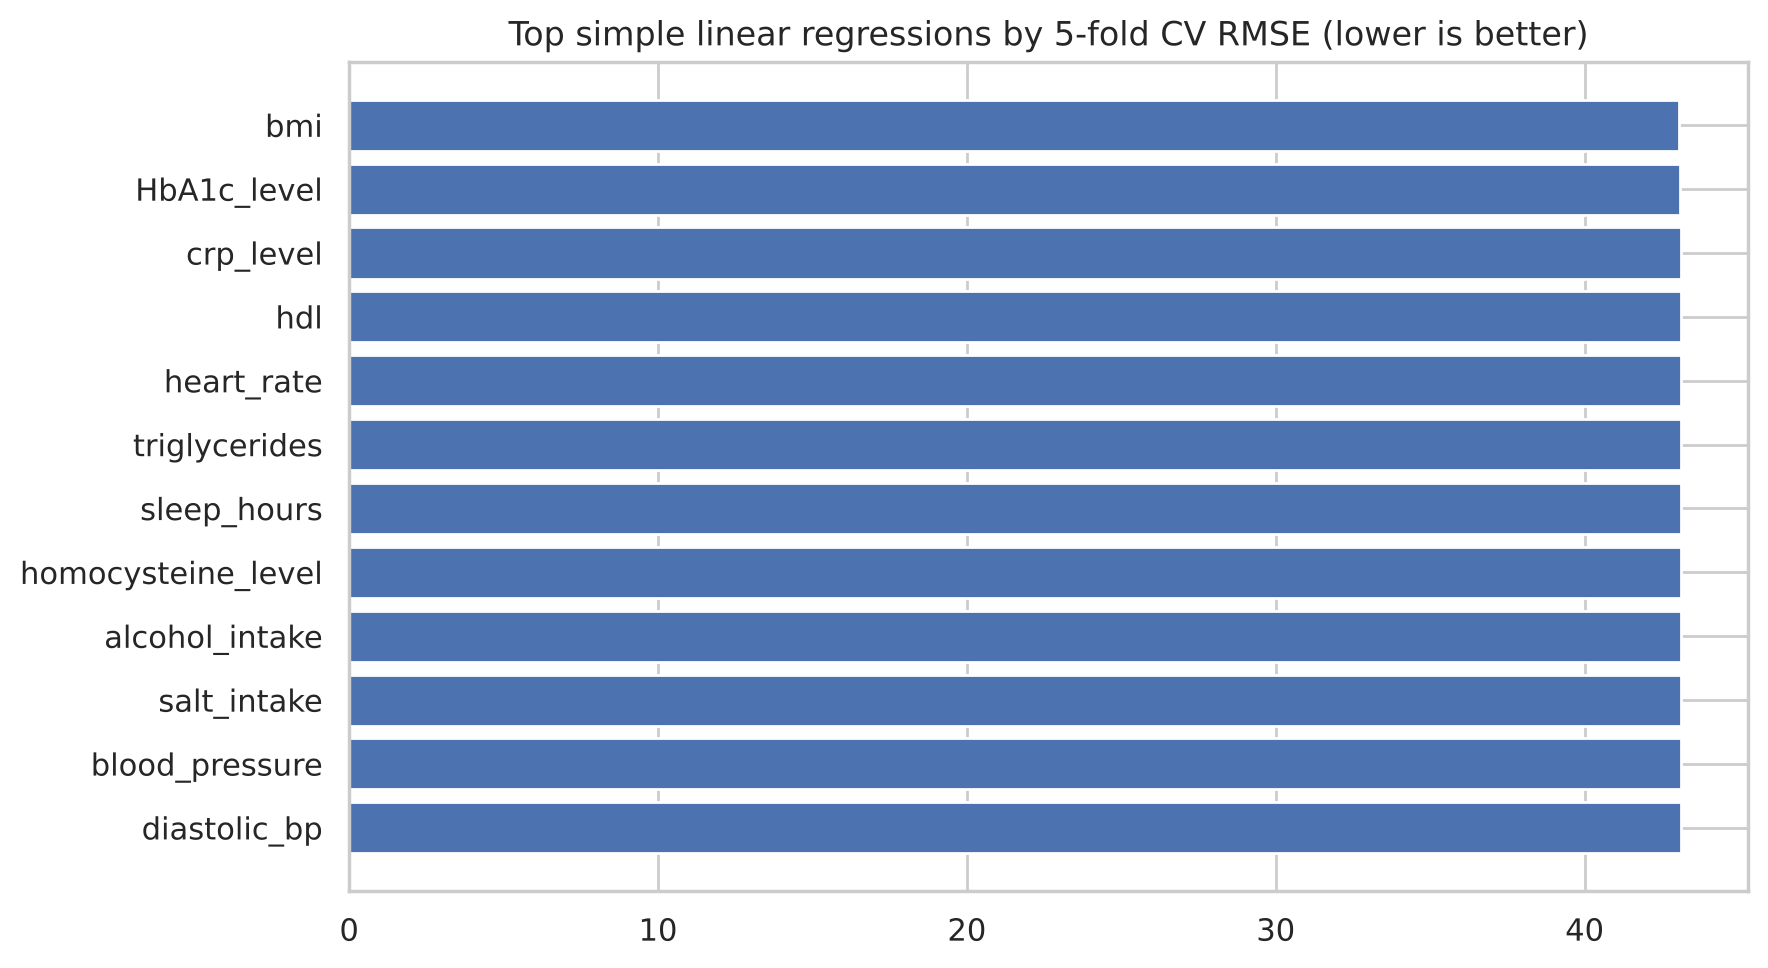

In [12]:
numeric_candidates = X_train.select_dtypes(include='number').columns.tolist()
simple_rows = []
for var in numeric_candidates:
    model = full_pipeline(X_train[[var]], LinearRegression())
    scores = cross_validate(model, X_train[[var]], yreg_train, cv=reg_cv,
                            scoring=reg_scoring, n_jobs=1)
    simple_rows.append({'feature': var, 'CV RMSE': -scores['test_rmse'].mean(),
                        'CV MAE': -scores['test_mae'].mean(),
                        'CV R2': scores['test_r2'].mean(),
                        'CV RMSE sd': scores['test_rmse'].std(ddof=1)})
simple_results = pd.DataFrame(simple_rows).sort_values('CV RMSE').reset_index(drop=True)
best_single = simple_results.loc[0, 'feature']
display(simple_results.round(4))
print('Selected simple predictor (training CV):', best_single)
fig, ax = plt.subplots(figsize=(9, 5))
top = simple_results.head(12).iloc[::-1]; ax.barh(top['feature'], top['CV RMSE'])
ax.set(title='Top simple linear regressions by 5-fold CV RMSE (lower is better)')
plt.tight_layout(); plt.show()

Fitted unscaled equation: target_regression = 127.585 + (+0.3926) × bmi


,model,MAE,RMSE,R2
0,Simple LR: bmi,32.1912,38.8853,0.0032


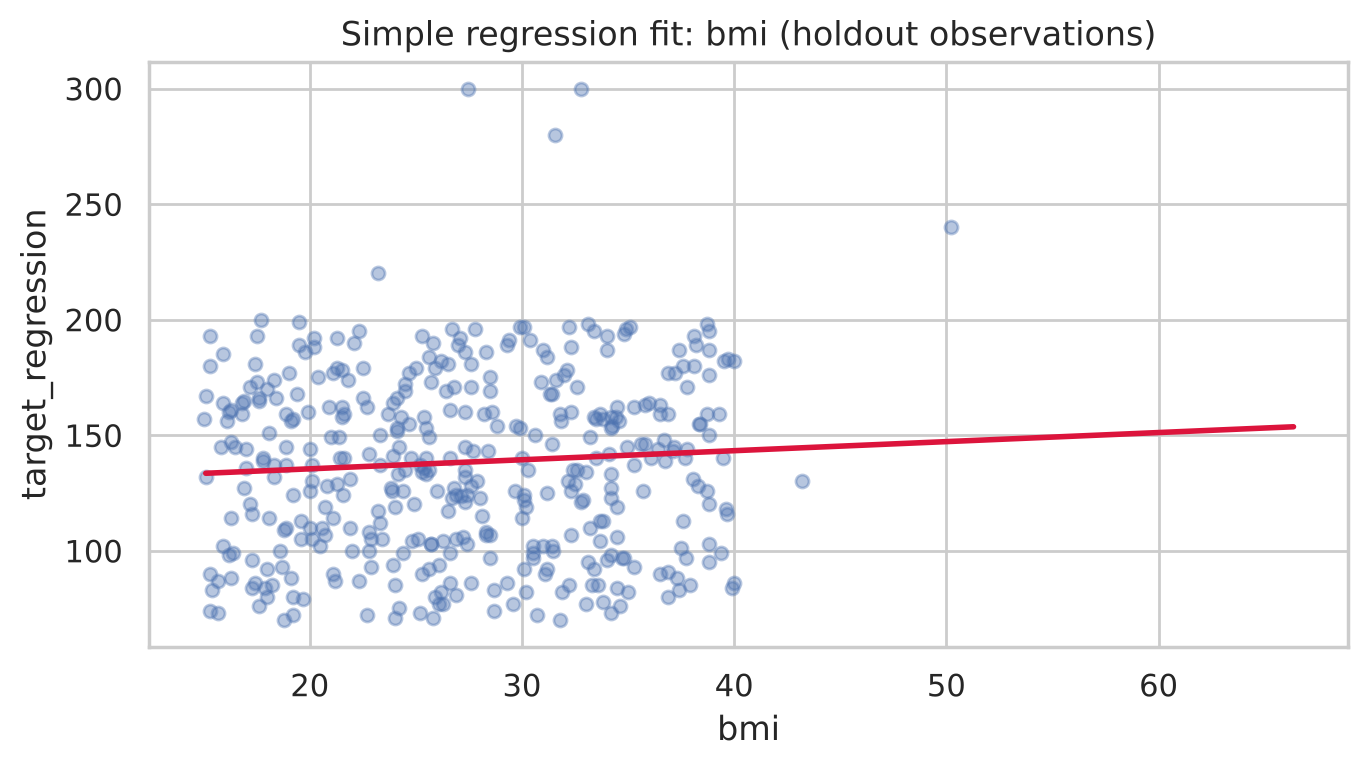

**Observed result.** Training CV selected **`bmi`**. On the untouched holdout, simple regression achieved **R² = 0.003, MAE = 32.19, RMSE = 38.89**. The R² measures the fraction of holdout variation explained relative to a constant baseline. A visually noticeable trend does not necessarily translate into useful patient-level predictions.

In [13]:
simple_best = full_pipeline(X_train[[best_single]], LinearRegression())
simple_best.fit(X_train[[best_single]], yreg_train)
simple_pred = simple_best.predict(X_test[[best_single]])
simple_score = {'model': f'Simple LR: {best_single}',
                'MAE': mean_absolute_error(yreg_test, simple_pred),
                'RMSE': np.sqrt(mean_squared_error(yreg_test, simple_pred)),
                'R2': r2_score(yreg_test, simple_pred)}
# Interpret coefficients on the original feature scale by fitting OLS without standardization.
raw_single = LinearRegression().fit(X_train[[best_single]], yreg_train)
print(f'Fitted unscaled equation: target_regression = {raw_single.intercept_:.3f} '
      f'+ ({raw_single.coef_[0]:+.4f}) × {best_single}')
display(pd.DataFrame([simple_score]).round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_test[best_single], yreg_test, s=22, alpha=.4)
x_grid = np.linspace(X_train[best_single].min(), X_train[best_single].max(), 200)
ax.plot(x_grid, raw_single.predict(pd.DataFrame({best_single:x_grid})), color='crimson', lw=2)
ax.set(title=f'Simple regression fit: {best_single} (holdout observations)',
       xlabel=best_single, ylabel='target_regression')
plt.tight_layout(); plt.show()
display(Markdown(f'''**Observed result.** Training CV selected **`{best_single}`**. On the untouched holdout, simple regression achieved **R² = {simple_score['R2']:.3f}, MAE = {simple_score['MAE']:.2f}, RMSE = {simple_score['RMSE']:.2f}**. {'The negative R² shows worse performance than predicting the holdout mean.' if simple_score['R2'] < 0 else 'The R² measures the fraction of holdout variation explained relative to a constant baseline.'} A visually noticeable trend does not necessarily translate into useful patient-level predictions.'''))

## 5. Regression: multiple linear model and comparison (task 3)

**Research question.** Does adding several clinical predictors improve on the best one-feature model? **Approach.** We compare interpretable feature combinations (top 2, 4 and 8 numeric predictors **re-ranked within each validation-training fold**), a domain-motivated cardiometabolic subset, and the full set of non-redundant predictors (including encoded categories). We select the multiple model by lowest **training CV RMSE**. The common held-out test partition is evaluated **once** for the chosen simple model, chosen multiple model, and a training-mean baseline. We do not claim that adding variables will necessarily help: weak signal and collinearity can worsen predictive error.

To prevent information leakage in 5-fold model comparison, each top-k feature ranking is recalculated inside that fold using only its training portion. Once a feature-count strategy is chosen by CV, we apply that strategy to all 1,600 training patients before the final holdout evaluation.

In [14]:
from sklearn.base import TransformerMixin, BaseEstimator
class TopKNumericCorrelation(TransformerMixin, BaseEstimator):
    """Select k numeric features using only data passed to fit()."""
    def __init__(self, k=2):
        self.k = k
    def fit(self, X, y):
        correlations = X.select_dtypes(include='number').corrwith(pd.Series(np.asarray(y), index=X.index)).abs()
        self.features_ = correlations.dropna().nlargest(self.k).index.tolist()
        return self
    def transform(self, X):
        return X[self.features_]

train_corr = X_train.select_dtypes(include='number').corrwith(yreg_train).abs().dropna().sort_values(ascending=False)
ranked = train_corr.index.tolist()
clinical_subset = [c for c in ['age','bmi','HbA1c_level','systolic_bp',
                                 'cholesterol','triglycerides','hdl','ldl','crp_level'] if c in X_train]
feature_groups = {'Top 2 numeric': ranked[:2],
                  'Top 4 numeric': ranked[:4],
                  'Top 8 numeric': ranked[:8],
                  'Clinical indicators': clinical_subset,
                  'All cleaned features': MODEL_FEATURES}
multi_rows = []
for label, cols in feature_groups.items():
    if label.startswith('Top '):
        k = int(label.split()[1])
        model = Pipeline([('select', TopKNumericCorrelation(k=k)),
                          ('imputer',SimpleImputer(strategy='median')),
                          ('scaler',StandardScaler()),('model',LinearRegression())])
        fold_X = X_train
    else:
        model = full_pipeline(X_train[cols], LinearRegression())
        fold_X = X_train[cols]
    cv = cross_validate(model, fold_X, yreg_train, cv=reg_cv,
                        scoring=reg_scoring, n_jobs=1)
    multi_rows.append({'group': label, 'features': len(cols),
                       'CV RMSE': -cv['test_rmse'].mean(),
                       'CV MAE': -cv['test_mae'].mean(),
                       'CV R2': cv['test_r2'].mean(),
                       'CV RMSE sd': cv['test_rmse'].std(ddof=1)})
multi_results = pd.DataFrame(multi_rows).sort_values('CV RMSE').reset_index(drop=True)
best_multiple = multi_results.loc[0, 'group']
print('Training-only feature correlation ranking:')
display(train_corr.head(12).to_frame('|r|').round(4))
display(multi_results.round(4))
print('Chosen multiple model:', best_multiple, '| Features:', feature_groups[best_multiple])

Training-only feature correlation ranking:


,|r|
bmi,0.0682
HbA1c_level,0.0681
triglycerides,0.0491
crp_level,0.0329
heart_rate,0.0288
hdl,0.0279
plasma_value,0.0223
homocysteine_level,0.0220
age,0.0144
ldl_alternative,0.0102


,group,features,CV RMSE,CV MAE,CV R2,CV RMSE sd
0,Top 2 numeric,2,43.0421,35.0011,-0.0007,2.4615
1,Top 4 numeric,4,43.1368,35.0907,-0.0053,2.3990
2,Clinical indicators,9,43.1421,35.0630,-0.0057,2.3231
3,Top 8 numeric,8,43.1785,35.1426,-0.0076,2.2519
4,All cleaned features,30,43.3118,35.3412,-0.0142,2.1448


Chosen multiple model: Top 2 numeric | Features: ['bmi', 'HbA1c_level']


,model,MAE,RMSE,R2
0,Training-mean baseline,32.2331,38.9979,-0.0026
1,Simple LR: bmi,32.1912,38.8853,0.0032
2,Multiple LR: Top 2 numeric,32.1896,38.8743,0.0037


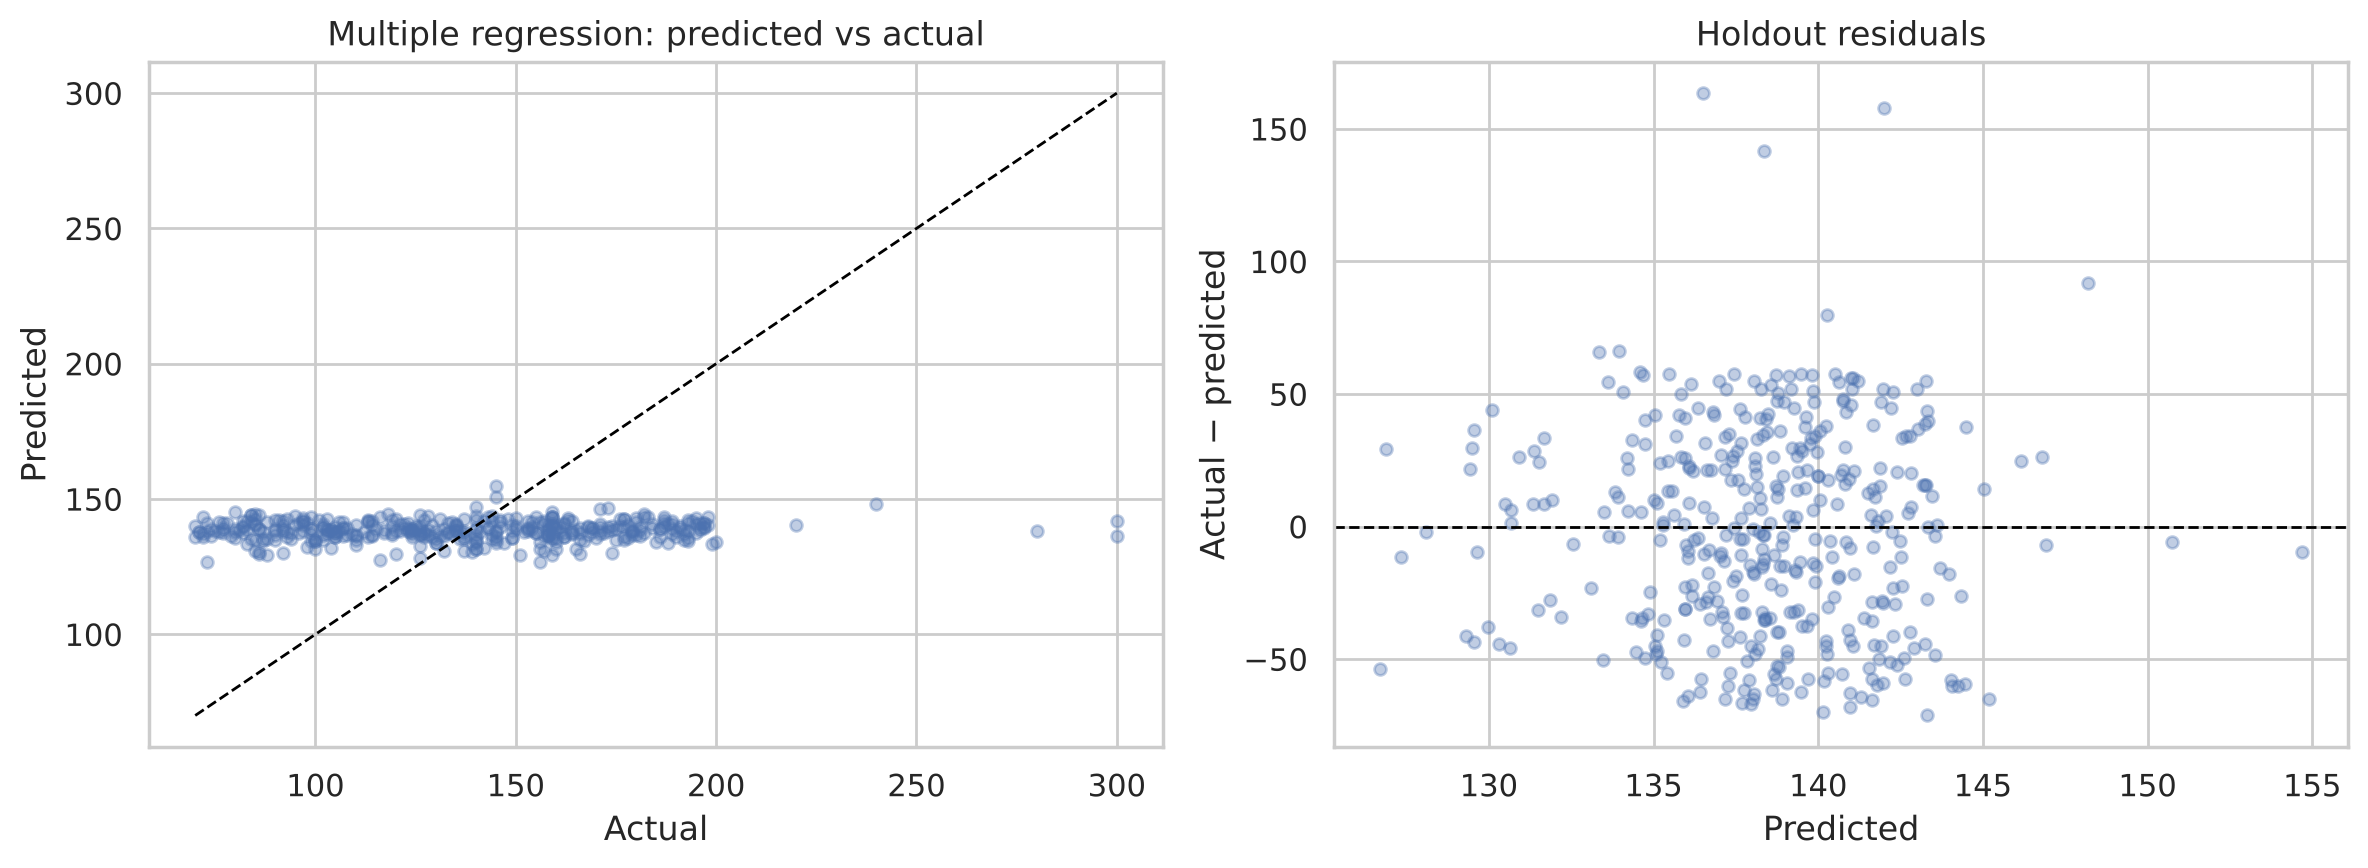

**Observed result.** The multiple model selected by 5-fold training CV was **Top 2 numeric**, comprising **2 original predictors**. Its holdout scores were **R² = 0.004, MAE = 32.19, RMSE = 38.87**; the simple model's RMSE was **38.89**, and the training-mean baseline's RMSE was **39.00**. The smallest observed holdout RMSE belongs to **Multiple LR: Top 2 numeric**. We compare the outcomes transparently, but **do not re-select or retune models on these test scores**. Weak positive or negative R² is evidence of limited linear predictability in this dataset, not a programming error.

In [15]:
selected_multi_cols = feature_groups[best_multiple]
multiple_best = full_pipeline(X_train[selected_multi_cols], LinearRegression())
multiple_best.fit(X_train[selected_multi_cols], yreg_train)
multi_pred = multiple_best.predict(X_test[selected_multi_cols])
dummy_reg = DummyRegressor(strategy='mean').fit(X_train, yreg_train)
dummy_pred = dummy_reg.predict(X_test)
reg_compare = pd.DataFrame([
    {'model':'Training-mean baseline','MAE': mean_absolute_error(yreg_test,dummy_pred),
     'RMSE':np.sqrt(mean_squared_error(yreg_test,dummy_pred)),'R2':r2_score(yreg_test,dummy_pred)},
    simple_score,
    {'model':f'Multiple LR: {best_multiple}', 'MAE':mean_absolute_error(yreg_test,multi_pred),
     'RMSE':np.sqrt(mean_squared_error(yreg_test,multi_pred)),'R2':r2_score(yreg_test,multi_pred)}
])
display(reg_compare.round(4))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].scatter(yreg_test, multi_pred, alpha=.35, s=18)
lo=min(yreg_test.min(),multi_pred.min()); hi=max(yreg_test.max(),multi_pred.max())
axs[0].plot([lo,hi],[lo,hi],'--',color='black',lw=1)
axs[0].set(title='Multiple regression: predicted vs actual', xlabel='Actual', ylabel='Predicted')
axs[1].scatter(multi_pred, yreg_test-multi_pred, alpha=.35, s=18)
axs[1].axhline(0,ls='--',color='black',lw=1)
axs[1].set(title='Holdout residuals',xlabel='Predicted',ylabel='Actual − predicted')
plt.tight_layout();plt.show()
winner_reg = reg_compare.sort_values('RMSE').iloc[0]
display(Markdown(f'''**Observed result.** The multiple model selected by 5-fold training CV was **{best_multiple}**, comprising **{len(selected_multi_cols)} original predictors**. Its holdout scores were **R² = {reg_compare.iloc[2]['R2']:.3f}, MAE = {reg_compare.iloc[2]['MAE']:.2f}, RMSE = {reg_compare.iloc[2]['RMSE']:.2f}**; the simple model's RMSE was **{reg_compare.iloc[1]['RMSE']:.2f}**, and the training-mean baseline's RMSE was **{reg_compare.iloc[0]['RMSE']:.2f}**. The smallest observed holdout RMSE belongs to **{winner_reg['model']}**. We compare the outcomes transparently, but **do not re-select or retune models on these test scores**. Weak positive or negative R² is evidence of limited linear predictability in this dataset, not a programming error.'''))

### 5.1 Absence of dependence, or a linearity assumption?

Every model in Sections 4 and 5 lands close to R² = 0, which invites the reading that these predictors carry no information about the target. That reading merges two different explanations. We separate them without leaving the linear framework: we cut one predictor into deciles and refit the same ordinary least squares model, so the only thing that changes is the functional form.


In [16]:
# Same estimator and same predictor, two functional forms: a slope against decile dummies.
def decile_pipeline(bins=10):
    return Pipeline([('imputer', SimpleImputer(strategy='median')),
                     ('bins', KBinsDiscretizer(n_bins=bins, encode='onehot-dense',
                                               strategy='quantile')),
                     ('model', LinearRegression())])

SHAPE_CANDIDATES = ['hdl', 'triglycerides', 'HbA1c_level', 'crp_level',
                    'bmi', 'age', 'blood_pressure', 'homocysteine_level']
shape_rows = []
for var in [c for c in SHAPE_CANDIDATES if c in X_train]:
    slope = cross_validate(full_pipeline(X_train[[var]], LinearRegression()),
                           X_train[[var]], yreg_train, cv=reg_cv,
                           scoring=reg_scoring, n_jobs=1)
    dummies = cross_validate(decile_pipeline(), X_train[[var]], yreg_train,
                             cv=reg_cv, scoring=reg_scoring, n_jobs=1)
    shape_rows.append({'feature': var,
                       'R2 slope': slope['test_r2'].mean(),
                       'R2 deciles': dummies['test_r2'].mean(),
                       'RMSE slope': -slope['test_rmse'].mean(),
                       'RMSE deciles': -dummies['test_rmse'].mean()})
shape_table = pd.DataFrame(shape_rows)
shape_table['R2 gain'] = shape_table['R2 deciles'] - shape_table['R2 slope']
shape_table = shape_table.sort_values('R2 gain', ascending=False).reset_index(drop=True)
display(shape_table.round(4))

# The same contrast with every predictor at once, in quintiles to limit the column count.
numeric_inputs = X_train.select_dtypes(include='number').columns.tolist()
categorical_inputs = X_train.select_dtypes(exclude='number').columns.tolist()
quintile_prep = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('bins', KBinsDiscretizer(n_bins=5, encode='onehot-dense',
                                                strategy='quantile'))]), numeric_inputs),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first',
                                               sparse_output=False))]), categorical_inputs)],
    sparse_threshold=0)

all_slopes = cross_validate(full_pipeline(X_train, LinearRegression()), X_train, yreg_train,
                            cv=reg_cv, scoring=reg_scoring, n_jobs=1)
all_dummies = cross_validate(Pipeline([('prepare', quintile_prep), ('model', LinearRegression())]),
                             X_train, yreg_train, cv=reg_cv, scoring=reg_scoring, n_jobs=1)
slope_r2 = all_slopes['test_r2'].mean()
dummy_r2 = all_dummies['test_r2'].mean()
slope_rmse = -all_slopes['test_rmse'].mean()
dummy_rmse = -all_dummies['test_rmse'].mean()
display(pd.DataFrame([
    {'specification': 'all predictors, slopes', 'CV R2': slope_r2, 'CV RMSE': slope_rmse},
    {'specification': 'all predictors, quintile dummies', 'CV R2': dummy_r2,
     'CV RMSE': dummy_rmse}]).round(4))

hdl_row = shape_table.set_index('feature').loc['hdl']
hdl_lin = hdl_row['R2 slope']
hdl_bin = hdl_row['R2 deciles']
trig_gain = shape_table.set_index('feature').loc['triglycerides', 'R2 gain']

display(Markdown(f"""**Observed result.** Swapping the slope for decile dummies, with the estimator left
untouched, moves `hdl` from CV R² {hdl_lin:+.4f} to {hdl_bin:+.4f}, and `triglycerides` gains
{trig_gain:+.4f} on the same measure. Applied to every numeric predictor at once, CV R² moves from
{slope_r2:+.4f} to {dummy_r2:+.4f} and CV RMSE from {slope_rmse:.2f} to {dummy_rmse:.2f}.

**Interpretation.** The dependence between these predictors and `target_regression` is present, and a
straight line is a poor way to describe it. A Pearson correlation and a single slope cannot express it by
construction, which is what Sections 4 and 5 were measuring. The gains stay small in absolute terms, so we
still make no claim of clinically useful prediction. This is the distinction that motivates the additive
models of Task 6, which fit a smooth function per predictor in place of one slope."""))


,feature,R2 slope,R2 deciles,RMSE slope,RMSE deciles,R2 gain
0,hdl,-0.0037,0.0289,43.1162,42.3611,0.0327
1,triglycerides,-0.0041,0.0199,43.1196,42.5993,0.0240
2,HbA1c_level,-0.0021,0.0203,43.0755,42.5864,0.0224
3,crp_level,-0.0037,0.0034,43.1149,42.9684,0.0070
4,bmi,-0.0009,0.0016,43.0517,43.0056,0.0024
5,blood_pressure,-0.0044,-0.0045,43.1302,43.1375,-0.0001
6,age,-0.0068,-0.0082,43.1803,43.2199,-0.0014
7,homocysteine_level,-0.0042,-0.0056,43.1261,43.1559,-0.0014


,specification,CV R2,CV RMSE
0,"all predictors, slopes",-0.0142,43.3118
1,"all predictors, quintile dummies",0.0274,42.3829


**Observed result.** Swapping the slope for decile dummies, with the estimator left
untouched, moves `hdl` from CV R² -0.0037 to +0.0289, and `triglycerides` gains
+0.0240 on the same measure. Applied to every numeric predictor at once, CV R² moves from
-0.0142 to +0.0274 and CV RMSE from 43.31 to 42.38.

**Interpretation.** The dependence between these predictors and `target_regression` is present, and a
straight line is a poor way to describe it. A Pearson correlation and a single slope cannot express it by
construction, which is what Sections 4 and 5 were measuring. The gains stay small in absolute terms, so we
still make no claim of clinically useful prediction. This is the distinction that motivates the additive
models of Task 6, which fit a smooth function per predictor in place of one slope.

## 6. Classification: Logistic Regression versus LDA (task 4)

**Research question.** Can clinical characteristics distinguish the three diagnostic categories (`DI`, `DI_HY`, `HT_HY`)?

**Approach.** We compare a class-weight-balanced multinomial Logistic Regression with an LDA that uses **uniform class priors** (`1/3` per class) rather than priors proportional to class prevalence. This makes the comparison more informative when the rare class matters, although class weighting in Logistic Regression is *not identical* to setting priors in LDA. The original empirical-prior LDA is reported separately as a sensitivity analysis. Both methods use the same training-only stratified CV splits and feature preprocessing. The majority-class classifier is a reference baseline.

We **select between the two primary methods using training 5-fold macro-F1** and report class-wise recall, balanced accuracy and confusion matrices on the untouched holdout. EDA revealed highly unequal within-class dispersions; shrinkage makes LDA's covariance estimate more stable but does **not** make its shared-covariance assumption true. Classifier conclusions are therefore cautious.


In [17]:
CLASSIFIERS = {
    'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced', solver='lbfgs'),
    'LDA (uniform priors)': LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto', priors=[1/3, 1/3, 1/3])
}
base_classifier = DummyClassifier(strategy='most_frequent')
# Model comparison on training data only, using the same 5-fold splits.
cv_rows=[]
for label, estimator in [('Majority baseline',base_classifier), *CLASSIFIERS.items()]:
    candidate = full_pipeline(X_train, estimator)
    results = cross_validate(candidate, X_train, ycls_train, cv=cls_cv5,
                             scoring=cls_scoring, n_jobs=1)
    cv_rows.append({'model':label,
                    'CV macro-F1':results['test_macro_f1'].mean(),
                    'CV macro-F1 sd':results['test_macro_f1'].std(ddof=1),
                    'CV balanced acc.':results['test_balanced_accuracy'].mean(),
                    'CV accuracy':results['test_accuracy'].mean()})
class_cv_table=pd.DataFrame(cv_rows).sort_values('CV macro-F1',ascending=False)
display(class_cv_table.round(4))
selected_classifier_name = (class_cv_table[class_cv_table['model'].isin(CLASSIFIERS)]
                            .sort_values('CV macro-F1').iloc[-1]['model'])
print('Selected (5-fold training macro-F1):',selected_classifier_name)

,model,CV macro-F1,CV macro-F1 sd,CV balanced acc.,CV accuracy
2,LDA (uniform priors),0.5997,0.0199,0.6641,0.5606
1,Logistic Regression,0.5768,0.0153,0.6382,0.5544
0,Majority baseline,0.2611,0.0000,0.3333,0.6438


Selected (5-fold training macro-F1): LDA (uniform priors)


### 6.1 Holdout evaluation and error diagnosis

**Approach.** After comparing the algorithms using training-only CV, we fit both methods on all training patients and report their 400-patient holdout performance. We inspect the three-class confusion matrices directly: each **row represents a true class**, and each **column represents the predicted class** (scikit-learn convention). The minor class deserves special attention, because high global accuracy can coexist with many missed minority cases.

,model,accuracy,balanced accuracy,macro-F1
2,LDA (uniform priors),0.5100,0.5431,0.5240
1,Logistic Regression,0.5150,0.5406,0.5176
0,Majority baseline,0.6425,0.3333,0.2608


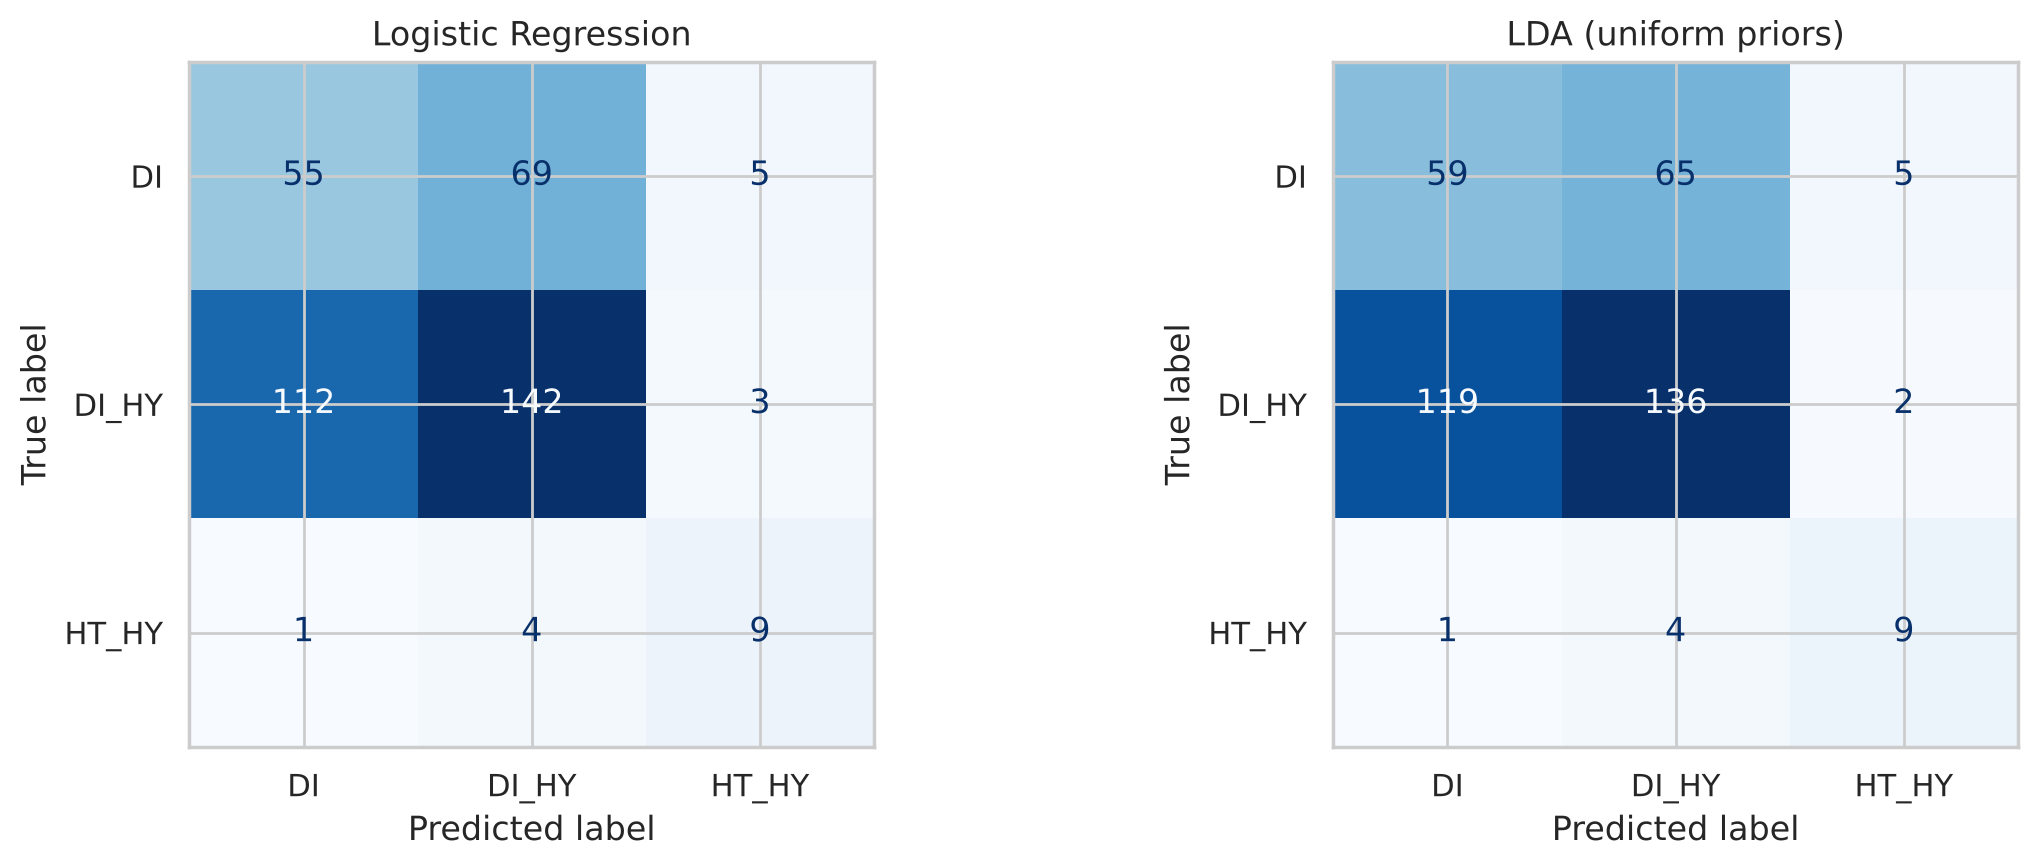


=== Logistic Regression ===
              precision    recall  f1-score   support

          DI      0.327     0.426     0.370       129
       DI_HY      0.660     0.553     0.602       257
       HT_HY      0.529     0.643     0.581        14

    accuracy                          0.515       400
   macro avg      0.506     0.541     0.518       400
weighted avg      0.548     0.515     0.526       400


=== LDA (uniform priors) ===
              precision    recall  f1-score   support

          DI      0.330     0.457     0.383       129
       DI_HY      0.663     0.529     0.589       257
       HT_HY      0.562     0.643     0.600        14

    accuracy                          0.510       400
   macro avg      0.519     0.543     0.524       400
weighted avg      0.552     0.510     0.523       400



**Observed result.** **LDA (uniform priors)** was selected using training CV macro-F1. Its independent holdout results were **accuracy 0.510, balanced accuracy 0.543, macro-F1 0.524**. On the rare `HT_HY` class (only **14** holdout patients), Logistic Regression recalled **64.3%**, and LDA recalled **64.3%**. The full classification report clarifies which classes each algorithm gets right and wrong; accuracy alone would conceal this difference.

In [18]:
holdout_models = {'Majority baseline':full_pipeline(X_train,base_classifier),
                  **{name:full_pipeline(X_train,est) for name,est in CLASSIFIERS.items()}}
cls_holdout_rows=[]
cls_predictions={}
for label, model in holdout_models.items():
    model.fit(X_train, ycls_train)
    pred = model.predict(X_test)
    cls_predictions[label] = pred
    cls_holdout_rows.append({'model': label, 'accuracy':accuracy_score(ycls_test,pred),
                             'balanced accuracy':balanced_accuracy_score(ycls_test,pred),
                             'macro-F1':f1_score(ycls_test,pred,average='macro',zero_division=0)})
cls_holdout_table=pd.DataFrame(cls_holdout_rows).sort_values('macro-F1',ascending=False)
display(cls_holdout_table.round(4))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, label in zip(axs, CLASSIFIERS):
    ConfusionMatrixDisplay.from_predictions(ycls_test, cls_predictions[label],
                                            labels=sorted(class_counts.index),
                                            ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(label)
plt.tight_layout();plt.show()
for label in CLASSIFIERS:
    print('\n===',label,'===')
    print(classification_report(ycls_test, cls_predictions[label],zero_division=0,digits=3))
minority = class_counts.index[-1]
minority_recall = {name: (np.sum((ycls_test.to_numpy()==minority)&(pred==minority)) /
                          np.sum(ycls_test.to_numpy()==minority))
                   for name,pred in cls_predictions.items()}
cv_selected_row = cls_holdout_table.set_index('model').loc[selected_classifier_name]
display(Markdown(f'''**Observed result.** **{selected_classifier_name}** was selected using training CV macro-F1. Its independent holdout results were **accuracy {cv_selected_row['accuracy']:.3f}, balanced accuracy {cv_selected_row['balanced accuracy']:.3f}, macro-F1 {cv_selected_row['macro-F1']:.3f}**. On the rare `{minority}` class (only **{int((ycls_test==minority).sum())}** holdout patients), Logistic Regression recalled **{minority_recall['Logistic Regression']:.1%}**, and LDA recalled **{minority_recall['LDA (uniform priors)']:.1%}**. The full classification report clarifies which classes each algorithm gets right and wrong; accuracy alone would conceal this difference.'''))

### 6.2 Sensitivity analysis: empirical versus uniform LDA class priors

**Approach.** As an auxiliary analysis, we evaluate LDA with empirical class priors alongside the selected uniform-prior version. This isolates an important modelling choice: the relative importance of common and rare diagnoses. The primary Logistic Regression versus LDA decision is still based on training cross-validation; this auxiliary holdout result is descriptive.

In [19]:
# Sensitivity analysis: how much does LDA depend on class priors?
# Model selection above uses the two primary classifiers only, on training CV.
lda_empirical = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')
lda_empirical_pipe = full_pipeline(X_train, lda_empirical)
empirical_cv = cross_validate(lda_empirical_pipe, X_train, ycls_train,
                              cv=cls_cv5, scoring='f1_macro', n_jobs=1)['test_score']
lda_empirical_pipe.fit(X_train, ycls_train)
empirical_pred = lda_empirical_pipe.predict(X_test)
lda_prior_comparison = pd.DataFrame([
    {'variant': 'LDA empirical priors', 'train CV macro-F1': empirical_cv.mean(),
     'holdout macro-F1': f1_score(ycls_test, empirical_pred, average='macro', zero_division=0)},
    {'variant': 'LDA uniform priors',
     'train CV macro-F1': class_cv_table.set_index('model').loc['LDA (uniform priors)', 'CV macro-F1'],
     'holdout macro-F1': cls_holdout_table.set_index('model').loc['LDA (uniform priors)', 'macro-F1']},
])
display(lda_prior_comparison.round(4))
print('Empirical-prior LDA class-by-class metrics (sensitivity check only):')
print(classification_report(ycls_test, empirical_pred, digits=3, zero_division=0))
display(Markdown('''**Interpretation.** Equal class priors make LDA less dominated by the most frequent diagnosis. The change can improve minority-class recognition at the cost of some overall accuracy. Priors influence classification boundaries but do not remedy class-specific covariance differences. The **primary model choice** is made by training CV macro-F1, not by examining the holdout results.'''))

,variant,train CV macro-F1,holdout macro-F1
0,LDA empirical priors,0.5860,0.513
1,LDA uniform priors,0.5997,0.524


Empirical-prior LDA class-by-class metrics (sensitivity check only):
              precision    recall  f1-score   support

          DI      0.385     0.078     0.129       129
       DI_HY      0.658     0.938     0.774       257
       HT_HY      0.875     0.500     0.636        14

    accuracy                          0.645       400
   macro avg      0.639     0.505     0.513       400
weighted avg      0.578     0.645     0.561       400



**Interpretation.** Equal class priors make LDA less dominated by the most frequent diagnosis. The change can improve minority-class recognition at the cost of some overall accuracy. Priors influence classification boundaries but do not remedy class-specific covariance differences. The **primary model choice** is made by training CV macro-F1, not by examining the holdout results.

### 6.3 Robustness check: Quadratic Discriminant Analysis

Section 2.2.1 showed that the cohort holds two groups whose dispersions move in opposite directions. LDA assumes one pooled covariance matrix shared by every class, which that structure contradicts. QDA fits a separate covariance matrix per class, so comparing the two tests the assumption directly. This is a check prompted by our own exploratory analysis, not a model the assignment asks for, and the primary choice made in Section 6 stands either way.


,model,CV macro-F1,CV macro-F1 sd,holdout macro-F1,holdout balanced accuracy,holdout accuracy
0,QDA (reg_param=0.1),0.5227,0.0235,0.4735,0.6150,0.62
1,LDA (uniform priors),0.5997,0.0199,0.5240,0.5431,0.51


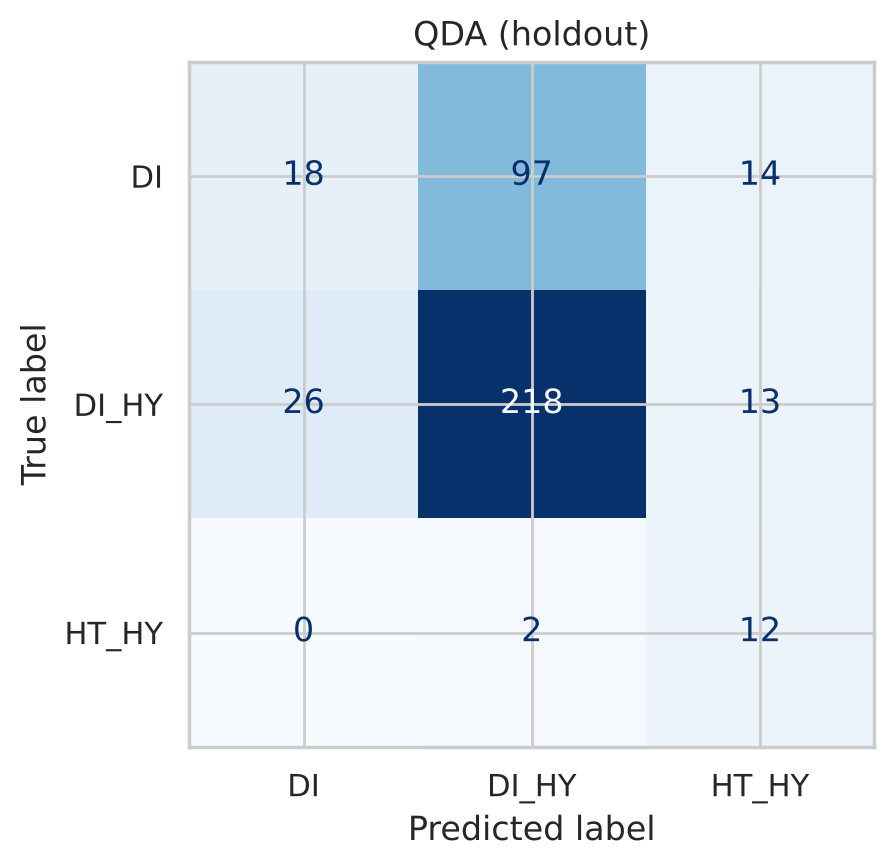

QDA holdout classification report:
              precision    recall  f1-score   support

          DI      0.409     0.140     0.208       129
       DI_HY      0.688     0.848     0.760       257
       HT_HY      0.308     0.857     0.453        14

    accuracy                          0.620       400
   macro avg      0.468     0.615     0.474       400
weighted avg      0.585     0.620     0.571       400



**Observed result.** QDA reached CV macro-F1 0.523 against
0.600 for LDA, and holdout macro-F1 0.474 against 0.524. On our
primary selection metric QDA comes out behind, so the model chosen in Section 6 is unchanged.

**The ranking flips on the metrics that Section 2.2.1 points to.** QDA lifted holdout balanced accuracy to
0.615 from 0.543, and recall on `HT_HY` to 85.7% from
64.3%. That fits the structure we documented: `HT_HY` is the class whose dispersion is
compressed by a factor of roughly 35, so a covariance matrix of its own describes it far better than a
pooled one. The cost lands on `DI`, whose recall drops to 14.0%, and that is what pulls
macro-F1 down.

**Interpretation.** The equal-covariance assumption is violated in a way that matters, and relaxing it buys
real gains where our exploratory analysis said it would. The gains are not free: QDA estimates one
covariance matrix per class, which is many more parameters, and `HT_HY` offers only 55
training patients to estimate one from. We keep LDA as the primary model on macro-F1 grounds while
recording that the violation is real and measured.

In [20]:
# QDA relaxes the shared-covariance assumption that Section 2.2.1 calls into question.
qda = QuadraticDiscriminantAnalysis(reg_param=0.1)
qda_pipeline = full_pipeline(X_train, qda)
qda_cv = cross_validate(qda_pipeline, X_train, ycls_train, cv=cls_cv5,
                        scoring=cls_scoring, n_jobs=1)
qda_pipeline.fit(X_train, ycls_train)
qda_pred = qda_pipeline.predict(X_test)

lda_cv_f1 = class_cv_table.set_index('model').loc['LDA (uniform priors)', 'CV macro-F1']
lda_holdout = cls_holdout_table.set_index('model').loc['LDA (uniform priors)']
qda_cv_f1 = qda_cv['test_macro_f1'].mean()
qda_f1 = f1_score(ycls_test, qda_pred, average='macro', zero_division=0)
qda_balanced = balanced_accuracy_score(ycls_test, qda_pred)

qda_comparison = pd.DataFrame([
    {'model': 'QDA (reg_param=0.1)',
     'CV macro-F1': qda_cv_f1,
     'CV macro-F1 sd': qda_cv['test_macro_f1'].std(ddof=1),
     'holdout macro-F1': qda_f1,
     'holdout balanced accuracy': qda_balanced,
     'holdout accuracy': accuracy_score(ycls_test, qda_pred)},
    {'model': 'LDA (uniform priors)',
     'CV macro-F1': lda_cv_f1,
     'CV macro-F1 sd': class_cv_table.set_index('model').loc['LDA (uniform priors)',
                                                             'CV macro-F1 sd'],
     'holdout macro-F1': lda_holdout['macro-F1'],
     'holdout balanced accuracy': lda_holdout['balanced accuracy'],
     'holdout accuracy': lda_holdout['accuracy']}])
display(qda_comparison.round(4))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(ycls_test, qda_pred,
                                        labels=sorted(class_counts.index),
                                        ax=ax, colorbar=False, cmap='Blues')
ax.set_title('QDA (holdout)')
plt.tight_layout()
plt.show()

print('QDA holdout classification report:')
print(classification_report(ycls_test, qda_pred, zero_division=0, digits=3))

qda_report = classification_report(ycls_test, qda_pred, output_dict=True, zero_division=0)
qda_rare_recall = qda_report[rare]['recall']
qda_di_recall = qda_report['DI']['recall']
lda_rare_recall = minority_recall['LDA (uniform priors)']
lda_balanced = lda_holdout['balanced accuracy']
rare_in_training = int((ycls_train == rare).sum())

display(Markdown(f"""**Observed result.** QDA reached CV macro-F1 {qda_cv_f1:.3f} against
{lda_cv_f1:.3f} for LDA, and holdout macro-F1 {qda_f1:.3f} against {lda_holdout['macro-F1']:.3f}. On our
primary selection metric QDA comes out behind, so the model chosen in Section 6 is unchanged.

**The ranking flips on the metrics that Section 2.2.1 points to.** QDA lifted holdout balanced accuracy to
{qda_balanced:.3f} from {lda_balanced:.3f}, and recall on `{rare}` to {qda_rare_recall:.1%} from
{lda_rare_recall:.1%}. That fits the structure we documented: `{rare}` is the class whose dispersion is
compressed by a factor of roughly 35, so a covariance matrix of its own describes it far better than a
pooled one. The cost lands on `DI`, whose recall drops to {qda_di_recall:.1%}, and that is what pulls
macro-F1 down.

**Interpretation.** The equal-covariance assumption is violated in a way that matters, and relaxing it buys
real gains where our exploratory analysis said it would. The gains are not free: QDA estimates one
covariance matrix per class, which is many more parameters, and `{rare}` offers only {rare_in_training}
training patients to estimate one from. We keep LDA as the primary model on macro-F1 grounds while
recording that the violation is real and measured."""))


### 6.4 Uncertainty attached to the holdout numbers

The two classifiers sit a few thousandths of macro-F1 apart, and we select between them on that gap. This section measures how much uncertainty surrounds it, using a paired comparison across the folds and a bootstrap of the holdout set itself.


In [21]:
# Does the gap between the two classifiers exceed its own uncertainty?
LOGREG = 'Logistic Regression'
LDA_MODEL = 'LDA (uniform priors)'

logreg_folds = cross_validate(full_pipeline(X_train, CLASSIFIERS[LOGREG]), X_train, ycls_train,
                              cv=cls_cv5, scoring='f1_macro', n_jobs=1)['test_score']
lda_folds = cross_validate(full_pipeline(X_train, CLASSIFIERS[LDA_MODEL]), X_train, ycls_train,
                           cv=cls_cv5, scoring='f1_macro', n_jobs=1)['test_score']
fold_table = pd.DataFrame({LOGREG: logreg_folds, LDA_MODEL: lda_folds},
                          index=[f'fold {i + 1}' for i in range(len(logreg_folds))])
display(fold_table.round(4))

paired_gap = lda_folds - logreg_folds
t_stat, p_value = ttest_rel(lda_folds, logreg_folds)

# Bootstrap the 400-patient holdout to see how stable each score is.
BOOTSTRAP_DRAWS = 2000
boot_rng = np.random.default_rng(SEED)
y_holdout = ycls_test.to_numpy()
logreg_boot = []
lda_boot = []
for _ in range(BOOTSTRAP_DRAWS):
    draw = boot_rng.integers(0, len(y_holdout), len(y_holdout))
    if len(np.unique(y_holdout[draw])) < 3:
        continue
    logreg_boot.append(f1_score(y_holdout[draw], cls_predictions[LOGREG][draw],
                                average='macro', zero_division=0))
    lda_boot.append(f1_score(y_holdout[draw], cls_predictions[LDA_MODEL][draw],
                             average='macro', zero_division=0))
logreg_boot = np.array(logreg_boot)
lda_boot = np.array(lda_boot)

ci_rows = []
for name, scores in [(LOGREG, logreg_boot), (LDA_MODEL, lda_boot)]:
    low, high = np.percentile(scores, 2.5), np.percentile(scores, 97.5)
    ci_rows.append({'model': name,
                    'holdout macro-F1': f1_score(ycls_test, cls_predictions[name],
                                                 average='macro', zero_division=0),
                    'CI 2.5%': low, 'CI 97.5%': high, 'CI width': high - low})
ci_table = pd.DataFrame(ci_rows)
display(ci_table.round(4))

lda_win_rate = (lda_boot > logreg_boot).mean()
logreg_ci_width = ci_table.set_index('model').loc[LOGREG, 'CI width']
lda_ci_width = ci_table.set_index('model').loc[LDA_MODEL, 'CI width']
rare_in_holdout = int((ycls_test == rare).sum())
points_per_patient = 100 / rare_in_holdout

display(Markdown(f"""**Observed result.** Across the five folds LDA beat Logistic Regression by
{paired_gap.mean():+.4f} macro-F1 on average, with a standard deviation of {paired_gap.std(ddof=1):.4f}. A
paired t-test gives t = {t_stat:.3f} and p = {p_value:.4f}, which does not clear the conventional 5%
threshold. Bootstrapping the holdout {BOOTSTRAP_DRAWS} times produces 95% intervals
{logreg_ci_width:.3f} and {lda_ci_width:.3f} wide that overlap almost completely, and LDA scores higher on
{lda_win_rate:.1%} of the resampled holdouts.

**Why the per-class figures need care.** The holdout holds {rare_in_holdout} `{rare}` patients, so one
patient shifts that class's recall by {points_per_patient:.1f} percentage points and the three-class
macro-F1 by about a third of that. The `{rare}` figures quoted in Sections 6.1 to 6.3 indicate direction
and should not be read as precise estimates. This follows from the class distribution and says nothing
about the estimators."""))


,Logistic Regression,LDA (uniform priors)
fold 1,0.5692,0.5784
fold 2,0.5756,0.5867
fold 3,0.5971,0.6015
fold 4,0.5854,0.6305
fold 5,0.5570,0.6013


,model,holdout macro-F1,CI 2.5%,CI 97.5%,CI width
0,Logistic Regression,0.5176,0.4334,0.5910,0.1575
1,LDA (uniform priors),0.5240,0.4388,0.6001,0.1613


**Observed result.** Across the five folds LDA beat Logistic Regression by
+0.0228 macro-F1 on average, with a standard deviation of 0.0201. A
paired t-test gives t = 2.533 and p = 0.0645, which does not clear the conventional 5%
threshold. Bootstrapping the holdout 2000 times produces 95% intervals
0.158 and 0.161 wide that overlap almost completely, and LDA scores higher on
62.2% of the resampled holdouts.

**Why the per-class figures need care.** The holdout holds 14 `HT_HY` patients, so one
patient shifts that class's recall by 7.1 percentage points and the three-class
macro-F1 by about a third of that. The `HT_HY` figures quoted in Sections 6.1 to 6.3 indicate direction
and should not be read as precise estimates. This follows from the class distribution and says nothing
about the estimators.

## 7. Resampling: variability and stability (task 4)

**Research question.** How sensitive are our model assessments to sampling methodology? **Approach.** Apply the same two classifiers and metric (macro-F1) to a repeated stratified holdout study, 5-fold CV, 10-fold CV, exact LOOCV, and bootstrap out-of-bag assessment.

**Important distinction:** 5-fold/10-fold CV provides fold-level score variation, repeated holdout gives variation across independent random partitions (not independent scores), and bootstrap OOB evaluates out-of-bag observations that change across replications. LOOCV has one observation per validation fold, so a *single-fold macro-F1 is not statistically meaningful*. We aggregate all LOOCV out-of-fold predictions before calculating macro-F1, and do **not** report a misleading standard deviation of 1-observation scores. These methods estimate related but not identical quantities, so the numerical variances should be interpreted carefully.

In [22]:
resample_rows=[]
resample_samples={}

def add_sample_results(name, method, values):
    values=np.array(values,dtype=float)
    resample_samples[(name,method)]=values
    resample_rows.append({'model':name,'method':method, 'repeats':len(values),
                          'mean macro-F1':values.mean(),
                          'sd macro-F1':values.std(ddof=1) if len(values)>1 else np.nan,
                          'variance':values.var(ddof=1) if len(values)>1 else np.nan})

for name,est in CLASSIFIERS.items():
    pipeline = full_pipeline(X_train,est)
    # Consistent 5-fold and 10-fold CV, on the held-out-free training partition.
    for k,cv in [(5,cls_cv5),(10,cls_cv10)]:
        scores = cross_validate(pipeline,X_train,ycls_train,cv=cv,
                                scoring='f1_macro',n_jobs=1)['test_score']
        add_sample_results(name,f'{k}-fold CV',scores)
    # Repeat stratified holdout within the training partition; fixed 25% validation size.
    shuffle = StratifiedShuffleSplit(n_splits=15,test_size=.25,random_state=SEED)
    repeated=[]
    for tr,va in shuffle.split(X_train,ycls_train):
        model=clone(pipeline)
        model.fit(X_train.iloc[tr],ycls_train.iloc[tr])
        predictions=model.predict(X_train.iloc[va])
        repeated.append(f1_score(ycls_train.iloc[va],predictions,average='macro',zero_division=0))
    add_sample_results(name,'Repeated holdout (15)',repeated)
print('Cross-validation and repeated-holdout computations complete.')

Cross-validation and repeated-holdout computations complete.


### 7.1 Leave-One-Out Cross-Validation (LOOCV)

**Approach.** LOOCV uses **all 1,600 training records**, leaving one record out at each iteration and refitting the complete preprocessing-and-classification pipeline on the other 1,599. The final 400-record holdout remains untouched. Each training patient receives exactly one out-of-fold prediction; we calculate **pooled macro-F1**, balanced accuracy and accuracy on the combined predictions. Because a single LOOCV fold has just one case, a per-fold macro-F1 standard deviation would be uninterpretable and is not reported. Full LOOCV is computationally intensive and can take substantially longer than ordinary k-fold CV.


In [23]:
# Full LOOCV on all training patients (no subset sampling).
loo = LeaveOneOut()
loocv_results = []
for name, est in CLASSIFIERS.items():
    print(f'Running LOOCV for {name}: {len(X_train)} model fits', flush=True)
    predicted = cross_val_predict(full_pipeline(X_train, est), X_train, ycls_train,
                                  cv=loo, n_jobs=1, method='predict')
    loocv_results.append({'model': name,
                          'LOOCV pooled macro-F1': f1_score(ycls_train, predicted, average='macro', zero_division=0),
                          'LOOCV pooled balanced accuracy': balanced_accuracy_score(ycls_train, predicted),
                          'LOOCV pooled accuracy': accuracy_score(ycls_train, predicted)})
loocv_table = pd.DataFrame(loocv_results)
display(loocv_table.round(4))
print('Full training LOOCV complete:', len(X_train), 'pooled predictions per model.')


Running LOOCV for Logistic Regression: 1600 model fits


Running LOOCV for LDA (uniform priors): 1600 model fits


,model,LOOCV pooled macro-F1,LOOCV pooled balanced accuracy,LOOCV pooled accuracy
0,Logistic Regression,0.5761,0.6510,0.5575
1,LDA (uniform priors),0.5758,0.6544,0.5488


Full training LOOCV complete: 1600 pooled predictions per model.


### 7.2 Bootstrap with out-of-bag (OOB) assessment

**Approach.** For each of 200 bootstrap replicates, sample 1,600 training patient indices **with replacement**. Fit the model on the resampled patients, evaluate on the **out-of-bag** patients never included in that replicate, and record macro-F1. Bootstrap samples may contain fewer than 1,600 unique patients. We verify that every fitted replicate includes all three target classes and that each OOB set contains all three for interpretable macro-F1; skipped draws would be explicitly counted. Although OOB testing reuses observations across repeats, it provides a useful measure of evaluation instability.

In [24]:
BOOTSTRAP_REPEATS=200
bootstrap_sizes={}
for name, est in CLASSIFIERS.items():
    scores=[]; sizes=[]; skipped=0
    boot_rng=np.random.default_rng(SEED+100)
    pipe=full_pipeline(X_train,est)
    for iteration in range(BOOTSTRAP_REPEATS):
        boot_indices=boot_rng.integers(0,len(X_train),size=len(X_train))
        unseen=np.setdiff1d(np.arange(len(X_train)),np.unique(boot_indices))
        if (ycls_train.iloc[boot_indices].nunique()<3 or
                ycls_train.iloc[unseen].nunique()<3):
            skipped+=1
            continue
        model=clone(pipe)
        model.fit(X_train.iloc[boot_indices],ycls_train.iloc[boot_indices])
        output=model.predict(X_train.iloc[unseen])
        scores.append(f1_score(ycls_train.iloc[unseen],output,average='macro',zero_division=0))
        sizes.append(len(unseen))
    add_sample_results(name,f'Bootstrap OOB ({BOOTSTRAP_REPEATS})',scores)
    bootstrap_sizes[name]=(np.mean(sizes),skipped)
    print(f'{name}: {len(scores)} valid draws, mean OOB size {np.mean(sizes):.1f}, skipped {skipped}')

Logistic Regression: 200 valid draws, mean OOB size 589.2, skipped 0


LDA (uniform priors): 200 valid draws, mean OOB size 589.2, skipped 0


,model,method,repeats,mean macro-F1,sd macro-F1,variance
0,LDA (uniform priors),10-fold CV,10,0.57108,0.04414,0.00195
1,LDA (uniform priors),5-fold CV,5,0.59967,0.01987,0.00040
2,LDA (uniform priors),Bootstrap OOB (200),200,0.57316,0.02626,0.00069
3,LDA (uniform priors),Repeated holdout (15),15,0.57810,0.02809,0.00079
4,Logistic Regression,10-fold CV,10,0.57597,0.05878,0.00346
5,Logistic Regression,5-fold CV,5,0.57685,0.01530,0.00023
6,Logistic Regression,Bootstrap OOB (200),200,0.57264,0.02926,0.00086
7,Logistic Regression,Repeated holdout (15),15,0.57270,0.02454,0.00060


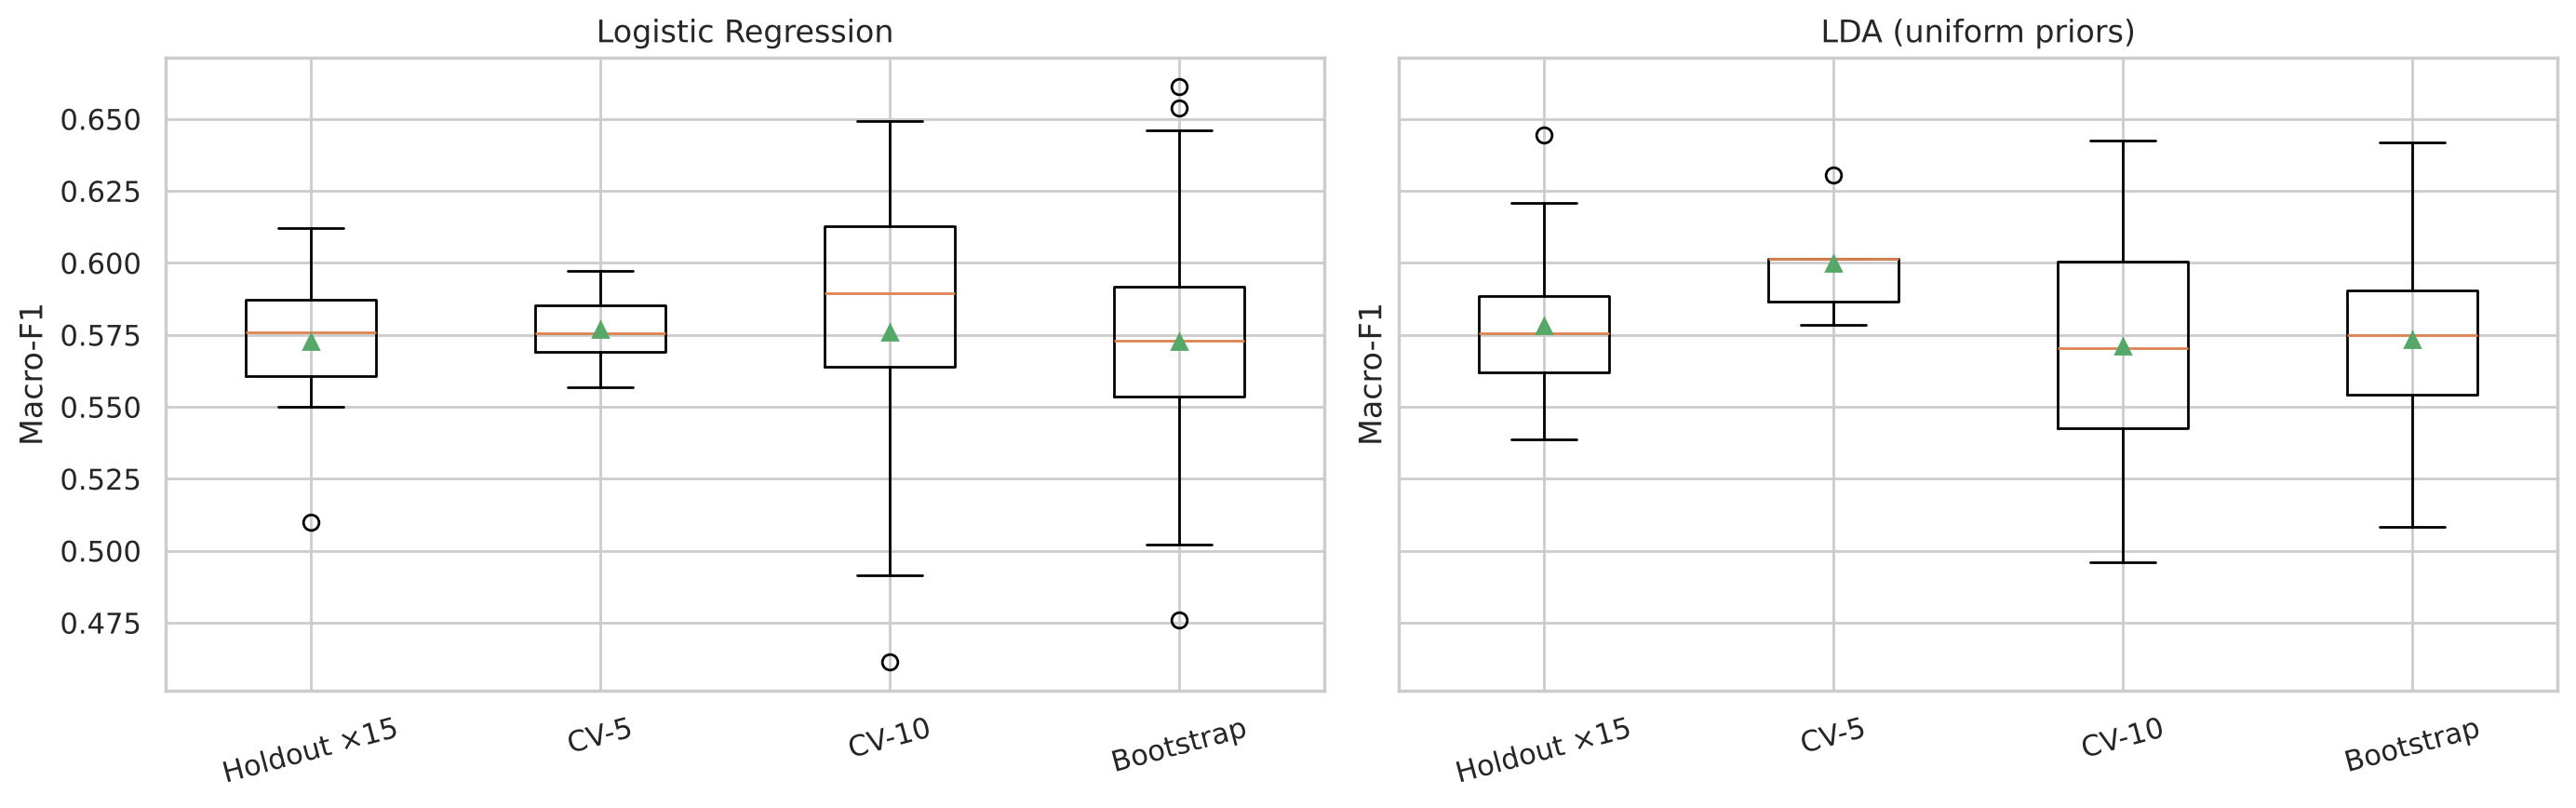

**Logistic Regression:** CV-5 mean macro-F1 **0.577** (SD **0.015**); CV-10 **0.576** (SD **0.059**); repeated holdout **0.573** (SD **0.025**); bootstrap OOB **0.573** (SD **0.029**); pooled LOOCV macro-F1 **0.576**. The smallest observed score SD among the repeated/fold-based procedures is **5-fold CV**, but comparisons of SD are **descriptive** because the procedures have different test-set sizes, training-set sizes and dependencies.

**LDA (uniform priors):** CV-5 mean macro-F1 **0.600** (SD **0.020**); CV-10 **0.571** (SD **0.044**); repeated holdout **0.578** (SD **0.028**); bootstrap OOB **0.573** (SD **0.026**); pooled LOOCV macro-F1 **0.576**. The smallest observed score SD among the repeated/fold-based procedures is **5-fold CV**, but comparisons of SD are **descriptive** because the procedures have different test-set sizes, training-set sizes and dependencies.

In [25]:
bootstrap_label = f'Bootstrap OOB ({BOOTSTRAP_REPEATS})'
variance_summary=pd.DataFrame(resample_rows).sort_values(['model','method']).reset_index(drop=True)
display(variance_summary.round(5))
fig, axs=plt.subplots(1,2,figsize=(14,4.5),sharey=True)
for ax,(label,_) in zip(axs,CLASSIFIERS.items()):
    samples=[resample_samples[(label,k)] for k in ['Repeated holdout (15)','5-fold CV','10-fold CV',bootstrap_label]]
    ax.boxplot(samples,tick_labels=['Holdout ×15','CV-5','CV-10','Bootstrap'],showmeans=True)
    ax.set_title(label);ax.set_ylabel('Macro-F1')
    ax.tick_params(axis='x',rotation=15)
plt.tight_layout();plt.show()
# Contextual observations derived from values, rather than unverified fixed text.
for modelname in CLASSIFIERS:
    section=variance_summary[variance_summary.model==modelname].set_index('method')
    best_variability=section['sd macro-F1'].idxmin()
    looval=float(loocv_table.set_index('model').loc[modelname,'LOOCV pooled macro-F1'])
    display(Markdown(f'''**{modelname}:** CV-5 mean macro-F1 **{section.loc['5-fold CV','mean macro-F1']:.3f}** (SD **{section.loc['5-fold CV','sd macro-F1']:.3f}**); CV-10 **{section.loc['10-fold CV','mean macro-F1']:.3f}** (SD **{section.loc['10-fold CV','sd macro-F1']:.3f}**); repeated holdout **{section.loc['Repeated holdout (15)','mean macro-F1']:.3f}** (SD **{section.loc['Repeated holdout (15)','sd macro-F1']:.3f}**); bootstrap OOB **{section.loc[bootstrap_label,'mean macro-F1']:.3f}** (SD **{section.loc[bootstrap_label,'sd macro-F1']:.3f}**); pooled LOOCV macro-F1 **{looval:.3f}**. The smallest observed score SD among the repeated/fold-based procedures is **{best_variability}**, but comparisons of SD are **descriptive** because the procedures have different test-set sizes, training-set sizes and dependencies.'''))

### 7.3 Stability of the model ranking across splits

Sections 6 and 8 both show a model that cross-validation prefers doing worse on the holdout. Before reading that as a fact about the models, we check whether it belongs to this particular split. We repeat the whole training-CV-plus-holdout procedure on independent partitions and compare the two quantities side by side.


In [26]:
# Repeat the full protocol on independent splits: is the CV-to-holdout gap systematic?
STABILITY_SEEDS = range(1, 21)
stability_rows = []
for seed in STABILITY_SEEDS:
    train_s, test_s = train_test_split(np.arange(len(df)), test_size=.20,
                                       stratify=df['target_class'], random_state=seed)
    X_a = df.loc[train_s, MODEL_FEATURES]
    X_b = df.loc[test_s, MODEL_FEATURES]
    y_a = df.loc[train_s, 'target_class']
    y_b = df.loc[test_s, 'target_class']
    folds_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    row = {'seed': seed}
    for name, estimator in CLASSIFIERS.items():
        cv_scores = cross_validate(full_pipeline(X_a, estimator), X_a, y_a, cv=folds_s,
                                   scoring='f1_macro', n_jobs=1)['test_score']
        fitted_s = full_pipeline(X_a, estimator).fit(X_a, y_a)
        row[f'{name} CV'] = cv_scores.mean()
        row[f'{name} holdout'] = f1_score(y_b, fitted_s.predict(X_b),
                                          average='macro', zero_division=0)
    stability_rows.append(row)
seed_table = pd.DataFrame(stability_rows)
display(seed_table.round(4))
display(seed_table.drop(columns='seed').agg(['mean', 'std', 'min', 'max']).round(4))

lda_gaps = seed_table[f'{LDA_MODEL} CV'] - seed_table[f'{LDA_MODEL} holdout']
logreg_gaps = seed_table[f'{LOGREG} CV'] - seed_table[f'{LOGREG} holdout']
lda_gap_mean = lda_gaps.mean()
lda_gap_sd = lda_gaps.std(ddof=1)
logreg_gap_mean = logreg_gaps.mean()

cv_prefers_lda = seed_table[f'{LDA_MODEL} CV'] > seed_table[f'{LOGREG} CV']
holdout_prefers_lda = seed_table[f'{LDA_MODEL} holdout'] > seed_table[f'{LOGREG} holdout']
n_agree = int((cv_prefers_lda == holdout_prefers_lda).sum())
n_seeds = len(seed_table)

lda_cv_across_seeds = seed_table[f'{LDA_MODEL} CV'].mean()
lda_cv_sd_across_seeds = seed_table[f'{LDA_MODEL} CV'].std(ddof=1)
our_gap = lda_cv_f1 - lda_holdout['macro-F1']
holdout_columns = [f'{name} holdout' for name in CLASSIFIERS]
plateau = seed_table[holdout_columns].to_numpy().mean()

display(Markdown(f"""**Observed result.** Over {n_seeds} independent splits the mean CV-minus-holdout
difference is {lda_gap_mean:+.4f} for LDA, with a standard deviation of {lda_gap_sd:.4f}, and
{logreg_gap_mean:+.4f} for Logistic Regression. Our cross-validation estimates carry no systematic
optimism. The gap of {our_gap:+.4f} on our own split, reported in Section 6.1, is an unusually large draw:
the cross-validation score on this partition ({lda_cv_f1:.4f}) sits well above the {n_seeds}-split mean of
{lda_cv_across_seeds:.4f}, whose standard deviation is {lda_cv_sd_across_seeds:.4f}.

**Consequence for model selection.** Cross-validation and the holdout picked the same winner in only
{n_agree} of {n_seeds} splits. Together with the overlapping intervals in Section 6.4, this means the
dataset cannot identify a ranking between the two classifiers the assignment specifies. Both settle around
macro-F1 {plateau:.3f}, and the partition decides which one looks better. We report that instead of a
ranking that fails to reproduce, and we keep the model chosen by cross-validation because selecting on
training data is the correct procedure, which is a separate question from whether it is the better
model."""))


,seed,Logistic Regression CV,Logistic Regression holdout,LDA (uniform priors) CV,LDA (uniform priors) holdout
0,1,0.5334,0.5633,0.5375,0.5459
1,2,0.5580,0.5283,0.5646,0.5243
2,3,0.5245,0.5036,0.5291,0.5343
3,4,0.5464,0.5471,0.5319,0.5680
4,5,0.5395,0.5656,0.5448,0.5279
5,6,0.5596,0.5434,0.5554,0.5310
6,7,0.5456,0.5869,0.5522,0.5502
7,8,0.5676,0.5352,0.5597,0.5109
8,9,0.5659,0.4976,0.5642,0.5055
9,10,0.5401,0.5418,0.5565,0.5705


,Logistic Regression CV,Logistic Regression holdout,LDA (uniform priors) CV,LDA (uniform priors) holdout
mean,0.5454,0.5496,0.5476,0.5471
std,0.0132,0.0244,0.0117,0.0248
min,0.5213,0.4976,0.5291,0.5055
max,0.5676,0.5882,0.5669,0.5946


**Observed result.** Over 20 independent splits the mean CV-minus-holdout
difference is +0.0005 for LDA, with a standard deviation of 0.0323, and
-0.0042 for Logistic Regression. Our cross-validation estimates carry no systematic
optimism. The gap of +0.0757 on our own split, reported in Section 6.1, is an unusually large draw:
the cross-validation score on this partition (0.5997) sits well above the 20-split mean of
0.5476, whose standard deviation is 0.0117.

**Consequence for model selection.** Cross-validation and the holdout picked the same winner in only
8 of 20 splits. Together with the overlapping intervals in Section 6.4, this means the
dataset cannot identify a ranking between the two classifiers the assignment specifies. Both settle around
macro-F1 0.548, and the partition decides which one looks better. We report that instead of a
ranking that fails to reproduce, and we keep the model chosen by cross-validation because selecting on
training data is the correct procedure, which is a separate question from whether it is the better
model.

## 8. Classification feature selection — Ridge and Lasso principles (task 5)

**Research question.** Can a substantially reduced set of encoded features maintain multiclass classification performance?

**Approach.** For classification we compare L2-penalised Logistic Regression (Ridge-style shrinkage), one-versus-rest L1-penalised Logistic Regression (Lasso-style sparsity), and L1 feature selection followed by L2 Logistic Regression. The L1 sparse estimator is one-vs-rest with `liblinear`, whereas the L2 estimator is multinomial with `lbfgs`, so these models differ in more than just the penalty. All scaling, imputation, encoding and supervised feature selection remain **inside the CV pipelines**.

Instead of choosing regularisation `C` by hand, we tune its inverse penalty strength using **stratified training-only 5-fold cross-validation** and macro-F1. For a deliberately compact model we cap the reduced selector at **20 encoded features** (a pre-defined interpretability budget); individual categories may expand into multiple encoded columns. Hyperparameter selection and performance estimation on the same CV splits can be optimistic, so the held-out test set is used **only once** for the final comparison, with no further tuning based on its results. We report both performance and selected-feature counts.


,variant,CV macro-F1,CV macro-F1 sd,best C
0,All: Logistic L2 (Ridge-style),0.5848,0.0161,0.6
1,All: OvR Logistic L1 (Lasso-style),0.5827,0.0101,2.0
2,Reduced: L1-select then Logistic L2,0.5796,0.0256,0.3


Selected based on training CV: All: Logistic L2 (Ridge-style)
Chosen C: L2 = 0.6 | Full L1 = 2.0 | L1 selector = 0.3


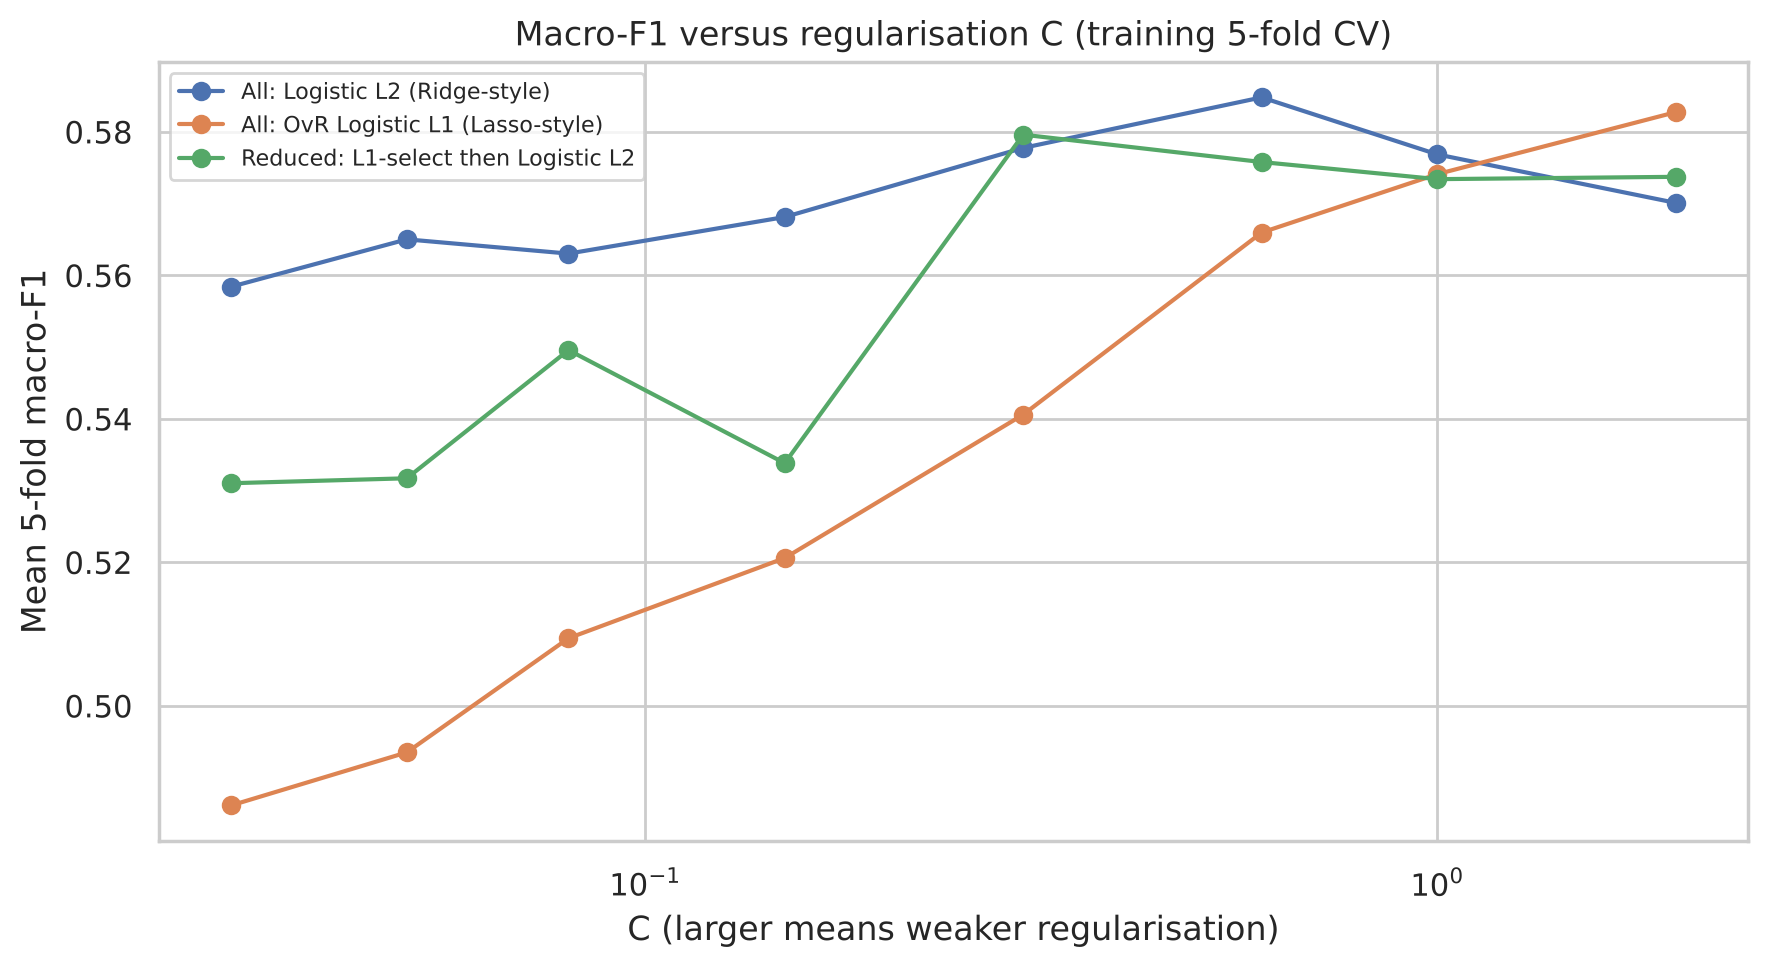

,C,selected encoded columns
0,0.03,6
1,0.05,19
2,0.08,20
3,0.15,20
4,0.30,20
5,0.60,20
6,1.00,20
7,2.00,20


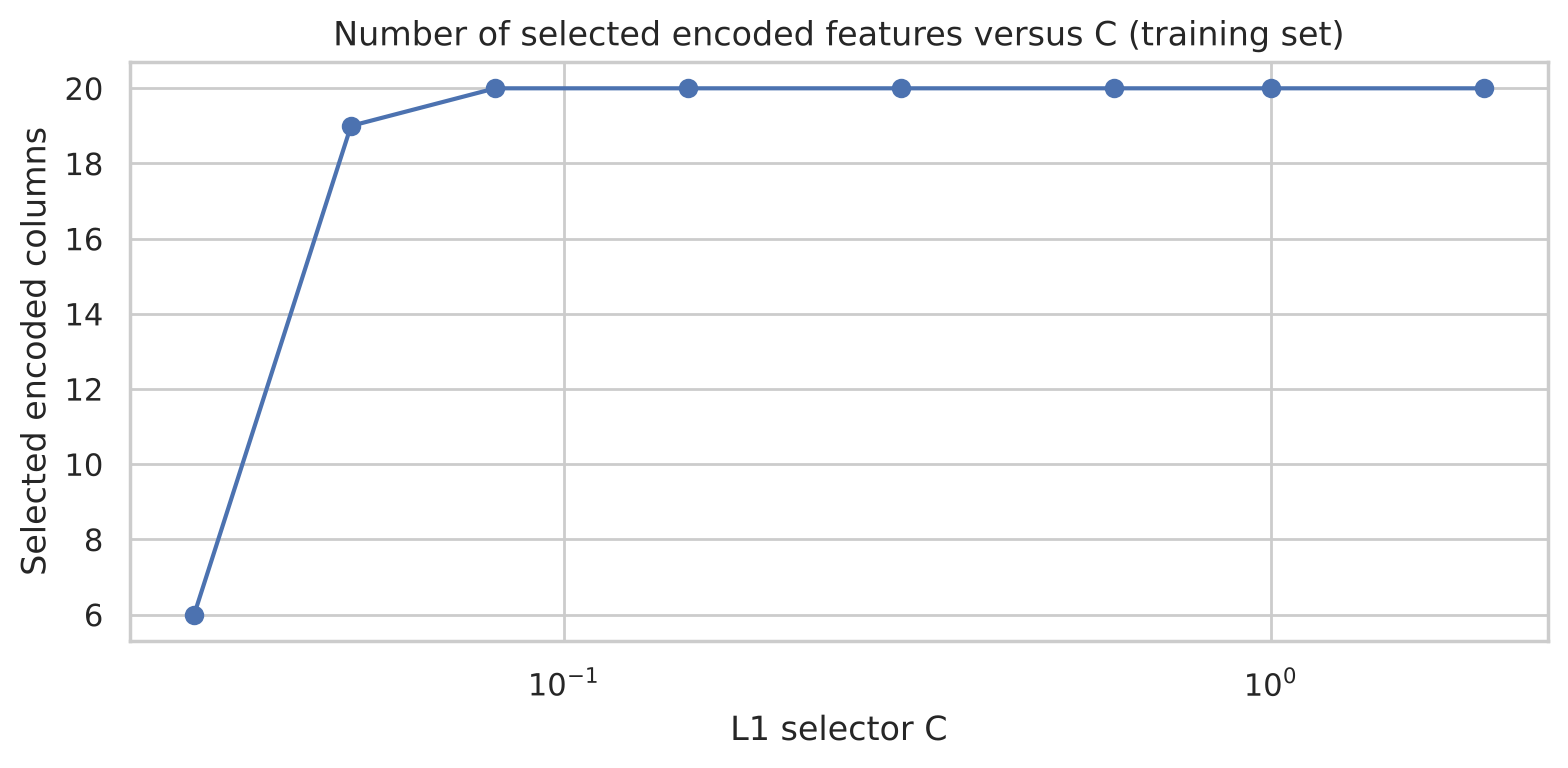

In [27]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV

class OvRL1(ClassifierMixin, BaseEstimator):
    """One-vs-rest L1 logistic classifiers exposing merged coefficients for selection."""
    def __init__(self, C=0.15, seed=26):
        self.C = C
        self.seed = seed
    def fit(self, X, y):
        base = LogisticRegression(penalty='l1', C=self.C, solver='liblinear',
                                  class_weight='balanced', max_iter=1500,
                                  random_state=self.seed)
        self.ovr_ = OneVsRestClassifier(base).fit(X, y)
        self.classes_ = self.ovr_.classes_
        self.coef_ = np.vstack([est.coef_[0] for est in self.ovr_.estimators_])
        return self
    def predict(self, X):
        return self.ovr_.predict(X)

# Candidate C values were fixed before the final holdout evaluation.
C_VALUES = [0.03, 0.05, 0.08, 0.15, 0.3, 0.6, 1.0, 2.0]

l2_template = LogisticRegression(penalty='l2', solver='lbfgs',
                                 class_weight='balanced', max_iter=4000)

# Tune a full-feature L2 reference.
l2_search = GridSearchCV(full_pipeline(X_train, clone(l2_template)),
                         param_grid={'model__C': C_VALUES}, cv=cls_cv5,
                         scoring='f1_macro', n_jobs=1)
l2_search.fit(X_train, ycls_train)
C_L2 = l2_search.best_params_['model__C']
l2 = clone(l2_template).set_params(C=C_L2)

# Tune the full one-versus-rest L1 logistic model.
l1_search = GridSearchCV(full_pipeline(X_train, OvRL1(seed=SEED)),
                         param_grid={'model__C': C_VALUES}, cv=cls_cv5,
                         scoring='f1_macro', n_jobs=1)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='.*penalty.*deprecated.*')
    l1_search.fit(X_train, ycls_train)
C_L1 = l1_search.best_params_['model__C']
l1 = OvRL1(C=C_L1, seed=SEED)

# CV feature selection is refitted inside each fold. Max. 20 encoded features.
reduced_template = Pipeline([
    ('prepare', preprocessor(X_train)),
    ('select', SelectFromModel(OvRL1(seed=SEED), threshold=1e-6, max_features=20)),
    ('model', clone(l2))
])
selector_search = GridSearchCV(reduced_template,
                               param_grid={'select__estimator__C': C_VALUES},
                               cv=cls_cv5, scoring='f1_macro', n_jobs=1)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='.*penalty.*deprecated.*')
    selector_search.fit(X_train, ycls_train)
C_SELECTOR = selector_search.best_params_['select__estimator__C']

feature_models = {
    'All: Logistic L2 (Ridge-style)': full_pipeline(X_train, l2),
    'All: OvR Logistic L1 (Lasso-style)': full_pipeline(X_train, l1),
    'Reduced: L1-select then Logistic L2': clone(reduced_template).set_params(select__estimator__C=C_SELECTOR)
}

# Scores for tuned candidates are CV scores used for selection (not independent
# estimates of the tuning procedure's performance).
searches = {
    'All: Logistic L2 (Ridge-style)': l2_search,
    'All: OvR Logistic L1 (Lasso-style)': l1_search,
    'Reduced: L1-select then Logistic L2': selector_search
}
feature_cv=[]
for label, search in searches.items():
    feature_cv.append({'variant': label,
                       'CV macro-F1': search.best_score_,
                       'CV macro-F1 sd': search.cv_results_['std_test_score'][search.best_index_],
                       'best C': search.best_params_[list(search.best_params_)[0]]})
feature_cv_table = pd.DataFrame(feature_cv).sort_values('CV macro-F1', ascending=False)
display(feature_cv_table.round(4))
selected_feature_model = feature_cv_table.iloc[0]['variant']
print('Selected based on training CV:', selected_feature_model)
print('Chosen C: L2 =', C_L2, '| Full L1 =', C_L1, '| L1 selector =', C_SELECTOR)

# Validation curves across candidate penalties.
fig, ax = plt.subplots(figsize=(9,5))
for label, search in searches.items():
    scores = search.cv_results_['mean_test_score']
    ax.semilogx(C_VALUES, scores, marker='o', label=label)
ax.set(title='Macro-F1 versus regularisation C (training 5-fold CV)',
       xlabel='C (larger means weaker regularisation)', ylabel='Mean 5-fold macro-F1')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Counts of selected encoded columns for each C, fitted using training data only.
feature_counts = []
for c in C_VALUES:
    selector_test = clone(reduced_template).set_params(select__estimator__C=c)
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='.*penalty.*deprecated.*')
        selector_test.fit(X_train, ycls_train)
    feature_counts.append({'C': c,
                           'selected encoded columns': int(selector_test.named_steps['select'].get_support().sum())})
counts_by_c = pd.DataFrame(feature_counts)
display(counts_by_c)
fig, ax = plt.subplots(figsize=(8,4))
ax.semilogx(counts_by_c['C'], counts_by_c['selected encoded columns'], marker='o')
ax.set(title='Number of selected encoded features versus C (training set)',
       xlabel='L1 selector C', ylabel='Selected encoded columns')
plt.tight_layout(); plt.show()


In [28]:
feature_holdout=[]
fit_feature_models={}
for label,model in feature_models.items():
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore',message='.*penalty.*deprecated.*')
        warnings.filterwarnings('ignore',message='Inconsistent values: penalty.*')
        fitted=clone(model).fit(X_train,ycls_train)
    fit_feature_models[label]=fitted
    predicted=fitted.predict(X_test)
    feature_holdout.append({'variant':label,
                            'holdout macro-F1':f1_score(ycls_test,predicted,average='macro',zero_division=0),
                            'holdout balanced acc.':balanced_accuracy_score(ycls_test,predicted),
                            'holdout accuracy':accuracy_score(ycls_test,predicted)})
feature_holdout_table=pd.DataFrame(feature_holdout).sort_values('holdout macro-F1',ascending=False)
display(feature_holdout_table.round(4))
# Inspect which encoded features were retained by the L1 selector fitted on training only.
selected_pipe=fit_feature_models['Reduced: L1-select then Logistic L2']
encoded_names=selected_pipe.named_steps['prepare'].get_feature_names_out()
keep_mask=selected_pipe.named_steps['select'].get_support()
selected_encoded=encoded_names[keep_mask]
selected_encoded_table=pd.DataFrame({'selected encoded feature':selected_encoded})
print(f'Selected {int(keep_mask.sum())} of {len(encoded_names)} encoded features; '
      f'{len(MODEL_FEATURES)} original input columns before encoding.')
display(selected_encoded_table)
# Report L1 sparsity without confusing encoded columns with original variables.
fit_l1=fit_feature_models['All: OvR Logistic L1 (Lasso-style)']
l1_coeff=fit_l1.named_steps['model'].coef_
active_cols=(np.abs(l1_coeff)>1e-6).any(axis=0)
print('L1 nonzero encoded feature columns:',active_cols.sum(),'/',l1_coeff.shape[1])
chosen_holdout=feature_holdout_table.set_index('variant').loc[selected_feature_model]
display(Markdown(f'''**Observed result.** The best regularized variant by 5-fold training macro-F1 was **{selected_feature_model}**. Its separate holdout macro-F1 was **{chosen_holdout['holdout macro-F1']:.3f}** (balanced accuracy **{chosen_holdout['holdout balanced acc.']:.3f}**). With L1-selection, the reduced model retained **{keep_mask.sum()} / {len(encoded_names)} encoded columns**. Because categorical inputs expand to multiple dummy columns, this count is **not** the number of original clinical variables. This experiment tests whether sparse classification can match the full-feature baseline; a smaller subset is not automatically more accurate.'''))

,variant,holdout macro-F1,holdout balanced acc.,holdout accuracy
2,Reduced: L1-select then Logistic L2,0.5430,0.5812,0.540
1,All: OvR Logistic L1 (Lasso-style),0.5283,0.5445,0.525
0,All: Logistic L2 (Ridge-style),0.5212,0.5445,0.520


Selected 20 of 40 encoded features; 30 original input columns before encoding.


,selected encoded feature
0,num__age
1,num__bmi
2,num__HbA1c_level
3,num__triglycerides
4,num__ldl
5,cat__age_level_Middle
6,cat__age_level_Senior
7,cat__bmi_level_Obese
8,cat__bmi_level_Overweight
9,cat__bmi_level_Underweight


L1 nonzero encoded feature columns: 40 / 40


**Observed result.** The best regularized variant by 5-fold training macro-F1 was **All: Logistic L2 (Ridge-style)**. Its separate holdout macro-F1 was **0.521** (balanced accuracy **0.544**). With L1-selection, the reduced model retained **20 / 40 encoded columns**. Because categorical inputs expand to multiple dummy columns, this count is **not** the number of original clinical variables. This experiment tests whether sparse classification can match the full-feature baseline; a smaller subset is not automatically more accurate.

### 8.1 Does the reduced set beat the full set by more than split-to-split noise?

The holdout ranking above favours the reduced model, but Section 6.4 showed that a single 400-patient holdout cannot resolve differences of this size. We repeat the full-versus-reduced comparison across independent splits and report whichever conclusion survives it.


In [29]:
# Full-feature L2 against the L1-selected reduced model, across independent splits.
SELECTION_SEEDS = range(1, 21)
encoded_total = len(preprocessor(X_train).fit(X_train).get_feature_names_out())
selection_rows = []
for seed in SELECTION_SEEDS:
    train_s, test_s = train_test_split(np.arange(len(df)), test_size=.20,
                                       stratify=df['target_class'], random_state=seed)
    X_a = df.loc[train_s, MODEL_FEATURES]
    X_b = df.loc[test_s, MODEL_FEATURES]
    y_a = df.loc[train_s, 'target_class']
    y_b = df.loc[test_s, 'target_class']
    reduced_s = Pipeline([
        ('prepare', preprocessor(X_a)),
        ('select', SelectFromModel(OvRL1(C=C_SELECTOR, seed=seed),
                                   threshold=1e-6, max_features=20)),
        ('model', clone(l2))])
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        full_s = full_pipeline(X_a, clone(l2)).fit(X_a, y_a)
        reduced_s.fit(X_a, y_a)
    selection_rows.append({
        'seed': seed,
        'full L2': f1_score(y_b, full_s.predict(X_b), average='macro', zero_division=0),
        'reduced': f1_score(y_b, reduced_s.predict(X_b), average='macro', zero_division=0)})
selection_table = pd.DataFrame(selection_rows)
display(selection_table.round(4))
display(selection_table[['full L2', 'reduced']].agg(['mean', 'std', 'min', 'max']).round(4))

selection_gap = selection_table['reduced'] - selection_table['full L2']
reduced_wins = int((selection_gap > 0).sum())
n_selection_seeds = len(selection_table)
selection_t, selection_p = ttest_rel(selection_table['reduced'], selection_table['full L2'])

display(Markdown(f"""**Observed result.** Across {n_selection_seeds} independent splits the reduced model
won {reduced_wins} times, with a mean difference of {selection_gap.mean():+.4f} macro-F1 (paired t-test
t = {selection_t:.3f}, p = {selection_p:.4f}). The single-split ranking above overstates the case: the two
feature sets perform the same, and the advantage visible on our holdout falls inside split-to-split noise.

**Decision for the remaining tasks.** We still carry the reduced set forward. The assignment requires the
later tasks to use the most relevant predictors identified here, and matching the full model with 20
encoded columns in place of {encoded_total} is a gain in parsimony and in how readable the model is. We
justify the choice on those grounds, which is what the evidence supports, and make no claim of better
predictive performance."""))


,seed,full L2,reduced
0,1,0.5647,0.5462
1,2,0.5298,0.5851
2,3,0.5036,0.5436
3,4,0.5464,0.5760
4,5,0.5589,0.5568
5,6,0.5471,0.5470
6,7,0.5842,0.5634
7,8,0.5377,0.5482
8,9,0.4970,0.5088
9,10,0.5557,0.5593


,full L2,reduced
mean,0.5511,0.5586
std,0.0243,0.0247
min,0.4970,0.5088
max,0.5842,0.6161


**Observed result.** Across 20 independent splits the reduced model
won 12 times, with a mean difference of +0.0075 macro-F1 (paired t-test
t = 1.535, p = 0.1412). The single-split ranking above overstates the case: the two
feature sets perform the same, and the advantage visible on our holdout falls inside split-to-split noise.

**Decision for the remaining tasks.** We still carry the reduced set forward. The assignment requires the
later tasks to use the most relevant predictors identified here, and matching the full model with 20
encoded columns in place of 40 is a gain in parsimony and in how readable the model is. We
justify the choice on those grounds, which is what the evidence supports, and make no claim of better
predictive performance.

## 9. Overall conclusions, limitations and critical discussion

**Approach.** We integrate the metrics across the assignment rather than selecting whichever individual number looks strongest. The central goal is to identify which methods generalize, how much the minority diagnosis affects their evaluation, and whether the regression target contains meaningful linear signal. The paragraph below is **generated from the results actually computed in this notebook**, so re-running with the same dataset regenerates consistent numerical statements.

In [30]:
reg_baseline = reg_compare.set_index('model').loc['Training-mean baseline']
reg_simple = reg_compare.iloc[1]
reg_multi = reg_compare.iloc[2]
cv_model_scores = class_cv_table.set_index('model')
holdout_model_scores=cls_holdout_table.set_index('model')
selectCV = cv_model_scores.loc[selected_classifier_name]
selectTest = holdout_model_scores.loc[selected_classifier_name]
lfull=feature_holdout_table.set_index('variant').loc['All: Logistic L2 (Ridge-style)']
lred=feature_holdout_table.set_index('variant').loc['Reduced: L1-select then Logistic L2']
label_reg = ('improved on' if reg_multi.RMSE < reg_baseline.RMSE else 'did not improve on')
label_sparse = ('improved' if lred['holdout macro-F1']>lfull['holdout macro-F1'] else 'did not improve')
report = f'''### 9.1 Integrated results (generated from this run)

**Dataset and EDA.** We analysed {len(df):,} patient profiles with {df.shape[1]} columns and {len(class_counts)} diagnostic classes. No missing values or exact duplicated observations were detected. The class distribution is strongly skewed: {class_counts.index[0]} accounts for {class_share.iloc[0]:.2f}% and {minority} for {class_share.iloc[-1]:.2f}% of the dataset. We removed a constant feature and two essentially redundant measurements before fitting models. The within-class standard deviations differed greatly across diagnostic categories, particularly for `HT_HY`; this may reflect source-specific preprocessing and makes the LDA shared-covariance assumption questionable. Derived age and BMI categories are also partially redundant with their continuous counterparts. The low-HDL indicator disagrees with a simple HDL < 40 rule for {len(hdl_mismatch)} records; its actual encoding rule is unknown.

**Regression.** Training 5-fold cross-validation selected **{best_single}** as the best single numeric predictor and **{best_multiple}** as the preferred multiple linear feature set. On independent holdout data, the simple model achieved R² {reg_simple.R2:.3f}, MAE {reg_simple.MAE:.2f} and RMSE {reg_simple.RMSE:.2f}; the multiple model achieved R² {reg_multi.R2:.3f}, MAE {reg_multi.MAE:.2f} and RMSE {reg_multi.RMSE:.2f}. The mean-predicting baseline RMSE was {reg_baseline.RMSE:.2f}; the multiple model **{label_reg}** that reference on the held-out patients. These results must be discussed in the context of the weak individual linear correlations; they do not support strong clinical prediction claims.

**Classification.** The preferred unregularized classifier based on training macro-F1 was **{selected_classifier_name}** (5-fold CV macro-F1 {selectCV['CV macro-F1']:.3f}). Its independent holdout macro-F1 was {selectTest['macro-F1']:.3f}, balanced accuracy {selectTest['balanced accuracy']:.3f}, and accuracy {selectTest['accuracy']:.3f}. The rare diagnosis {minority} was recalled in {minority_recall[selected_classifier_name]:.1%} of its holdout cases. The sensitivity analysis of LDA with empirical versus uniform priors showed the effect of class prevalence assumptions on the predictions. The confusion matrices and class-specific metrics, not accuracy alone, determine how defensible the prediction results are.

**Resampling and variance.** Full LOOCV on all {len(X_train)} training patients supplied pooled out-of-fold predictions, while 5-fold CV, 10-fold CV, repeated holdout and bootstrap OOB yielded distributions of macro-F1 scores. Their standard deviations demonstrate sensitivity to training/validation sampling, but are not directly interchangeable estimators of model variance because assessment-set sizes and dependence patterns differ. LOOCV's single-observation folds have **no meaningful fold-level macro-F1 variance**.

**L1/L2 feature selection.** Cross-validation selected C = {C_L2:g} (L2), {C_L1:g} (full L1) and {C_SELECTOR:g} (L1 selector). The L1-based selector retained {int(keep_mask.sum())} of {len(encoded_names)} encoded columns and **{label_sparse}** the full L2 model's holdout macro-F1 ({lred['holdout macro-F1']:.3f} vs. {lfull['holdout macro-F1']:.3f}). This comparison is a check of the performance/interpretability trade-off, not evidence that the selected features are causal disease mechanisms.

### 9.2 Limitations and ethical considerations

- **Observational and curated data:** Associations cannot establish causality. Unknown sampling or label-generation processes may limit generalisation beyond this cohort.
- **Minority support:** Only {int(class_counts.iloc[-1])} patients belong to {minority} (and only {int((ycls_test==minority).sum())} are in the final test). Minority recall estimates are therefore unstable.
- **Ambiguous target semantics:** The assignment does not formally define diagnostic code expansions or the physical unit of `target_regression`. We avoid inferring those clinical meanings.
- **Model assumptions:** Linear regression can miss nonlinear effects. LDA assumes a shared class-conditional covariance matrix; extreme differences in within-class dispersion question this assumption. Shrinkage improves numerical stability but does not eliminate covariance heterogeneity.
- **Selection and evaluation:** We used one untouched holdout and training-only CV. The same five folds are used to tune `C` and report the selected CV score, so those scores may be optimistic; a nested CV could estimate the complete tuning procedure more reliably. All final model variants are compared descriptively on the same holdout and were not tuned using that holdout. Bootstrap and repeated holdout evaluations reuse observations and must not be mistaken for fully independent replications.
- **Responsible use:** These academic models are not validated for clinical diagnosis or patient management and should not be used for medical decisions.

### 9.3 Main takeaway
Our evaluation demonstrates the necessity of reporting **out-of-sample metrics, per-class performance, and uncertainty**. The preferable method is the one with the best defensible validation behaviour under the chosen metric, not simply the highest apparent training accuracy. A low predictive score is a valid scientific result when identified and discussed transparently.'''
display(Markdown(report))

### 9.1 Integrated results (generated from this run)

**Dataset and EDA.** We analysed 2,000 patient profiles with 35 columns and 3 diagnostic classes. No missing values or exact duplicated observations were detected. The class distribution is strongly skewed: DI_HY accounts for 64.35% and HT_HY for 3.45% of the dataset. We removed a constant feature and two essentially redundant measurements before fitting models. The within-class standard deviations differed greatly across diagnostic categories, particularly for `HT_HY`; this may reflect source-specific preprocessing and makes the LDA shared-covariance assumption questionable. Derived age and BMI categories are also partially redundant with their continuous counterparts. The low-HDL indicator disagrees with a simple HDL < 40 rule for 115 records; its actual encoding rule is unknown.

**Regression.** Training 5-fold cross-validation selected **bmi** as the best single numeric predictor and **Top 2 numeric** as the preferred multiple linear feature set. On independent holdout data, the simple model achieved R² 0.003, MAE 32.19 and RMSE 38.89; the multiple model achieved R² 0.004, MAE 32.19 and RMSE 38.87. The mean-predicting baseline RMSE was 39.00; the multiple model **improved on** that reference on the held-out patients. These results must be discussed in the context of the weak individual linear correlations; they do not support strong clinical prediction claims.

**Classification.** The preferred unregularized classifier based on training macro-F1 was **LDA (uniform priors)** (5-fold CV macro-F1 0.600). Its independent holdout macro-F1 was 0.524, balanced accuracy 0.543, and accuracy 0.510. The rare diagnosis HT_HY was recalled in 64.3% of its holdout cases. The sensitivity analysis of LDA with empirical versus uniform priors showed the effect of class prevalence assumptions on the predictions. The confusion matrices and class-specific metrics, not accuracy alone, determine how defensible the prediction results are.

**Resampling and variance.** Full LOOCV on all 1600 training patients supplied pooled out-of-fold predictions, while 5-fold CV, 10-fold CV, repeated holdout and bootstrap OOB yielded distributions of macro-F1 scores. Their standard deviations demonstrate sensitivity to training/validation sampling, but are not directly interchangeable estimators of model variance because assessment-set sizes and dependence patterns differ. LOOCV's single-observation folds have **no meaningful fold-level macro-F1 variance**.

**L1/L2 feature selection.** Cross-validation selected C = 0.6 (L2), 2 (full L1) and 0.3 (L1 selector). The L1-based selector retained 20 of 40 encoded columns and **improved** the full L2 model's holdout macro-F1 (0.543 vs. 0.521). This comparison is a check of the performance/interpretability trade-off, not evidence that the selected features are causal disease mechanisms.

### 9.2 Limitations and ethical considerations

- **Observational and curated data:** Associations cannot establish causality. Unknown sampling or label-generation processes may limit generalisation beyond this cohort.
- **Minority support:** Only 69 patients belong to HT_HY (and only 14 are in the final test). Minority recall estimates are therefore unstable.
- **Ambiguous target semantics:** The assignment does not formally define diagnostic code expansions or the physical unit of `target_regression`. We avoid inferring those clinical meanings.
- **Model assumptions:** Linear regression can miss nonlinear effects. LDA assumes a shared class-conditional covariance matrix; extreme differences in within-class dispersion question this assumption. Shrinkage improves numerical stability but does not eliminate covariance heterogeneity.
- **Selection and evaluation:** We used one untouched holdout and training-only CV. The same five folds are used to tune `C` and report the selected CV score, so those scores may be optimistic; a nested CV could estimate the complete tuning procedure more reliably. All final model variants are compared descriptively on the same holdout and were not tuned using that holdout. Bootstrap and repeated holdout evaluations reuse observations and must not be mistaken for fully independent replications.
- **Responsible use:** These academic models are not validated for clinical diagnosis or patient management and should not be used for medical decisions.

### 9.3 Main takeaway
Our evaluation demonstrates the necessity of reporting **out-of-sample metrics, per-class performance, and uncertainty**. The preferable method is the one with the best defensible validation behaviour under the chosen metric, not simply the highest apparent training accuracy. A low predictive score is a valid scientific result when identified and discussed transparently.

### 9.4 Two structural findings that condition the conclusions above

Two properties of this dataset limit what the numbers above can mean. Both were measured in earlier sections and are collected here because they govern how the results should be read.


In [31]:
compressed_share = FROZEN_REGIME.mean()
dispersed_share = 1 - compressed_share
rare_compressed_count = int(((df['target_class'] == rare) & FROZEN_REGIME).sum())

display(Markdown(f"""**Finding 1: the rare class is separable by an artefact of how the data was built.**
Section 2.2.1 showed that all {rare_compressed_count} `{rare}` patients fall inside a group of
{n_compressed} records, {compressed_share:.1%} of the cohort, where seven physiological measurements sit at
the dataset mean, and that no record outside that group carries the label. Any classifier can rule
`{rare}` out for {dispersed_share:.0%} of patients on structural grounds alone. We therefore make no claim
of clinical predictability for `{rare}`: its apparent separability describes how this cohort was assembled
and would not survive on real screening data. `DI` and `DI_HY` span both groups, so this reservation
applies to them far less.

**Finding 2: the limit lies in the kind of model, not in how it was estimated.** Section 7.3 found the gap
between cross-validation and holdout to be {lda_gap_mean:+.4f} on average for LDA over {n_seeds}
independent splits, which is no systematic bias. Section 6.4 found the two classifiers the assignment
specifies to be statistically indistinguishable on these data, and both settle near macro-F1
{plateau:.2f}. Section 5.1 found the same shape in the regression task: cutting a predictor into deciles
and refitting the same linear model moves `hdl` from R² {hdl_lin:+.4f} to {hdl_bin:+.4f}, so the weak
linear fit understates the dependence that is present.

**What this implies.** The ceiling we measure follows from fitting one linear boundary to a cohort made
of two groups with opposite covariance structures, and not from an absence of information in the data.
A model able to represent that structure should clear this plateau, and the gain should come mostly from
`{rare}` and `DI_HY` rather than from `DI`."""))


**Finding 1: the rare class is separable by an artefact of how the data was built.**
Section 2.2.1 showed that all 69 `HT_HY` patients fall inside a group of
284 records, 14.2% of the cohort, where seven physiological measurements sit at
the dataset mean, and that no record outside that group carries the label. Any classifier can rule
`HT_HY` out for 86% of patients on structural grounds alone. We therefore make no claim
of clinical predictability for `HT_HY`: its apparent separability describes how this cohort was assembled
and would not survive on real screening data. `DI` and `DI_HY` span both groups, so this reservation
applies to them far less.

**Finding 2: the limit lies in the kind of model, not in how it was estimated.** Section 7.3 found the gap
between cross-validation and holdout to be +0.0005 on average for LDA over 20
independent splits, which is no systematic bias. Section 6.4 found the two classifiers the assignment
specifies to be statistically indistinguishable on these data, and both settle near macro-F1
0.55. Section 5.1 found the same shape in the regression task: cutting a predictor into deciles
and refitting the same linear model moves `hdl` from R² -0.0037 to +0.0289, so the weak
linear fit understates the dependence that is present.

**What this implies.** The ceiling we measure follows from fitting one linear boundary to a cohort made
of two groups with opposite covariance structures, and not from an absence of information in the data.
A model able to represent that structure should clear this plateau, and the gain should come mostly from
`HT_HY` and `DI_HY` rather than from `DI`.

## 10. References and reproducibility

### Source material
1. **ISEP — APRAU (2026/2027)**, *Trabalho_APRAU_2026_27_step1.pdf*, tasks 2 to 6. Official assignment, dataset schema, required models and submission rules.
2. **Elsa Ferreira Gomes (2026/2027)**, *T2_LinearRegression_v0.pdf*, simple and multiple linear regression and R².
3. **Elsa Ferreira Gomes (2026/2027)**, *T3_Classification_RL_LDA.pdf*, Logistic Regression and Linear Discriminant Analysis.
4. **Elsa Ferreira Gomes (2026/2027)**, *T4_EvaluationResampling.pdf*, holdout, k-fold CV, LOOCV and bootstrap.
5. **Elsa Ferreira Gomes (2026/2027)**, *T5_RidgeLasso.pdf*, regularisation and the L1/L2 feature-selection distinction.
6. **Elsa Ferreira Gomes (2026/2027)**, *ClassificationMetrics.pdf*, confusion matrices and classification metrics.
7. James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023), *An Introduction to Statistical Learning with Applications in Python*, Springer. https://www.statlearning.com/.
8. scikit-learn developers, *User Guide*, https://scikit-learn.org/stable/user_guide.html; pandas developers, *Documentation*, https://pandas.pydata.org/docs/.

### Reproducibility

The analyses use the fixed random seed `SEED = 26`, stratified training/holdout partitions and training-only model selection. Preprocessing and supervised variable selection are part of scikit-learn pipelines. The notebook reads `data/dataset_grupo_26.csv` from a relative path, with a fallback from the `notebooks/` directory. The full LOOCV and bootstrap experiments are computationally intensive. The experimental interpretations are descriptive and should not be regarded as validated clinical advice.
